# Developmental Project - Supplementary - Longitudinal Sample

Includes p3_main.ipynb script but on a subsample of subjects with longitudinal data (2+ timepoints) 
- Computation of S-A axis and features of S-A axis development
-  Plotting (Figures 1 & 2)
-  FC strength computation

## Load Packages

In [1]:
# General
import os
import sys
import numpy as np
import pandas as pd
import csv
import math
from math import isnan
import statistics
import pickle
from collections import Counter

# Computing / Analyses
import scipy.io  # loadmat
import hdf5storage  # hdf5storage to write in HDF5 format (instead of .mat file, when matrix is too large) -> hdf5storage.write() hdf5storage.read()
import fnmatch # for comparing patterns of syntax
from scipy import stats
import sklearn 
from brainstat.stats.terms import FixedEffect
from brainstat.stats.SLM import SLM
from statsmodels.stats.multitest import fdrcorrection # does not yield exactly the same FDR correction as R but the same up to 14th decimal place so good enough
import statsmodels.regression.mixed_linear_model as sm
from sklearn.preprocessing import scale

# Visualisation
import matplotlib.pyplot as plt 
import seaborn as sns
import vtk
from IPython.display import display
import matplotlib.collections as clt
import matplotlib.colors as mcolors
#import ptitprince as pt  # commented out because clashing dependencies with seaborn

# Neuroimaging
import nibabel as nib
import nilearn
from brainstat.datasets import fetch_parcellation
from enigmatoolbox.permutation_testing import spin_test, shuf_test

# Gradients
import brainspace
from brainspace.datasets import load_parcellation, load_conte69
from brainspace.plotting import plot_hemispheres
from brainspace.gradient import GradientMaps
from brainspace.utils.parcellation import map_to_labels

## Define directories

In [2]:
codedir = os.path.abspath('')  # obtain current direction from which script is runnning

datadir = '/data/pt_02667/data/ABCD/'
datadir_local = '/data/p_02667/development/data/'

# creating a new variable for longitudinal sample rather than overwriting datadir_local because I need to retrieve some data from datadir local (and export in longitudinal sample dir)
datadir_local_longitudinal_sample = '/data/p_02667/development/data/longitudinal_sample/'


resdir = '/data/p_02667/development/results/supplementary/longitudinal_sample/'
resdir_fig = '/data/p_02667/development/results/supplementary/longitudinal_sample/figures/'

## Import functions

In [3]:
%run p3_myfunctions.ipynb

# Data 

## Import the Yeo 7 network coding for the Schaefer 400 parcellation scheme

In [4]:
# labels: 1=visual, 2=sensory motor, 3=dorsal attention, 4=ventral attention, 5=limbic, 6=fronto parietal, 7= DMN

yeo7_networks_array = np.genfromtxt('/data/pt_02667/data/yeo_7.csv', delimiter=',', skip_header=0)

### Define custom yeo 7 colormap

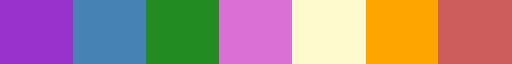

In [5]:
from matplotlib.colors import ListedColormap

# define custom colormap using color names (in order of corresponding networks: 1 visual, 2 sensorimotor, 3 dorsal attention, 4 ventral attention, 5 limbic, 6 fronto parietal, 7 DMN)
colors_yeo7 = ['darkorchid', 'steelblue', 'forestgreen', 'orchid', 'lemonchiffon', 'orange',  'indianred']

yeo7_colormap = ListedColormap(colors_yeo7, 'custom_colormap')

yeo7_colormap

In [6]:
# original Yeo network colors
palette_labeled_networks = {'DMN': 'indianred',  
                            'dorsal attention' : 'forestgreen',  
                            'fronto parietal' : 'orange',  
                            'limbic' : 'lemonchiffon',  
                            'sensory motor' : 'steelblue',
                            'ventral attention' : 'orchid', 
                            'visual' : 'darkorchid'} 

# making an array with yeo network labels (names instead of numbers)
yeo7_networks_array_labels = []

for i in yeo7_networks_array:
    if i == 1:
        yeo7_networks_array_labels.append('visual')
    elif i == 2:
        yeo7_networks_array_labels.append('sensory motor')
    elif i == 3:
        yeo7_networks_array_labels.append('dorsal attention')
    elif i == 4:
        yeo7_networks_array_labels.append('ventral attention')
    elif i == 5:
        yeo7_networks_array_labels.append('limbic')
    elif i == 6:
        yeo7_networks_array_labels.append('fronto parietal')
    elif i == 7:
        yeo7_networks_array_labels.append('DMN')

yeo7_networks_array_labels = np.asarray(yeo7_networks_array_labels)

network_names = ["visual", "sensory motor", "dorsal attention", "ventral attention", "limbic", "fronto parietal", "DMN"]

print("Number of parcels in each Yeo network:")
for i in range(len(network_names)):
    print(f"- {network_names[i]}: {yeo7_networks_array_labels.tolist().count(network_names[i])}")

Number of parcels in each Yeo network:
- visual: 61
- sensory motor: 77
- dorsal attention: 46
- ventral attention: 47
- limbic: 26
- fronto parietal: 53
- DMN: 90


## Fetch fsaverage parcellation (20484 vertices) coded for Schaefer 400 parcels 
**NOTE: schaefer_400_fs5 == 0 corresponds to midline (labels go from 0-400) -> disregard 0 in calculations and plotting**

In [7]:
# fetch the fsaverage parcellation labeling each of fsaverage5's 20484 vertices with its corresponding Schaefer parcel
schaefer_400_fs5 = fetch_parcellation("fsaverage5", "schaefer", 400)

In [8]:
schaefer_400_fs5.shape

(20484,)

## Fetch subject lists

## HCP adult gradients (G1 / S-A axis)

### Margulies gradient G1

In [122]:
Margulies_gradients_fsa5 = []
Margulies_gradients_schaefer400 = []

# Margulies published first 5 gradients
for i in range(1,6):

    # load left and right hemispheres (.agg_data() makes the Gifti format accessible) -> shape per hemi is 10242
    Margulies_fsa5_grad_L = nib.load('/data/p_02667/development/data/Gradients_Margulies2016/Gradients_Margulies2016/fsaverage/hcp.embed.grad_'+str(i)+'.L.fsa5.func.gii').agg_data()
    Margulies_fsa5_grad_R = nib.load('/data/p_02667/development/data/Gradients_Margulies2016/Gradients_Margulies2016/fsaverage/hcp.embed.grad_'+str(i)+'.R.fsa5.func.gii').agg_data()


    # concatenate left and right hemispheres - this data is shaped (20484), corresponding to vertices (including medial wall)
    Margulies_fsa5_grad_wholebrain = np.concatenate((Margulies_fsa5_grad_L, Margulies_fsa5_grad_R), axis=0)

    # append to list
    Margulies_gradients_fsa5.append(Margulies_fsa5_grad_wholebrain)

    # transform to Schaefer parcellation and append to list
    Margulies_gradients_schaefer400.append(fs5_to_schaefer400(Margulies_fsa5_grad_wholebrain, seven_networks=True))


Margulies_gradients_fsa5 = np.array(Margulies_gradients_fsa5)
Margulies_gradients_schaefer400 = np.array(Margulies_gradients_schaefer400)

In [123]:
Margulies_gradients_fsa5.shape

(5, 20484)

In [124]:
Margulies_gradients_schaefer400.T.shape

(400, 5)

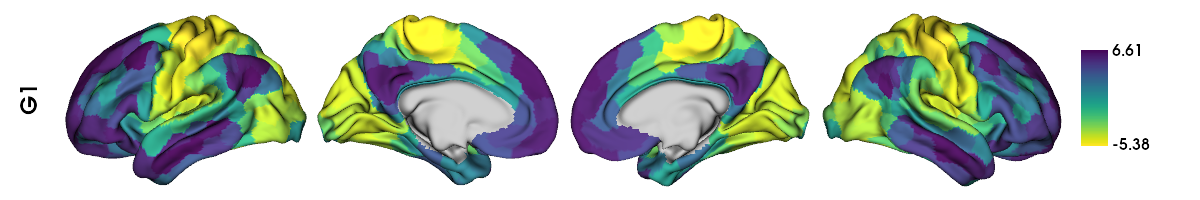

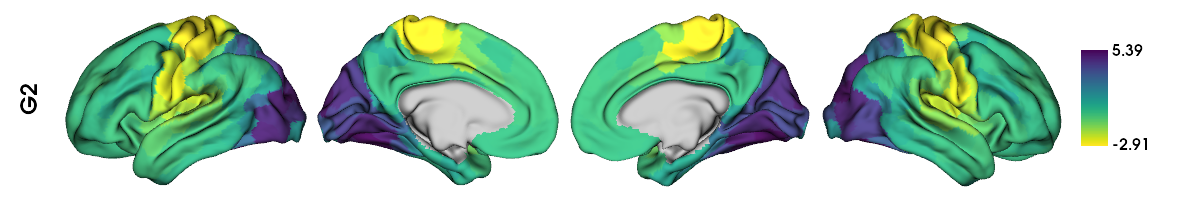

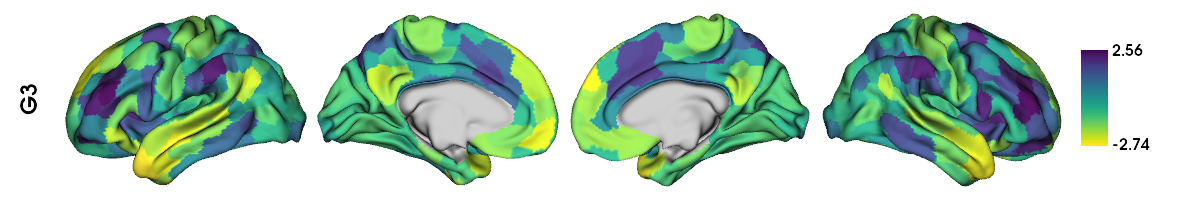

In [125]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

for i in range(3):
    # map the gradient to the parcels
    grad = map_to_labels(Margulies_gradients_schaefer400[i], labeling, mask=mask, fill=np.nan)

    plot = plot_hemispheres(surf_lh, 
                            surf_rh, 
                            array_name=grad, 
                            embed_nb = True, 
                            size=(1200, 200),
                            cmap='viridis_r', 
                            nan_color = (0.7, 0.7, 0.7, 1),
                            color_bar=True, 
                            label_text=[f'G{i+1}'], 
                            zoom=1.55,
                            screenshot = False,
                            filename = resdir_fig+'_plotted_hemispheres_TO_DEFINE.png')

    display(plot)

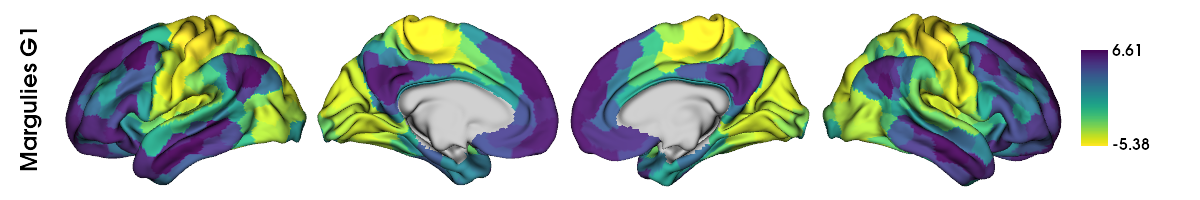

In [126]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(Margulies_gradients_schaefer400[0], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        #color_range = (min_loading_across_all_G1, max_loading_across_all_G1),
                        label_text=['Margulies G1'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_ref_Margulies_SAaxis.svg')

display(plot)

## Cleaned FC matrices

From p3_cleaning_final_sample.py

### Baseline

In [9]:
## This is current largest sample

# Loading HDF file (file was too large for matfile), with HDF reader e.g., hdf5storage
hdf_file_fc_matrices_baseline_clean = hdf5storage.read(filename=datadir_local+'abcd_fc_matrices_baseline_clean.h5')
hdf_file_fc_matrices_baseline_clean.keys()

dict_keys(['fc_matrices_baseline', 'fc_matrices_baseline_z', 'sub_ID_baseline'])

In [10]:
fc_matrices_baseline = hdf_file_fc_matrices_baseline_clean['fc_matrices_baseline_z']   # take r-to-z transformed matrices
sub_ID_baseline = hdf_file_fc_matrices_baseline_clean['sub_ID_baseline']

fc_matrices_baseline.shape

(4064, 400, 400)

### 2y follow-up

In [11]:
## This is current largest sample

# Loading HDF file (file was too large for matfile), with HDF reader e.g., hdf5storage
hdf_file_fc_matrices_fu2y_clean = hdf5storage.read(filename=datadir_local+'abcd_fc_matrices_fu2y_clean.h5')
hdf_file_fc_matrices_fu2y_clean.keys()

dict_keys(['fc_matrices_fu2y', 'fc_matrices_fu2y_z', 'sub_ID_fu2y'])

In [12]:
fc_matrices_fu2y = hdf_file_fc_matrices_fu2y_clean['fc_matrices_fu2y_z']  # take r-to-z transformed matrices
sub_ID_fu2y = hdf_file_fc_matrices_fu2y_clean['sub_ID_fu2y']

fc_matrices_fu2y.shape

(1296, 400, 400)

### 4y follow-up

In [13]:
## This is current largest sample

# Loading HDF file (file was too large for matfile), with HDF reader e.g., hdf5storage
hdf_file_fc_matrices_fu4y_clean = hdf5storage.read(filename=datadir_local+'abcd_fc_matrices_fu4y_clean.h5')
hdf_file_fc_matrices_fu4y_clean.keys()

dict_keys(['fc_matrices_fu4y', 'fc_matrices_fu4y_z', 'sub_ID_fu4y'])

In [14]:
fc_matrices_fu4y = hdf_file_fc_matrices_fu4y_clean['fc_matrices_fu4y_z']  # take r-to-z transformed matrices
sub_ID_fu4y = hdf_file_fc_matrices_fu4y_clean['sub_ID_fu4y']

fc_matrices_fu4y.shape

(963, 400, 400)

### all

In [15]:
fc_matrices_all = np.concatenate((fc_matrices_baseline, fc_matrices_fu2y, fc_matrices_fu4y), axis=0) 
fc_matrices_all.shape

(6323, 400, 400)

In [16]:
sub_ID_all = np.concatenate((sub_ID_baseline, sub_ID_fu2y, sub_ID_fu4y))
sub_ID_all.shape

(6323,)

## Sample

### Full sample

#### Load baseline

In [17]:
# Load puberty and demographics data
abcd_demo_baseline_clean = pd.read_csv(datadir_local+'abcd_demo_baseline_clean.csv')

In [18]:
# Safety check that sub ID list and demographics subjects are identical (order and elements) - this was done in the cleaning step normally
np.array_equal(np.array(sub_ID_baseline), np.array(abcd_demo_baseline_clean.src_subject_id_fmt))

True

#### Load 2y follow-up

In [19]:
# Load puberty and demographics data
abcd_demo_fu2y_clean = pd.read_csv(datadir_local+'abcd_demo_fu2y_clean.csv')

In [20]:
# Safety check that sub ID list and demographics subjects are identical (order and elements) - this was done in the cleaning step normally
np.array_equal(np.array(sub_ID_fu2y), np.array(abcd_demo_fu2y_clean.src_subject_id_fmt))

True

#### Load 4y follow-up

In [21]:
# Load puberty and demographics data
abcd_demo_fu4y_clean = pd.read_csv(datadir_local+'abcd_demo_fu4y_clean.csv')

In [22]:
# Safety check that sub ID list and demographics subjects are identical (order and elements) - this was done in the cleaning step normally
np.array_equal(np.array(sub_ID_fu4y), np.array(abcd_demo_fu4y_clean.src_subject_id_fmt))

True

#### Merge timepoints (same as "full sample" in main)

In [23]:
# Concatenate dataframes
abcd_demo_all_clean = pd.concat([abcd_demo_baseline_clean, abcd_demo_fu2y_clean, abcd_demo_fu4y_clean], axis=0)
abcd_demo_all_clean

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
0,sub-NDARINV003RTV85,10.0,F,13.0,baseline_year_1_arm_1,site06,8781.0,131.0,3.0,3.0,1.6,2.4,0.961662,188827.953554,4.0,1.0,1.0,3.0
1,sub-NDARINV007W6H7B,10.0,M,19.0,baseline_year_1_arm_1,site22,4722.0,126.0,2.0,1.0,1.5,1.0,0.550824,233329.288961,23.0,8.0,2.0,0.0
2,sub-NDARINV00J52GPG,9.0,M,21.0,baseline_year_1_arm_1,site17,4151.0,110.0,2.0,2.0,1.4,1.6,1.129072,201853.751338,11.0,0.0,1.0,0.0
3,sub-NDARINV00LH735Y,9.0,M,13.0,baseline_year_1_arm_1,site03,6069.0,109.0,1.0,1.0,1.0,1.4,1.570677,204865.644678,8.0,4.0,2.0,0.0
4,sub-NDARINV00NPMHND,9.0,F,18.0,baseline_year_1_arm_1,site17,4152.0,118.0,2.0,3.0,1.5,1.8,0.363954,212433.396427,42.0,23.0,3.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
958,sub-NDARINVZYC44GB8,10.0,M,21.0,4_year_follow_up_y_arm_1,site16,1840.0,179.0,4.0,4.0,3.0,3.0,-0.503814,206655.702684,0.0,0.0,0.0,0.0
959,sub-NDARINVZYRTFYRP,9.0,M,13.0,4_year_follow_up_y_arm_1,site10,10925.0,164.0,1.0,3.0,1.6,2.6,-0.428811,173346.170313,20.0,4.0,5.0,1.0
960,sub-NDARINVZZ1MNPK5,10.0,F,20.0,4_year_follow_up_y_arm_1,site08,7031.0,175.0,5.0,4.0,3.6,3.6,-0.500384,171459.001848,20.0,13.0,2.0,0.0
961,sub-NDARINVZZ81LEEV,9.0,M,15.0,4_year_follow_up_y_arm_1,site11,8433.0,157.0,2.0,2.0,1.2,1.8,-1.408592,202083.016847,6.0,3.0,0.0,0.0


In [24]:
print(f"{np.sum(abcd_demo_all_clean.sex == 'F')} females, {np.sum(abcd_demo_all_clean.sex == 'M')} males")

3220 females, 3103 males


In [25]:
len(pd.unique(abcd_demo_all_clean['src_subject_id_fmt']))

4919

In [26]:
len(pd.unique(abcd_demo_all_clean['family_id']))

4409

### Longitudinal sample

In [27]:
# True for rows whose subject appears more than once
counts = abcd_demo_all_clean.groupby('src_subject_id_fmt')['src_subject_id_fmt'].transform('size')
keep_mask = (counts > 1).to_numpy()

# Subset dataframe (original order preserved)
abcd_demo_all_clean = abcd_demo_all_clean[keep_mask].reset_index(drop=True)

# Subset the brain data with the same mask
fc_matrices_all = fc_matrices_all[keep_mask]
sub_ID_all = sub_ID_all[keep_mask]

In [28]:
abcd_demo_all_clean

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
0,sub-NDARINV01NAYMZH,10.0,M,18.0,baseline_year_1_arm_1,site16,862.0,129.0,3.0,1.0,2.200000,1.2,0.189603,206515.952068,12.0,1.0,5.0,2.0
1,sub-NDARINV01RGTWD2,9.0,F,19.0,baseline_year_1_arm_1,site02,11327.0,111.0,NaN,2.0,1.333333,1.2,-0.921614,181682.501796,32.0,8.0,13.0,2.0
2,sub-NDARINV021403LF,9.0,M,19.0,baseline_year_1_arm_1,site05,470.0,109.0,2.0,1.0,2.200000,1.4,0.737398,199946.560800,16.0,3.0,3.0,1.0
3,sub-NDARINV03CV8RDT,10.0,M,18.0,baseline_year_1_arm_1,site09,9763.0,128.0,2.0,1.0,1.500000,1.4,-2.215569,198539.198315,10.0,6.0,1.0,1.0
4,sub-NDARINV03XVEBPM,10.0,F,21.0,baseline_year_1_arm_1,site08,6689.0,120.0,NaN,1.0,1.000000,1.0,-0.840777,196323.223149,8.0,4.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2493,sub-NDARINVZPR155DG,9.0,F,18.0,4_year_follow_up_y_arm_1,site03,6670.0,153.0,5.0,4.0,3.800000,3.6,1.165853,176412.730306,8.0,2.0,4.0,1.0
2494,sub-NDARINVZT1J0KUC,10.0,F,18.0,4_year_follow_up_y_arm_1,site03,6672.0,168.0,5.0,5.0,3.600000,3.6,0.895561,189854.640610,10.0,5.0,2.0,6.0
2495,sub-NDARINVZXF5C635,10.0,F,19.0,4_year_follow_up_y_arm_1,site06,9344.0,172.0,4.0,4.0,3.400000,3.4,0.505156,192376.290883,27.0,7.0,9.0,2.0
2496,sub-NDARINVZYC44GB8,10.0,M,21.0,4_year_follow_up_y_arm_1,site16,1840.0,179.0,4.0,4.0,3.000000,3.0,-0.503814,206655.702684,0.0,0.0,0.0,0.0


In [29]:
len(sub_ID_all)

2498

In [30]:
fc_matrices_all.shape

(2498, 400, 400)

#### Identifying subjects with impossible PDS (decreasing with age)

In [31]:
def pds_direction_check(g):
    #g = g.dropna()
    age = g['age_months'].to_numpy()
    pds = g['pds_p_score'].to_numpy()
    
    # Sign of change for every pair of visits (+1 up, -1 down, 0 no change)
    d_age = np.sign(age[:, None] - age[None, :])
    d_pds = np.sign(pds[:, None] - pds[None, :])
    agree = d_age * d_pds        # +1 same direction, -1 opposite, 0 one didn't change
    
    return pd.Series({
        'non_decreasing': (agree >= 0).all(),                   # PDS never goes down as age goes up
        'strictly_increasing': (agree[d_age != 0] > 0).all(),   # PDS always goes up as age goes up
    })

check = (abcd_demo_all_clean
         .groupby('src_subject_id_fmt', sort=False)[['age_months', 'pds_p_score']]
         .apply(pds_direction_check))


impossible_pds_subjects = check.index[~check['non_decreasing']]
print(f"Number of subjects with PDS going the opposite way to age: {len(impossible_pds_subjects)}")
print(f"Number of rows/datapoints to exclude (all belonging to subjects with impossible PDS): {len(abcd_demo_all_clean[abcd_demo_all_clean['src_subject_id_fmt'].isin(impossible_pds_subjects)])}")


Number of subjects with PDS going the opposite way to age: 63
Number of rows/datapoints to exclude (all belonging to subjects with impossible PDS): 152


In [32]:
impossible_pds_subjects

Index(['sub-NDARINV0P3ERKVG', 'sub-NDARINV1CGKKTM5', 'sub-NDARINV1CYTVBWT',
       'sub-NDARINV2BPVXTH3', 'sub-NDARINV2J8WHJ3R', 'sub-NDARINV2V8997BF',
       'sub-NDARINV3UNMBY32', 'sub-NDARINV4C8YJ9BG', 'sub-NDARINV4FBVLRNU',
       'sub-NDARINV4LPXB23R', 'sub-NDARINV52K3HFFN', 'sub-NDARINV61RKCL4Y',
       'sub-NDARINV6JF8WUYT', 'sub-NDARINV7JUL4TDF', 'sub-NDARINV7W4K75L0',
       'sub-NDARINV7YZP2ZNL', 'sub-NDARINV8E3TY3RU', 'sub-NDARINV8Y8A8NU0',
       'sub-NDARINV9Z6E4FXG', 'sub-NDARINV9ZFFC49P', 'sub-NDARINVB5VK9XEN',
       'sub-NDARINVB7CUAZH9', 'sub-NDARINVBR0R4R8M', 'sub-NDARINVBWFE6KU6',
       'sub-NDARINVCKTT8HAT', 'sub-NDARINVCX7YWXVP', 'sub-NDARINVE1MRKJ3N',
       'sub-NDARINVEBFULY5Y', 'sub-NDARINVGALZWY31', 'sub-NDARINVGF5M5HN2',
       'sub-NDARINVH3WNU4JB', 'sub-NDARINVH9ERT7NK', 'sub-NDARINVHXY3TJAT',
       'sub-NDARINVJNDY0DWK', 'sub-NDARINVKJDAZKWA', 'sub-NDARINVL5EAF5N9',
       'sub-NDARINVLBJ8E0XH', 'sub-NDARINVLRNZXLDX', 'sub-NDARINVM5F9LGBU',
       'sub-

In [33]:
# VISUALLY CHECKING TO MAKE SURE THE pds_direction_check() worked properly -> confirmed
for i in range(len(impossible_pds_subjects)):
    bad_rows = abcd_demo_all_clean[
        abcd_demo_all_clean['src_subject_id_fmt']==(impossible_pds_subjects[i])]
    
    print(bad_rows[['src_subject_id_fmt', 'age_months', 'pds_p_score']])
    print('')

       src_subject_id_fmt  age_months  pds_p_score
25    sub-NDARINV0P3ERKVG       108.0          1.4
1827  sub-NDARINV0P3ERKVG       154.0          1.0

       src_subject_id_fmt  age_months  pds_p_score
50    sub-NDARINV1CGKKTM5       112.0          1.4
924   sub-NDARINV1CGKKTM5       138.0          1.0
1842  sub-NDARINV1CGKKTM5       159.0          2.8

      src_subject_id_fmt  age_months  pds_p_score
51   sub-NDARINV1CYTVBWT       124.0          3.4
925  sub-NDARINV1CYTVBWT       165.0          2.5

       src_subject_id_fmt  age_months  pds_p_score
82    sub-NDARINV2BPVXTH3       124.0          1.4
959   sub-NDARINV2BPVXTH3       148.0          1.2
1865  sub-NDARINV2BPVXTH3       170.0          2.6

      src_subject_id_fmt  age_months  pds_p_score
88   sub-NDARINV2J8WHJ3R       108.0          1.4
963  sub-NDARINV2J8WHJ3R       130.0          1.0

      src_subject_id_fmt  age_months  pds_p_score
96   sub-NDARINV2V8997BF       116.0          1.2
975  sub-NDARINV2V8997BF       140

#### Removing subjects with impossible PDS (decreasing with age) from full (LONGITUDINAL) sample

In [35]:
# Mask for the dataframe
keep_df = ~abcd_demo_all_clean['src_subject_id_fmt'].isin(impossible_pds_subjects).to_numpy()

# Mask for the ID array (which defines the order of fc_matrices_all)
keep_fc = ~np.isin(sub_ID_all, impossible_pds_subjects)

print(f"Number of subjects before removal: {len(sub_ID_all)}")

# Apply
abcd_demo_all_clean = abcd_demo_all_clean[keep_df].reset_index(drop=True)
sub_ID_all = sub_ID_all[keep_fc]
fc_matrices_all = fc_matrices_all[keep_fc]

# Sanity checks
print(f"Number of subjects after removal: {len(sub_ID_all)}")
print(f"Rows removed from df: {(~keep_df).sum()}, from FC array: {(~keep_fc).sum()}")
print(f"Lengths of demographics df and FC matrices array and subjects array match: {len(abcd_demo_all_clean) == fc_matrices_all.shape[0] == len(sub_ID_all)}")
print(f"Demographics df subjects and FC subjects match: {(abcd_demo_all_clean['src_subject_id_fmt'].to_numpy() == sub_ID_all).all()}")

Number of subjects before removal: 2498
Number of subjects after removal: 2346
Rows removed from df: 152, from FC array: 152
Lengths of demographics df and FC matrices array and subjects array match: True
Demographics df subjects and FC subjects match: True


In [41]:
abcd_demo_all_clean

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
0,sub-NDARINV01NAYMZH,10.0,M,18.0,baseline_year_1_arm_1,site16,862.0,129.0,3.0,1.0,2.200000,1.2,0.189603,206515.952068,12.0,1.0,5.0,2.0
1,sub-NDARINV01RGTWD2,9.0,F,19.0,baseline_year_1_arm_1,site02,11327.0,111.0,NaN,2.0,1.333333,1.2,-0.921614,181682.501796,32.0,8.0,13.0,2.0
2,sub-NDARINV021403LF,9.0,M,19.0,baseline_year_1_arm_1,site05,470.0,109.0,2.0,1.0,2.200000,1.4,0.737398,199946.560800,16.0,3.0,3.0,1.0
3,sub-NDARINV03CV8RDT,10.0,M,18.0,baseline_year_1_arm_1,site09,9763.0,128.0,2.0,1.0,1.500000,1.4,-2.215569,198539.198315,10.0,6.0,1.0,1.0
4,sub-NDARINV03XVEBPM,10.0,F,21.0,baseline_year_1_arm_1,site08,6689.0,120.0,NaN,1.0,1.000000,1.0,-0.840777,196323.223149,8.0,4.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2341,sub-NDARINVZPR155DG,9.0,F,18.0,4_year_follow_up_y_arm_1,site03,6670.0,153.0,5.0,4.0,3.800000,3.6,1.165853,176412.730306,8.0,2.0,4.0,1.0
2342,sub-NDARINVZT1J0KUC,10.0,F,18.0,4_year_follow_up_y_arm_1,site03,6672.0,168.0,5.0,5.0,3.600000,3.6,0.895561,189854.640610,10.0,5.0,2.0,6.0
2343,sub-NDARINVZXF5C635,10.0,F,19.0,4_year_follow_up_y_arm_1,site06,9344.0,172.0,4.0,4.0,3.400000,3.4,0.505156,192376.290883,27.0,7.0,9.0,2.0
2344,sub-NDARINVZYC44GB8,10.0,M,21.0,4_year_follow_up_y_arm_1,site16,1840.0,179.0,4.0,4.0,3.000000,3.0,-0.503814,206655.702684,0.0,0.0,0.0,0.0


#### Create three demographics dataframes, FC matrices arrays, subject ID arrays from full/cleaned longitudinal sample

In [45]:
# Confirm row-by-row alignment before splitting
print(f"Lengths of demographics df and FC matrices array and subjects array match: {len(abcd_demo_all_clean) == fc_matrices_all.shape[0] == len(sub_ID_all)}")
print(f"Demographics df subjects and FC subjects match: {(abcd_demo_all_clean['src_subject_id_fmt'].to_numpy() == sub_ID_all).all()}")

Lengths of demographics df and FC matrices array and subjects array match: True
Demographics df subjects and FC subjects match: True


In [50]:
events = abcd_demo_all_clean['eventname'].to_numpy()

def split_by_event(event):
    mask = events == event
    return (abcd_demo_all_clean[mask].reset_index(drop=True),
            fc_matrices_all[mask],
            sub_ID_all[mask])

abcd_demo_baseline_clean, fc_matrices_baseline, sub_ID_baseline = split_by_event('baseline_year_1_arm_1')
abcd_demo_fu2y_clean,     fc_matrices_fu2y,     sub_ID_fu2y     = split_by_event('2_year_follow_up_y_arm_1')
abcd_demo_fu4y_clean,     fc_matrices_fu4y,     sub_ID_fu4y     = split_by_event('4_year_follow_up_y_arm_1')

# Sanity checks
for name, df, fc, ids in [('baseline', abcd_demo_baseline_clean, fc_matrices_baseline, sub_ID_baseline),
                          ('fu2y',     abcd_demo_fu2y_clean,     fc_matrices_fu2y,     sub_ID_fu2y),
                          ('fu4y',     abcd_demo_fu4y_clean,     fc_matrices_fu4y,     sub_ID_fu4y)]:
    print(f"Lengths of demographics df and FC matrices array and subjects array match: {len(df) == fc.shape[0] == len(ids)}")
    print(f"Demographics df subjects and FC subjects match: {(df['src_subject_id_fmt'].to_numpy() == ids).all()}")

    print(f"{name}: {len(df)} rows, {df['src_subject_id_fmt'].nunique()} unique subjects\n")

n_assigned = len(abcd_demo_baseline_clean) + len(abcd_demo_fu2y_clean) + len(abcd_demo_fu4y_clean)
print(f"Rows not assigned to any timepoint: {len(abcd_demo_all_clean) - n_assigned}")

Lengths of demographics df and FC matrices array and subjects array match: True
Demographics df subjects and FC subjects match: True
baseline: 819 rows, 819 unique subjects

Lengths of demographics df and FC matrices array and subjects array match: True
Demographics df subjects and FC subjects match: True
fu2y: 879 rows, 879 unique subjects

Lengths of demographics df and FC matrices array and subjects array match: True
Demographics df subjects and FC subjects match: True
fu4y: 648 rows, 648 unique subjects

Rows not assigned to any timepoint: 0


### Exporting new cleaned demographics dataframes (excluding impossible PDS decreases)

In [ ]:
abcd_demo_baseline_clean.to_csv(datadir_local_longitudinal_sample+'abcd_demo_baseline_clean.csv', header = True, index = False)
abcd_demo_fu2y_clean.to_csv(datadir_local_longitudinal_sample+'abcd_demo_fu2y_clean.csv', header = True, index = False)
abcd_demo_fu4y_clean.to_csv(datadir_local_longitudinal_sample+'abcd_demo_fu4y_clean.csv', header = True, index = False)
abcd_demo_full_clean.to_csv(datadir_local_longitudinal_sample+'abcd_demo_full_clean.csv', header = True, index = False)

### Exporting new corresponding FC matrices (excluding impossible PDS decreases)
This is needed for GD computation

**Note: I am saving as "_pds" to flag that these have been pds screened**

**Note: I am calling FC matrices as "_z" because the data I loaded in here was _z (even if variable names in the current notebook are not named as _z)**

**!! IMPORTANT NOTE !! I am commenting out the code to export FC matrices below given that overwriting throws errors (as mentioned in code comments) - so make sure to uncomment and rerun IF any changes are made to the filtering/cleaning of the data above**

In [ ]:
# baseline

mdict = {
    'fc_matrices_baseline_z': fc_matrices_baseline,
    'sub_ID_baseline': sub_ID_baseline
}

# !!! will probably throw error to overwrite - should be able to bypass this by adding the parameter: truncate_existing=True   # <-- ensures existing file is overwritten
# otherwise delete existing file and save as follows (as "first time save" - not overwriting)
hdf5storage.write(mdict, filename=datadir_local_longitudinal_sample+'abcd_fc_matrices_baseline_clean.h5', format='7.3')



# fu2y

mdict = {
    'fc_matrices_fu2y_z': fc_matrices_fu2y,
    'sub_ID_fu2y': sub_ID_fu2y
}

hdf5storage.write(mdict, filename=datadir_local_longitudinal_sample+'abcd_fc_matrices_fu2y_clean.h5', format='7.3')



# fu4y

mdict = {
    'fc_matrices_fu4y_z': fc_matrices_fu4y,
    'sub_ID_fu4y': sub_ID_fu4y
}


hdf5storage.write(mdict, filename=datadir_local_longitudinal_sample+'abcd_fc_matrices_fu4y_clean.h5', format='7.3')


#
#
# Demographics & Puberty

### Baseline

In [53]:
print(f"{np.sum(abcd_demo_baseline_clean.sex == 'F')} females, {np.sum(abcd_demo_baseline_clean.sex == 'M')} males")

2088 females, 1919 males


In [22]:
abcd_demo_baseline_clean["edu_parent"].isna().sum()

2

#### Age

In [23]:
# 1. Setup shorthand variables
df = abcd_demo_baseline_clean
m_data = df[df['sex'] == 'M']['age_months']
f_data = df[df['sex'] == 'F']['age_months']
all_data = df['age_months']

def print_stats(label, data):
    med, mean, sd = np.median(data), np.mean(data), np.std(data)
    print(f"{label:12} | Median: {med:.2f}m ({med/12:.2f}y) | Mean: {mean:.2f}m ({mean/12:.2f}y) | SD: {sd:.2f}")

# 2. Descriptive Statistics
print("--- Descriptive Statistics ---")
print_stats("Full Sample", all_data)
print_stats("Males", m_data)
print_stats("Females", f_data)

print(f"\nRange (All): {all_data.min():.2f} - {all_data.max():.2f} months "
      f"({all_data.min()/12:.2f} - {all_data.max()/12:.2f} years)")

# 3. Normality & Significance Tests
print("\n--- Statistical Tests ---")

# Shapiro-Wilk for normality
# (If p < 0.05, data is significantly different from normal)
shapiro_m = stats.shapiro(m_data)
shapiro_f = stats.shapiro(f_data)
print(f"Shapiro Normality (M): W={shapiro_m.statistic:.4f}, p={shapiro_m.pvalue:.4f}")
print(f"Shapiro Normality (F): W={shapiro_f.statistic:.4f}, p={shapiro_f.pvalue:.4f}")

# Mann-Whitney U (Non-parametric comparison)

u_stat, p_val = stats.mannwhitneyu(m_data, f_data)
print(f"\nMann-Whitney U Test: U={u_stat}, p={p_val:.4f}")

--- Descriptive Statistics ---
Full Sample  | Median: 120.00m (10.00y) | Mean: 119.70m (9.97y) | SD: 7.54
Males        | Median: 121.00m (10.08y) | Mean: 119.95m (10.00y) | SD: 7.60
Females      | Median: 119.00m (9.92y) | Mean: 119.46m (9.96y) | SD: 7.47

Range (All): 107.00 - 132.00 months (8.92 - 11.00 years)

--- Statistical Tests ---
Shapiro Normality (M): W=0.9363, p=0.0000
Shapiro Normality (F): W=0.9429, p=0.0000

Mann-Whitney U Test: U=2139352.5, p=0.0379


#### Total SA

In [24]:
print("mm2")
print(f"Total SA in Females: Mean: {np.mean(abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'F']):.2f}") 
print(f"Total SA in Males: Mean: {np.mean(abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'M']):.2f}")

print("\ncm2")
print(f"Total SA in Females: Mean: {np.mean(abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'F']/100):.2f}, SD: {np.std(abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'F']/100):.2f}") 
print(f"Total SA in Males: Mean: {np.mean(abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'M']/100):.2f}, SD: {np.std(abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'M']/100):.2f}")


mm2
Total SA in Females: Mean: 191913.51, SD: 15355.93
Total SA in Males: Mean: 210064.84, SD: 16835.51

cm2
Total SA in Females: Mean: 1919.14, SD: 153.56
Total SA in Males: Mean: 2100.65, SD: 168.36


In [25]:
stats.ttest_ind(abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'F'], abcd_demo_baseline_clean.tot_SA[abcd_demo_baseline_clean.sex == 'M'])

TtestResult(statistic=-35.93486859176223, pvalue=8.392867551212317e-246, df=4062.0)

#### Puberty

In [26]:
# 1. Setup shorthand variables
df = abcd_demo_baseline_clean
m_data = df[df['sex'] == 'M']['pds_p_score']
f_data = df[df['sex'] == 'F']['pds_p_score']
all_data = df['pds_p_score']

def print_stats(label, data):
    med, mean, sd = np.median(data), np.mean(data), np.std(data)
    print(f"{label:12} | Median: {med:.2f} | Mean: {mean:.2f} | SD: {sd:.2f}")

# 2. Descriptive Statistics
print("--- Descriptive Statistics ---")
print_stats("Full Sample", all_data)
print_stats("Males", m_data)
print_stats("Females", f_data)

print(f"\nRange (All): {all_data.min():.2f} - {all_data.max():.2f}")

# 3. Normality & Significance Tests
print("\n--- Statistical Tests ---")

# Shapiro-Wilk for normality
# (If p < 0.05, data is significantly different from normal)
shapiro_m = stats.shapiro(m_data)
shapiro_f = stats.shapiro(f_data)
print(f"Shapiro Normality (M): W={shapiro_m.statistic:.4f}, p={shapiro_m.pvalue:.4f}")
print(f"Shapiro Normality (F): W={shapiro_f.statistic:.4f}, p={shapiro_f.pvalue:.4f}")

# Mann-Whitney U (Non-parametric comparison)

u_stat, p_val = stats.mannwhitneyu(m_data, f_data)
print(f"\nMann-Whitney U Test: U={u_stat}, p={p_val:.4f}")

--- Descriptive Statistics ---
Full Sample  | Median: 1.40 | Mean: 1.57 | SD: 0.46
Males        | Median: 1.40 | Mean: 1.40 | SD: 0.35
Females      | Median: 1.60 | Mean: 1.72 | SD: 0.50

Range (All): 1.00 - 3.60

--- Statistical Tests ---
Shapiro Normality (M): W=0.8780, p=0.0000
Shapiro Normality (F): W=0.9417, p=0.0000

Mann-Whitney U Test: U=1271797.0, p=0.0000


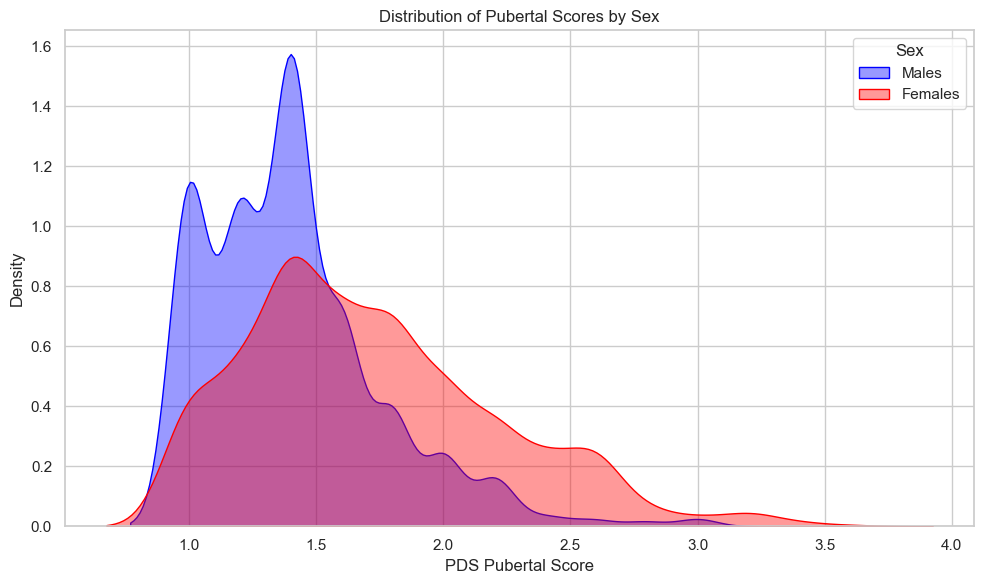

In [27]:
### Density plots
# This uses kernel density estimation (kdeplot) to visualize distributions smoothly.
# You can also adjust alpha to change transparency and fill=False if you'd prefer just the outline.

# Set style
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(10, 6))

# Plot male distribution
sns.kdeplot(
    data=abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'],
    x='pds_p_score',
    label='Males',
    color='blue',
    fill=True,
    alpha=0.4
)

# Plot female distribution
sns.kdeplot(
    data=abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'],
    x='pds_p_score',
    label='Females',
    color='red',
    fill=True,
    alpha=0.4
)

# Add labels and title
plt.xlabel("PDS Pubertal Score")
plt.ylabel("Density")
plt.title("Distribution of Pubertal Scores by Sex")
plt.legend(title="Sex")
plt.tight_layout()
plt.show()


#### CBCL

Describe total symptoms and symptom dimensions

In [29]:
print("CBCL Total Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_baseline_clean.cbcl_tot[abcd_demo_baseline_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_baseline_clean.cbcl_tot[abcd_demo_baseline_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_baseline_clean.cbcl_tot[abcd_demo_baseline_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_baseline_clean.cbcl_tot[abcd_demo_baseline_clean.sex == 'M']):.2f}")

print("\nCBCL Internalizing Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_baseline_clean.cbcl_int[abcd_demo_baseline_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_baseline_clean.cbcl_int[abcd_demo_baseline_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_baseline_clean.cbcl_int[abcd_demo_baseline_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_baseline_clean.cbcl_int[abcd_demo_baseline_clean.sex == 'M']):.2f}")

print("\nCBCL Externalizing Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_baseline_clean.cbcl_ext[abcd_demo_baseline_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_baseline_clean.cbcl_ext[abcd_demo_baseline_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_baseline_clean.cbcl_ext[abcd_demo_baseline_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_baseline_clean.cbcl_ext[abcd_demo_baseline_clean.sex == 'M']):.2f}")

CBCL Total Symptoms
Females: Mean: 15.22, SD: 15.32
Males: Mean: 18.30, SD: 18.18

CBCL Internalizing Symptoms
Females: Mean: 4.98, SD: 5.38
Males: Mean: 4.90, SD: 5.32

CBCL Externalizing Symptoms
Females: Mean: 3.46, SD: 4.82
Males: Mean: 4.66, SD: 6.19


In [30]:
print("CBCL Total Symptoms")
print(stats.levene(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].cbcl_tot, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].cbcl_tot, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].cbcl_tot, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].cbcl_tot, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

print("\nCBCL Internalizing Symptoms")
print(stats.levene(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].cbcl_int, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].cbcl_int, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].cbcl_int, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].cbcl_int, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

print("\nCBCL Externalizing Symptoms")
print(stats.levene(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].cbcl_ext, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].cbcl_ext, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].cbcl_ext, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].cbcl_ext, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

CBCL Total Symptoms
LeveneResult(statistic=18.02111474569197, pvalue=2.2335020396130293e-05)
FlignerResult(statistic=29.121328443498797, pvalue=6.798441782927633e-08)

CBCL Internalizing Symptoms
LeveneResult(statistic=0.08753290712631043, pvalue=0.7673524229100321)
FlignerResult(statistic=0.0914439118446017, pvalue=0.7623494839721723)

CBCL Externalizing Symptoms
LeveneResult(statistic=37.32252526596314, pvalue=1.0952108512268954e-09)
FlignerResult(statistic=32.94831108496465, pvalue=9.464192847618164e-09)


In [31]:
print("CBCL Total Symptoms")
print(f"{stats.ttest_ind(abcd_demo_baseline_clean.cbcl_tot[abcd_demo_baseline_clean.sex == 'F'], abcd_demo_baseline_clean.cbcl_tot[abcd_demo_baseline_clean.sex == 'M'], nan_policy='omit')}")

print("\nCBCL Internalizing Symptoms")
print(f"{stats.ttest_ind(abcd_demo_baseline_clean.cbcl_int[abcd_demo_baseline_clean.sex == 'F'], abcd_demo_baseline_clean.cbcl_int[abcd_demo_baseline_clean.sex == 'M'], nan_policy='omit')}")

print("\nCBCL Externalizing Symptoms")
print(f"{stats.ttest_ind(abcd_demo_baseline_clean.cbcl_ext[abcd_demo_baseline_clean.sex == 'F'], abcd_demo_baseline_clean.cbcl_ext[abcd_demo_baseline_clean.sex == 'M'], nan_policy='omit')}")

CBCL Total Symptoms
TtestResult(statistic=-5.851691273025186, pvalue=5.249747669949404e-09, df=4062.0)

CBCL Internalizing Symptoms
TtestResult(statistic=0.4724574488403506, pvalue=0.6366256885583996, df=4062.0)

CBCL Externalizing Symptoms
TtestResult(statistic=-6.894110030643044, pvalue=6.2580734861172596e-12, df=4062.0)


In [32]:
print("CBCL Total Symptoms")
print(stats.mannwhitneyu(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].cbcl_tot, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].cbcl_tot, nan_policy='omit'))

print("\nCBCL Internalizing Symptoms")
print(stats.mannwhitneyu(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].cbcl_int, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].cbcl_int, nan_policy='omit'))

print("\nCBCL Externalizing Symptoms")
print(stats.mannwhitneyu(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].cbcl_ext, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].cbcl_ext, nan_policy='omit'))

CBCL Total Symptoms
MannwhitneyuResult(statistic=2273759.0, pvalue=1.4041925146128505e-08)

CBCL Internalizing Symptoms
MannwhitneyuResult(statistic=2039407.0, pvalue=0.5459826719771018)

CBCL Externalizing Symptoms
MannwhitneyuResult(statistic=2305999.0, pvalue=3.310282857453481e-11)


Checking NaNs

In [33]:
abcd_demo_baseline_clean["cbcl_tot"].isna().sum()

0

In [34]:
abcd_demo_baseline_clean["cbcl_int"].isna().sum()

0

In [35]:
abcd_demo_baseline_clean["cbcl_ext"].isna().sum()

0

In [36]:
abcd_demo_baseline_clean[abcd_demo_baseline_clean["cbcl_tot"].isna()]

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y


#### Family Conflict (FES)

In [37]:
abcd_demo_baseline_clean.fam_conflict_y.value_counts()

fam_conflict_y
0.0    1193
1.0     931
2.0     678
3.0     467
4.0     345
5.0     203
6.0     122
7.0      88
8.0      25
9.0       7
Name: count, dtype: int64

In [38]:
print(f"Females: Mean: {np.mean(abcd_demo_baseline_clean.fam_conflict_y[abcd_demo_baseline_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_baseline_clean.fam_conflict_y[abcd_demo_baseline_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_baseline_clean.fam_conflict_y[abcd_demo_baseline_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_baseline_clean.fam_conflict_y[abcd_demo_baseline_clean.sex == 'M']):.2f}")

Females: Mean: 1.76, SD: 1.87
Males: Mean: 2.04, SD: 1.93


In [39]:
print(stats.levene(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].fam_conflict_y, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].fam_conflict_y, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

LeveneResult(statistic=4.811744782398687, pvalue=0.028322956010618405)
FlignerResult(statistic=15.135665997718688, pvalue=0.00010005505948214214)


In [40]:
print(f"{stats.ttest_ind(abcd_demo_baseline_clean.fam_conflict_y[abcd_demo_baseline_clean.sex == 'F'], abcd_demo_baseline_clean.fam_conflict_y[abcd_demo_baseline_clean.sex == 'M'], nan_policy='omit')}")

TtestResult(statistic=-4.6006397565325114, pvalue=4.340521215758746e-06, df=4057.0)


In [41]:
print(stats.mannwhitneyu(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].fam_conflict_y, nan_policy='omit'))

MannwhitneyuResult(statistic=2247906.0, pvalue=1.5868464623498794e-07)


Checking NaNs

In [42]:
abcd_demo_baseline_clean["fam_conflict_y"].isna().sum()

5

#### BMI z-score (relative to age and sex - with reference to the CDC 2000 Growth Charts)

In [43]:
print(f"Females: Mean: {np.mean(abcd_demo_baseline_clean.BMIz[abcd_demo_baseline_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_baseline_clean.BMIz[abcd_demo_baseline_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_baseline_clean.BMIz[abcd_demo_baseline_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_baseline_clean.BMIz[abcd_demo_baseline_clean.sex == 'M']):.2f}")

Females: Mean: 0.14, SD: 1.13
Males: Mean: 0.18, SD: 1.11


In [44]:
print(stats.levene(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].BMIz, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].BMIz, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].BMIz, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].BMIz, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

LeveneResult(statistic=0.3282139205914827, pvalue=0.5667444743710744)
FlignerResult(statistic=0.4183070684211469, pvalue=0.517782995187239)


In [45]:
print(f"{stats.ttest_ind(abcd_demo_baseline_clean.BMIz[abcd_demo_baseline_clean.sex == 'F'], abcd_demo_baseline_clean.BMIz[abcd_demo_baseline_clean.sex == 'M'], nan_policy='omit')}")

TtestResult(statistic=-1.0661487778908472, pvalue=0.2864198973888822, df=4053.0)


In [46]:
print(stats.mannwhitneyu(abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'M'].BMIz, abcd_demo_baseline_clean[abcd_demo_baseline_clean['sex'] == 'F'].BMIz, nan_policy='omit'))

MannwhitneyuResult(statistic=2092530.0, pvalue=0.28557964831285443)


Checking NaNs

In [47]:
abcd_demo_baseline_clean["BMIz"].isna().sum()

9

### fu2y

In [54]:
print(f"{np.sum(abcd_demo_fu2y_clean.sex == 'F')} females, {np.sum(abcd_demo_fu2y_clean.sex == 'M')} males")

633 females, 602 males


In [38]:
abcd_demo_fu2y_clean["edu_parent"].isna().sum()

2

#### Age

In [39]:
# 1. Setup shorthand variables
df = abcd_demo_fu2y_clean
m_data = df[df['sex'] == 'M']['age_months']
f_data = df[df['sex'] == 'F']['age_months']
all_data = df['age_months']

def print_stats(label, data):
    med, mean, sd = np.median(data), np.mean(data), np.std(data)
    print(f"{label:12} | Median: {med:.2f}m ({med/12:.2f}y) | Mean: {mean:.2f}m ({mean/12:.2f}y) | SD: {sd:.2f}")

# 2. Descriptive Statistics
print("--- Descriptive Statistics ---")
print_stats("Full Sample", all_data)
print_stats("Males", m_data)
print_stats("Females", f_data)

print(f"\nRange (All): {all_data.min():.2f} - {all_data.max():.2f} months "
      f"({all_data.min()/12:.2f} - {all_data.max()/12:.2f} years)")

# 3. Normality & Significance Tests
print("\n--- Statistical Tests ---")

# Shapiro-Wilk for normality
# (If p < 0.05, data is significantly different from normal)
shapiro_m = stats.shapiro(m_data)
shapiro_f = stats.shapiro(f_data)
print(f"Shapiro Normality (M): W={shapiro_m.statistic:.4f}, p={shapiro_m.pvalue:.4f}")
print(f"Shapiro Normality (F): W={shapiro_f.statistic:.4f}, p={shapiro_f.pvalue:.4f}")

# Mann-Whitney U (Non-parametric comparison)

u_stat, p_val = stats.mannwhitneyu(m_data, f_data)
print(f"\nMann-Whitney U Test: U={u_stat}, p={p_val:.4f}")

--- Descriptive Statistics ---
Full Sample  | Median: 144.00m (12.00y) | Mean: 143.54m (11.96y) | SD: 7.98
Males        | Median: 145.00m (12.08y) | Mean: 144.08m (12.01y) | SD: 8.02
Females      | Median: 143.00m (11.92y) | Mean: 143.00m (11.92y) | SD: 7.90

Range (All): 129.00 - 165.00 months (10.75 - 13.75 years)

--- Statistical Tests ---
Shapiro Normality (M): W=0.9508, p=0.0000
Shapiro Normality (F): W=0.9610, p=0.0000

Mann-Whitney U Test: U=226470.0, p=0.0140


#### Total SA

In [40]:
print("mm2")
print(f"Total SA in Females: Mean: {np.mean(abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'F']):.2f}") 
print(f"Total SA in Males: Mean: {np.mean(abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'M']):.2f}")

print("\ncm2")
print(f"Total SA in Females: Mean: {np.mean(abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'F']/100):.2f}, SD: {np.std(abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'F']/100):.2f}") 
print(f"Total SA in Males: Mean: {np.mean(abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'M']/100):.2f}, SD: {np.std(abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'M']/100):.2f}")


mm2
Total SA in Females: Mean: 188080.43, SD: 14542.19
Total SA in Males: Mean: 205980.35, SD: 16995.51

cm2
Total SA in Females: Mean: 1880.80, SD: 145.42
Total SA in Males: Mean: 2059.80, SD: 169.96


In [41]:
stats.ttest_ind(abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'F'], abcd_demo_fu2y_clean.tot_SA[abcd_demo_fu2y_clean.sex == 'M'])

TtestResult(statistic=-20.369046433489878, pvalue=3.2089433441398287e-80, df=1294.0)

#### Puberty

In [42]:
# 1. Setup shorthand variables
df = abcd_demo_fu2y_clean
m_data = df[df['sex'] == 'M']['pds_p_score']
f_data = df[df['sex'] == 'F']['pds_p_score']
all_data = df['pds_p_score']

def print_stats(label, data):
    med, mean, sd = np.median(data), np.mean(data), np.std(data)
    print(f"{label:12} | Median: {med:.2f} | Mean: {mean:.2f} | SD: {sd:.2f}")

# 2. Descriptive Statistics
print("--- Descriptive Statistics ---")
print_stats("Full Sample", all_data)
print_stats("Males", m_data)
print_stats("Females", f_data)

print(f"\nRange (All): {all_data.min():.2f} - {all_data.max():.2f}")

# 3. Normality & Significance Tests
print("\n--- Statistical Tests ---")

# Shapiro-Wilk for normality
# (If p < 0.05, data is significantly different from normal)
shapiro_m = stats.shapiro(m_data)
shapiro_f = stats.shapiro(f_data)
print(f"Shapiro Normality (M): W={shapiro_m.statistic:.4f}, p={shapiro_m.pvalue:.4f}")
print(f"Shapiro Normality (F): W={shapiro_f.statistic:.4f}, p={shapiro_f.pvalue:.4f}")

# Mann-Whitney U (Non-parametric comparison)

u_stat, p_val = stats.mannwhitneyu(m_data, f_data)
print(f"\nMann-Whitney U Test: U={u_stat}, p={p_val:.4f}")

--- Descriptive Statistics ---
Full Sample  | Median: 2.00 | Mean: 2.14 | SD: 0.70
Males        | Median: 1.60 | Mean: 1.81 | SD: 0.56
Females      | Median: 2.50 | Mean: 2.47 | SD: 0.67

Range (All): 1.00 - 3.80

--- Statistical Tests ---
Shapiro Normality (M): W=0.9408, p=0.0000
Shapiro Normality (F): W=0.9536, p=0.0000

Mann-Whitney U Test: U=96087.0, p=0.0000


#### CBCL

Describe total symptoms and symptom diensions

In [190]:
print("CBCL Total Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_fu2y_clean.cbcl_tot[abcd_demo_fu2y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.cbcl_tot[abcd_demo_fu2y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu2y_clean.cbcl_tot[abcd_demo_fu2y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.cbcl_tot[abcd_demo_fu2y_clean.sex == 'M']):.2f}")

print("\nCBCL Internalizing Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_fu2y_clean.cbcl_int[abcd_demo_fu2y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.cbcl_int[abcd_demo_fu2y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu2y_clean.cbcl_int[abcd_demo_fu2y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.cbcl_int[abcd_demo_fu2y_clean.sex == 'M']):.2f}")

print("\nCBCL Externalizing Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_fu2y_clean.cbcl_ext[abcd_demo_fu2y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.cbcl_ext[abcd_demo_fu2y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu2y_clean.cbcl_ext[abcd_demo_fu2y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.cbcl_ext[abcd_demo_fu2y_clean.sex == 'M']):.2f}")

CBCL Total Symptoms
Females: Mean: 14.94, SD: 14.06
Males: Mean: 17.21, SD: 17.10

CBCL Internalizing Symptoms
Females: Mean: 5.49, SD: 5.44
Males: Mean: 4.85, SD: 5.63

CBCL Externalizing Symptoms
Females: Mean: 3.33, SD: 4.45
Males: Mean: 4.20, SD: 5.40


In [191]:
print("CBCL Total Symptoms")
print(stats.levene(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].cbcl_tot, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].cbcl_tot, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].cbcl_tot, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].cbcl_tot, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

print("\nCBCL Internalizing Symptoms")
print(stats.levene(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].cbcl_int, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].cbcl_int, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].cbcl_int, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].cbcl_int, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

print("\nCBCL Externalizing Symptoms")
print(stats.levene(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].cbcl_ext, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].cbcl_ext, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].cbcl_ext, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].cbcl_ext, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

CBCL Total Symptoms
LeveneResult(statistic=7.558227630394195, pvalue=0.006056851606519104)
FlignerResult(statistic=8.841947570010944, pvalue=0.002943848340932812)

CBCL Internalizing Symptoms
LeveneResult(statistic=0.5873498674575027, pvalue=0.4435856341536921)
FlignerResult(statistic=5.86907192524213, pvalue=0.015409173412193911)

CBCL Externalizing Symptoms
LeveneResult(statistic=11.146530416715711, pvalue=0.0008658545574616159)
FlignerResult(statistic=9.017385581425625, pvalue=0.0026742362701572043)


In [192]:
print("CBCL Total Symptoms")
print(f"{stats.ttest_ind(abcd_demo_fu2y_clean.cbcl_tot[abcd_demo_fu2y_clean.sex == 'F'], abcd_demo_fu2y_clean.cbcl_tot[abcd_demo_fu2y_clean.sex == 'M'], nan_policy='omit')}")

print("\nCBCL Internalizing Symptoms")
print(f"{stats.ttest_ind(abcd_demo_fu2y_clean.cbcl_int[abcd_demo_fu2y_clean.sex == 'F'], abcd_demo_fu2y_clean.cbcl_int[abcd_demo_fu2y_clean.sex == 'M'], nan_policy='omit')}")

print("\nCBCL Externalizing Symptoms")
print(f"{stats.ttest_ind(abcd_demo_fu2y_clean.cbcl_ext[abcd_demo_fu2y_clean.sex == 'F'], abcd_demo_fu2y_clean.cbcl_ext[abcd_demo_fu2y_clean.sex == 'M'], nan_policy='omit')}")

CBCL Total Symptoms
TtestResult(statistic=-2.6043665931333178, pvalue=0.009309936300882792, df=1293.0)

CBCL Internalizing Symptoms
TtestResult(statistic=2.06640482107519, pvalue=0.03898901829871201, df=1293.0)

CBCL Externalizing Symptoms
TtestResult(statistic=-3.1737738884056164, pvalue=0.0015401677874141008, df=1293.0)


In [193]:
print("CBCL Total Symptoms")
print(stats.mannwhitneyu(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].cbcl_tot, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].cbcl_tot, nan_policy='omit'))

print("\nCBCL Internalizing Symptoms")
print(stats.mannwhitneyu(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].cbcl_int, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].cbcl_int, nan_policy='omit'))

print("\nCBCL Externalizing Symptoms")
print(stats.mannwhitneyu(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].cbcl_ext, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].cbcl_ext, nan_policy='omit'))

CBCL Total Symptoms
MannwhitneyuResult(statistic=221155.0, pvalue=0.08595747770197568)

CBCL Internalizing Symptoms
MannwhitneyuResult(statistic=187987.5, pvalue=0.0012427031137483145)

CBCL Externalizing Symptoms
MannwhitneyuResult(statistic=224035.5, pvalue=0.029133072224194)


Checking NaNs

In [194]:
abcd_demo_fu2y_clean["cbcl_tot"].isna().sum()

1

In [195]:
abcd_demo_fu2y_clean["cbcl_int"].isna().sum()

1

In [196]:
abcd_demo_fu2y_clean["cbcl_ext"].isna().sum()

1

In [197]:
abcd_demo_fu2y_clean[abcd_demo_fu2y_clean["cbcl_tot"].isna()]

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
66,sub-NDARINV1DDX454E,9.0,M,17.0,2_year_follow_up_y_arm_1,site21,4727.0,132.0,1.0,3.0,1.2,2.2,1.634283,217172.631572,NaN,NaN,NaN,NaN


#### Family Conflict (FES)

In [198]:
abcd_demo_fu2y_clean.fam_conflict_y.value_counts()

fam_conflict_y
0.0    376
1.0    322
2.0    216
3.0    145
4.0    114
5.0     59
6.0     36
7.0     20
8.0      6
9.0      1
Name: count, dtype: int64

In [199]:
print(f"Females: Mean: {np.mean(abcd_demo_fu2y_clean.fam_conflict_y[abcd_demo_fu2y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.fam_conflict_y[abcd_demo_fu2y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu2y_clean.fam_conflict_y[abcd_demo_fu2y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.fam_conflict_y[abcd_demo_fu2y_clean.sex == 'M']):.2f}")

Females: Mean: 1.86, SD: 1.83
Males: Mean: 1.77, SD: 1.79


In [200]:
print(stats.levene(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].fam_conflict_y, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].fam_conflict_y, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

LeveneResult(statistic=0.2189607316336255, pvalue=0.6399117922145611)
FlignerResult(statistic=0.11622852850466434, pvalue=0.7331615090968514)


In [201]:
print(f"{stats.ttest_ind(abcd_demo_fu2y_clean.fam_conflict_y[abcd_demo_fu2y_clean.sex == 'F'], abcd_demo_fu2y_clean.fam_conflict_y[abcd_demo_fu2y_clean.sex == 'M'], nan_policy='omit')}")

TtestResult(statistic=0.8485387873590433, pvalue=0.39629503949440303, df=1293.0)


In [202]:
print(stats.mannwhitneyu(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].fam_conflict_y, nan_policy='omit'))

MannwhitneyuResult(statistic=203938.5, pvalue=0.38827575288326166)


Checking NaNs

In [203]:
abcd_demo_fu2y_clean["fam_conflict_y"].isna().sum()

1

#### BMI z-score (relative to age and sex - with reference to the CDC 2000 Growth Charts)

In [37]:
print(f"Females: Mean: {np.mean(abcd_demo_fu2y_clean.BMIz[abcd_demo_fu2y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.BMIz[abcd_demo_fu2y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu2y_clean.BMIz[abcd_demo_fu2y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu2y_clean.BMIz[abcd_demo_fu2y_clean.sex == 'M']):.2f}")

Females: Mean: 0.38, SD: 1.05
Males: Mean: 0.25, SD: 1.20


In [205]:
print(stats.levene(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].BMIz, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].BMIz, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].BMIz, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].BMIz, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

LeveneResult(statistic=11.563175886499497, pvalue=0.000693222622551593)
FlignerResult(statistic=11.777029962986528, pvalue=0.0005996608370200528)


In [206]:
print(f"{stats.ttest_ind(abcd_demo_fu2y_clean.BMIz[abcd_demo_fu2y_clean.sex == 'F'], abcd_demo_fu2y_clean.BMIz[abcd_demo_fu2y_clean.sex == 'M'], nan_policy='omit')}")

TtestResult(statistic=1.971960702711763, pvalue=0.048826955223648064, df=1293.0)


In [207]:
print(stats.mannwhitneyu(abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'M'].BMIz, abcd_demo_fu2y_clean[abcd_demo_fu2y_clean['sex'] == 'F'].BMIz, nan_policy='omit'))

MannwhitneyuResult(statistic=199200.0, pvalue=0.12175270397579942)


Checking NaNs

In [208]:
abcd_demo_fu2y_clean["BMIz"].isna().sum()

1

### fu4y

In [55]:
print(f"{np.sum(abcd_demo_fu4y_clean.sex == 'F')} females, {np.sum(abcd_demo_fu4y_clean.sex == 'M')} males")

447 females, 482 males


In [47]:
abcd_demo_fu4y_clean["edu_parent"].isna().sum()

0

#### Age

In [48]:
# 1. Setup shorthand variables
df = abcd_demo_fu4y_clean
m_data = df[df['sex'] == 'M']['age_months']
f_data = df[df['sex'] == 'F']['age_months']
all_data = df['age_months']

def print_stats(label, data):
    med, mean, sd = np.median(data), np.mean(data), np.std(data)
    print(f"{label:12} | Median: {med:.2f}m ({med/12:.2f}y) | Mean: {mean:.2f}m ({mean/12:.2f}y) | SD: {sd:.2f}")

# 2. Descriptive Statistics
print("--- Descriptive Statistics ---")
print_stats("Full Sample", all_data)
print_stats("Males", m_data)
print_stats("Females", f_data)

print(f"\nRange (All): {all_data.min():.2f} - {all_data.max():.2f} months "
      f"({all_data.min()/12:.2f} - {all_data.max()/12:.2f} years)")

# 3. Normality & Significance Tests
print("\n--- Statistical Tests ---")

# Shapiro-Wilk for normality
# (If p < 0.05, data is significantly different from normal)
shapiro_m = stats.shapiro(m_data)
shapiro_f = stats.shapiro(f_data)
print(f"Shapiro Normality (M): W={shapiro_m.statistic:.4f}, p={shapiro_m.pvalue:.4f}")
print(f"Shapiro Normality (F): W={shapiro_f.statistic:.4f}, p={shapiro_f.pvalue:.4f}")

# Mann-Whitney U (Non-parametric comparison)

u_stat, p_val = stats.mannwhitneyu(m_data, f_data)
print(f"\nMann-Whitney U Test: U={u_stat}, p={p_val:.4f}")

--- Descriptive Statistics ---
Full Sample  | Median: 169.00m (14.08y) | Mean: 169.12m (14.09y) | SD: 8.15
Males        | Median: 170.00m (14.17y) | Mean: 169.50m (14.13y) | SD: 8.32
Females      | Median: 168.00m (14.00y) | Mean: 168.69m (14.06y) | SD: 7.95

Range (All): 151.00 - 187.00 months (12.58 - 15.58 years)

--- Statistical Tests ---
Shapiro Normality (M): W=0.9603, p=0.0000
Shapiro Normality (F): W=0.9711, p=0.0000

Mann-Whitney U Test: U=122640.5, p=0.1078


#### Total SA

In [49]:
print("mm2")
print(f"Total SA in Females: Mean: {np.mean(abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'F']):.2f}") 
print(f"Total SA in Males: Mean: {np.mean(abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'M']):.2f}")

print("\ncm2")
print(f"Total SA in Females: Mean: {np.mean(abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'F']/100):.2f}, SD: {np.std(abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'F']/100):.2f}") 
print(f"Total SA in Males: Mean: {np.mean(abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'M']/100):.2f}, SD: {np.std(abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'M']/100):.2f}")


mm2
Total SA in Females: Mean: 187917.25, SD: 15487.33
Total SA in Males: Mean: 205479.58, SD: 16631.13

cm2
Total SA in Females: Mean: 1879.17, SD: 154.87
Total SA in Males: Mean: 2054.80, SD: 166.31


In [50]:
stats.ttest_ind(abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'F'], abcd_demo_fu4y_clean.tot_SA[abcd_demo_fu4y_clean.sex == 'M'])

TtestResult(statistic=-16.89908546336436, pvalue=2.7174609393937003e-56, df=961.0)

#### Puberty

In [51]:
# 1. Setup shorthand variables
df = abcd_demo_fu4y_clean
m_data = df[df['sex'] == 'M']['pds_p_score']
f_data = df[df['sex'] == 'F']['pds_p_score']
all_data = df['pds_p_score']

def print_stats(label, data):
    med, mean, sd = np.median(data), np.mean(data), np.std(data)
    print(f"{label:12} | Median: {med:.2f} | Mean: {mean:.2f} | SD: {sd:.2f}")

# 2. Descriptive Statistics
print("--- Descriptive Statistics ---")
print_stats("Full Sample", all_data)
print_stats("Males", m_data)
print_stats("Females", f_data)

print(f"\nRange (All): {all_data.min():.2f} - {all_data.max():.2f}")

# 3. Normality & Significance Tests
print("\n--- Statistical Tests ---")

# Shapiro-Wilk for normality
# (If p < 0.05, data is significantly different from normal)
shapiro_m = stats.shapiro(m_data)
shapiro_f = stats.shapiro(f_data)
print(f"Shapiro Normality (M): W={shapiro_m.statistic:.4f}, p={shapiro_m.pvalue:.4f}")
print(f"Shapiro Normality (F): W={shapiro_f.statistic:.4f}, p={shapiro_f.pvalue:.4f}")

# Mann-Whitney U (Non-parametric comparison)

u_stat, p_val = stats.mannwhitneyu(m_data, f_data)
print(f"\nMann-Whitney U Test: U={u_stat}, p={p_val:.4f}")

--- Descriptive Statistics ---
Full Sample  | Median: 3.00 | Mean: 2.97 | SD: 0.56
Males        | Median: 2.80 | Mean: 2.68 | SD: 0.50
Females      | Median: 3.20 | Mean: 3.30 | SD: 0.41

Range (All): 1.00 - 4.00

--- Statistical Tests ---
Shapiro Normality (M): W=0.8971, p=0.0000
Shapiro Normality (F): W=0.9194, p=0.0000

Mann-Whitney U Test: U=30865.0, p=0.0000


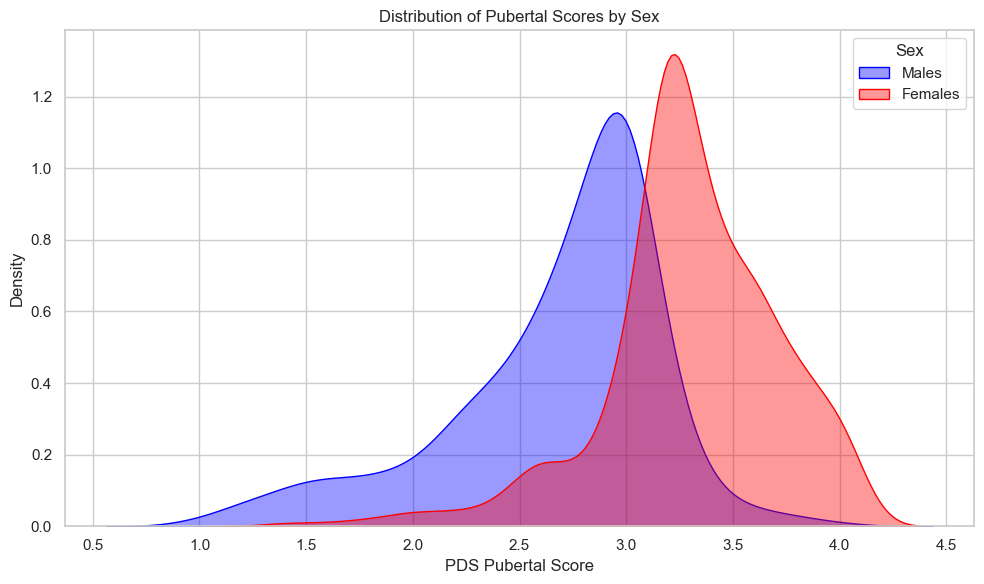

In [52]:
### Density plots
# This uses kernel density estimation (kdeplot) to visualize distributions smoothly.
# You can also adjust alpha to change transparency and fill=False if you'd prefer just the outline.

# Set style
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(10, 6))

# Plot male distribution
sns.kdeplot(
    data=abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'],
    x='pds_p_score',
    label='Males',
    color='blue',
    fill=True,
    alpha=0.4
)

# Plot female distribution
sns.kdeplot(
    data=abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'],
    x='pds_p_score',
    label='Females',
    color='red',
    fill=True,
    alpha=0.4
)

# Add labels and title
plt.xlabel("PDS Pubertal Score")
plt.ylabel("Density")
plt.title("Distribution of Pubertal Scores by Sex")
plt.legend(title="Sex")
plt.tight_layout()
plt.show()


#### CBCL

Describe total symptoms and symptom diensions

In [219]:
print("CBCL Total Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_fu4y_clean.cbcl_tot[abcd_demo_fu4y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.cbcl_tot[abcd_demo_fu4y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu4y_clean.cbcl_tot[abcd_demo_fu4y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.cbcl_tot[abcd_demo_fu4y_clean.sex == 'M']):.2f}")

print("\nCBCL Internalizing Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_fu4y_clean.cbcl_int[abcd_demo_fu4y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.cbcl_int[abcd_demo_fu4y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu4y_clean.cbcl_int[abcd_demo_fu4y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.cbcl_int[abcd_demo_fu4y_clean.sex == 'M']):.2f}")

print("\nCBCL Externalizing Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_fu4y_clean.cbcl_ext[abcd_demo_fu4y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.cbcl_ext[abcd_demo_fu4y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu4y_clean.cbcl_ext[abcd_demo_fu4y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.cbcl_ext[abcd_demo_fu4y_clean.sex == 'M']):.2f}")

CBCL Total Symptoms
Females: Mean: 14.35, SD: 15.21
Males: Mean: 14.45, SD: 14.93

CBCL Internalizing Symptoms
Females: Mean: 6.10, SD: 6.67
Males: Mean: 4.30, SD: 4.99

CBCL Externalizing Symptoms
Females: Mean: 2.72, SD: 4.28
Males: Mean: 3.57, SD: 4.94


In [220]:
print("CBCL Total Symptoms")
print(stats.levene(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].cbcl_tot, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].cbcl_tot, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].cbcl_tot, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].cbcl_tot, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

print("\nCBCL Internalizing Symptoms")
print(stats.levene(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].cbcl_int, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].cbcl_int, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].cbcl_int, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].cbcl_int, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

print("\nCBCL Externalizing Symptoms")
print(stats.levene(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].cbcl_ext, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].cbcl_ext, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].cbcl_ext, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].cbcl_ext, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

CBCL Total Symptoms
LeveneResult(statistic=0.6545929772097366, pvalue=0.4186758095792642)
FlignerResult(statistic=1.5654364644861114, pvalue=0.21087098933513648)

CBCL Internalizing Symptoms
LeveneResult(statistic=10.689729197162693, pvalue=0.0011156164925792144)
FlignerResult(statistic=14.627754668421902, pvalue=0.00013097140325053538)

CBCL Externalizing Symptoms
LeveneResult(statistic=9.091978319238645, pvalue=0.002634883197752117)
FlignerResult(statistic=33.46163636685328, pvalue=7.2683609299954204e-09)


In [221]:
print("CBCL Total Symptoms")
print(f"{stats.ttest_ind(abcd_demo_fu4y_clean.cbcl_tot[abcd_demo_fu4y_clean.sex == 'F'], abcd_demo_fu4y_clean.cbcl_tot[abcd_demo_fu4y_clean.sex == 'M'], nan_policy='omit')}")

print("\nCBCL Internalizing Symptoms")
print(f"{stats.ttest_ind(abcd_demo_fu4y_clean.cbcl_int[abcd_demo_fu4y_clean.sex == 'F'], abcd_demo_fu4y_clean.cbcl_int[abcd_demo_fu4y_clean.sex == 'M'], nan_policy='omit')}")

print("\nCBCL Externalizing Symptoms")
print(f"{stats.ttest_ind(abcd_demo_fu4y_clean.cbcl_ext[abcd_demo_fu4y_clean.sex == 'F'], abcd_demo_fu4y_clean.cbcl_ext[abcd_demo_fu4y_clean.sex == 'M'], nan_policy='omit')}")

CBCL Total Symptoms
TtestResult(statistic=-0.10273596154112304, pvalue=0.918193987134748, df=960.0)

CBCL Internalizing Symptoms
TtestResult(statistic=4.759950880941221, pvalue=2.234281786027258e-06, df=960.0)

CBCL Externalizing Symptoms
TtestResult(statistic=-2.8412870906643, pvalue=0.004588265153269899, df=960.0)


In [222]:
print("CBCL Total Symptoms")
print(stats.mannwhitneyu(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].cbcl_tot, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].cbcl_tot, nan_policy='omit'))

print("\nCBCL Internalizing Symptoms")
print(stats.mannwhitneyu(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].cbcl_int, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].cbcl_int, nan_policy='omit'))

print("\nCBCL Externalizing Symptoms")
print(stats.mannwhitneyu(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].cbcl_ext, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].cbcl_ext, nan_policy='omit'))

CBCL Total Symptoms
MannwhitneyuResult(statistic=114156.5, pvalue=0.7619248866893676)

CBCL Internalizing Symptoms
MannwhitneyuResult(statistic=94030.5, pvalue=5.519240366278848e-07)

CBCL Externalizing Symptoms
MannwhitneyuResult(statistic=125257.5, pvalue=0.019716624664127182)


Checking NaNs

In [223]:
abcd_demo_fu4y_clean["cbcl_tot"].isna().sum()

1

In [224]:
abcd_demo_fu4y_clean["cbcl_int"].isna().sum()

1

In [225]:
abcd_demo_fu4y_clean["cbcl_ext"].isna().sum()

1

In [226]:
abcd_demo_fu4y_clean[abcd_demo_fu4y_clean["cbcl_tot"].isna()]

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
83,sub-NDARINV2GDYKWG2,10.0,F,18.0,4_year_follow_up_y_arm_1,site06,8812.0,168.0,4.0,4.0,3.4,3.4,0.141732,187139.982964,NaN,NaN,NaN,8.0


#### Family Conflict (FES)

In [227]:
abcd_demo_fu4y_clean.fam_conflict_y.value_counts()

fam_conflict_y
0.0    264
1.0    193
2.0    156
3.0    104
4.0     91
5.0     72
6.0     39
7.0     28
8.0      8
9.0      8
Name: count, dtype: int64

In [228]:
print(f"Females: Mean: {np.mean(abcd_demo_fu4y_clean.fam_conflict_y[abcd_demo_fu4y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.fam_conflict_y[abcd_demo_fu4y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu4y_clean.fam_conflict_y[abcd_demo_fu4y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.fam_conflict_y[abcd_demo_fu4y_clean.sex == 'M']):.2f}")

Females: Mean: 2.43, SD: 2.25
Males: Mean: 1.97, SD: 1.97


In [229]:
print(stats.levene(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].fam_conflict_y, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].fam_conflict_y, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

LeveneResult(statistic=7.678579321114652, pvalue=0.005695863771230766)
FlignerResult(statistic=12.14883309519537, pvalue=0.0004911858691007705)


In [230]:
print(f"{stats.ttest_ind(abcd_demo_fu4y_clean.fam_conflict_y[abcd_demo_fu4y_clean.sex == 'F'], abcd_demo_fu4y_clean.fam_conflict_y[abcd_demo_fu4y_clean.sex == 'M'], nan_policy='omit')}")

TtestResult(statistic=3.340541819024428, pvalue=0.0008683378931424615, df=961.0)


In [231]:
print(stats.mannwhitneyu(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].fam_conflict_y, nan_policy='omit'))

MannwhitneyuResult(statistic=103573.0, pvalue=0.004152139802154871)


Checking NaNs

In [232]:
abcd_demo_fu4y_clean["fam_conflict_y"].isna().sum()

0

#### BMI z-score (relative to age and sex - with reference to the CDC 2000 Growth Charts)

In [234]:
print(f"Females: Mean: {np.mean(abcd_demo_fu4y_clean.BMIz[abcd_demo_fu4y_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.BMIz[abcd_demo_fu4y_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_fu4y_clean.BMIz[abcd_demo_fu4y_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_fu4y_clean.BMIz[abcd_demo_fu4y_clean.sex == 'M']):.2f}")

Females: Mean: 0.63, SD: 1.04
Males: Mean: 0.39, SD: 1.23


In [235]:
print(stats.levene(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].BMIz, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].BMIz, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].BMIz, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].BMIz, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

LeveneResult(statistic=11.254810273533915, pvalue=0.0008253333861632533)
FlignerResult(statistic=11.151206310169254, pvalue=0.0008397704747122695)


In [236]:
print(f"{stats.ttest_ind(abcd_demo_fu4y_clean.BMIz[abcd_demo_fu4y_clean.sex == 'F'], abcd_demo_fu4y_clean.BMIz[abcd_demo_fu4y_clean.sex == 'M'], nan_policy='omit')}")

TtestResult(statistic=3.233469687115265, pvalue=0.0012647586348872256, df=958.0)


In [237]:
print(stats.mannwhitneyu(abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'M'].BMIz, abcd_demo_fu4y_clean[abcd_demo_fu4y_clean['sex'] == 'F'].BMIz, nan_policy='omit'))

MannwhitneyuResult(statistic=102272.0, pvalue=0.002979341417868055)


Checking NaNs

In [238]:
abcd_demo_fu4y_clean["BMIz"].isna().sum()

3

### full

In [28]:
print(f"{np.sum(abcd_demo_all_clean.sex == 'F')} females, {np.sum(abcd_demo_all_clean.sex == 'M')} males")

3220 females, 3103 males


#### Age

In [57]:
print(f"Mean age (months): {np.mean(abcd_demo_all_clean.age_months):.2f}, sd: {np.std(abcd_demo_all_clean.age_months):.2f}")
print(f"Mean age (months) - Males: {np.mean(abcd_demo_all_clean.age_months[abcd_demo_all_clean.sex == 'M']):.2f}")
print(f"Mean age (months) - Females: {np.mean(abcd_demo_all_clean.age_months[abcd_demo_all_clean.sex == 'F']):.2f}")

print(f"Min age (months): {np.min(abcd_demo_all_clean.age_months):.2f}")
print(f"Max age (months): {np.max(abcd_demo_all_clean.age_months):.2f}")

Mean age (months): 132.11, sd: 19.85
Mean age (months) - Males: 132.96
Mean age (months) - Females: 131.29
Min age (months): 107.00
Max age (months): 187.00


/tmp/ipykernel_76894/3866318734.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Females", "Males"])


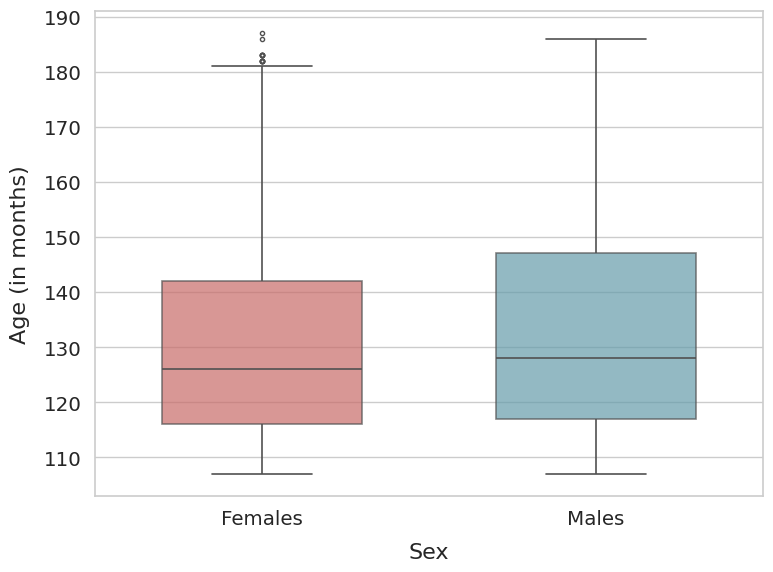

In [58]:

# Style setup
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
#sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)

plt.rcParams["axes.linewidth"] = 1.2  # thicker axes for cleaner appearance
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create figure
plt.figure(figsize=(8, 6))

# Boxplot
ax = sns.boxplot(
    data=abcd_demo_all_clean,
    x="sex",
    y="age_months",
    hue="sex",
    palette={"F": "#d85c59", "M": "#5aa3b5"},  # palette={'M': 'cadetblue', 'F': 'lightcoral'},
    dodge=False,
    width=0.6,
    linewidth=1.2,
    fliersize=3,
    boxprops={"alpha": 0.7},
)

#sns.despine(trim=True)

# Axis labels and title
ax.set_xlabel("Sex", fontsize=16, labelpad=10)
ax.set_ylabel("Age (in months)", fontsize=16, labelpad=10)
ax.set_xticklabels(["Females", "Males"])
#ax.set_title("Age (in months) by Sex", pad=15, weight="bold")


# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(resdir_fig+"boxplot_age_by_sex.svg", format="svg", bbox_inches="tight", dpi=300)

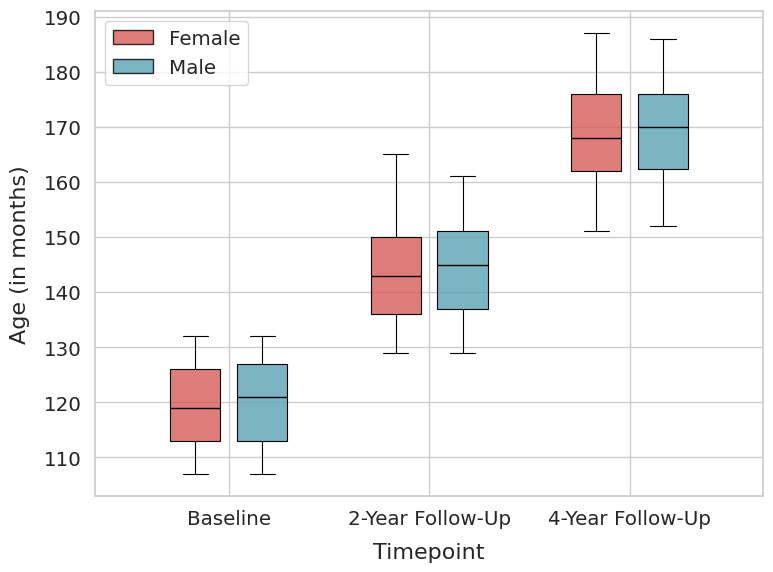

In [59]:
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

alpha_map = {
    "Baseline": 0.8,  # 0.8
    "2-Year Follow-Up": 0.8,  # 0.6
    "4-Year Follow-Up": 0.8  # 0.3
}

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

data = [
    abcd_demo_baseline_clean,
    abcd_demo_fu2y_clean,
    abcd_demo_fu4y_clean
]

# --- Style setup (consistent with your manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axes ---
fig, ax = plt.subplots(figsize=(8, 6))

# --- Function to draw SEX-SPLIT boxplots with TIMEPOINT alpha ---
def draw_boxplots(ax, data):

    box_width = 0.25
    offsets = [-box_width / 1.5, box_width / 1.5]  # F left, M right

    for tp_idx, tp in enumerate(timepoints):

        df_tp = data[tp_idx]
        alpha = alpha_map[tp]

        for sex_idx, sex in enumerate(["F", "M"]):

            df_sex = df_tp[df_tp["sex"] == sex]["age_months"].dropna()

            color = sex_palette[sex]
            rgba = mcolors.to_rgba(color, alpha=alpha)

            position = tp_idx + offsets[sex_idx]

            bp = ax.boxplot(
                df_sex,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                boxprops=dict(facecolor=rgba, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8),
                flierprops=dict(
                    marker='o',
                    markersize=3,
                    alpha=0.5,
                    markerfacecolor='black',
                    markeredgecolor='black'
                )
            )


# --- Draw boxplots ---
draw_boxplots(ax, data)

# --- Axis labels ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("Age (in months)", fontsize=16, labelpad=10)

# --- Legend (Sex only, alpha encoded visually) ---
legend_elements = [
    Patch(facecolor=sex_palette["F"], alpha=0.8, edgecolor="black", label="Female"),
    Patch(facecolor=sex_palette["M"], alpha=0.8, edgecolor="black", label="Male"),
]
ax.legend(handles=legend_elements, loc="upper left", frameon=True)




# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(
    resdir_fig + "boxplot_age_by_sex_by_timepoint.svg",
    format="svg",
    bbox_inches="tight",
    dpi=300
)


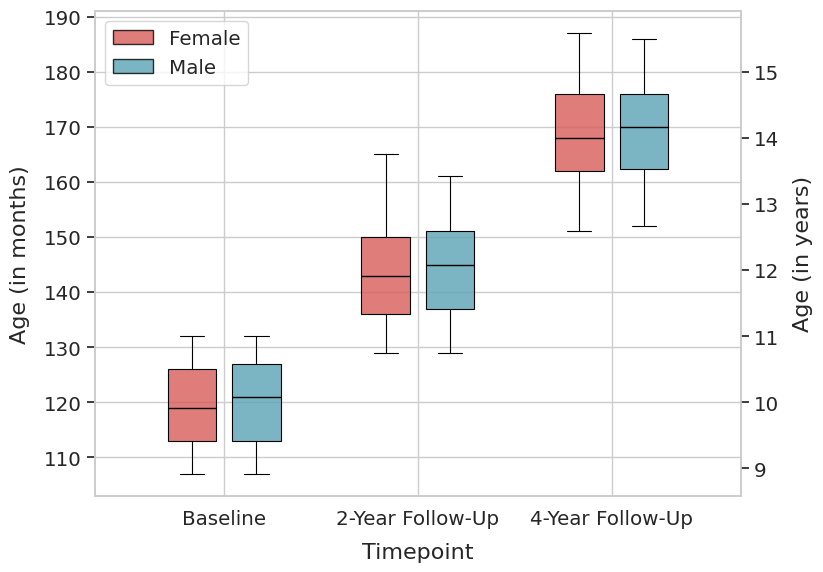

In [65]:
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

alpha_map = {
    "Baseline": 0.8,  # 0.8
    "2-Year Follow-Up": 0.8,  # 0.6
    "4-Year Follow-Up": 0.8  # 0.3
}

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

data = [
    abcd_demo_baseline_clean,
    abcd_demo_fu2y_clean,
    abcd_demo_fu4y_clean
]

# --- Style setup (consistent with your manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axes ---
fig, ax = plt.subplots(figsize=(8.5, 6))

# --- Function to draw SEX-SPLIT boxplots with TIMEPOINT alpha ---
def draw_boxplots(ax, data):

    box_width = 0.25
    offsets = [-box_width / 1.5, box_width / 1.5]  # F left, M right

    for tp_idx, tp in enumerate(timepoints):

        df_tp = data[tp_idx]
        alpha = alpha_map[tp]

        for sex_idx, sex in enumerate(["F", "M"]):

            df_sex = df_tp[df_tp["sex"] == sex]["age_months"].dropna()

            color = sex_palette[sex]
            rgba = mcolors.to_rgba(color, alpha=alpha)

            position = tp_idx + offsets[sex_idx]

            bp = ax.boxplot(
                df_sex,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                boxprops=dict(facecolor=rgba, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8),
                flierprops=dict(
                    marker='o',
                    markersize=3,
                    alpha=0.5,
                    markerfacecolor='black',
                    markeredgecolor='black'
                )
            )


# --- Draw boxplots ---
draw_boxplots(ax, data)


# --- Axis labels and primary formatting ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("Age (in months)", fontsize=16, labelpad=10)

# --- Create the second y-axis (Age in years) ---
ax2 = ax.twinx()  # Create a twin axis sharing the x-axis

# Synchronize the limits: 
# We get the current month limits and convert them to years for the second axis
y_min, y_max = ax.get_ylim()
ax2.set_ylim(y_min / 12, y_max / 12)

ax2.set_ylabel("Age (in years)", fontsize=16, labelpad=10)
ax2.grid(False) # Usually cleaner to turn off the second grid

# --- Legend and final touches ---
legend_elements = [
    Patch(facecolor=sex_palette["F"], alpha=0.8, edgecolor="black", label="Female"),
    Patch(facecolor=sex_palette["M"], alpha=0.8, edgecolor="black", label="Male"),
]
ax.legend(handles=legend_elements, loc="upper left", frameon=True)

plt.tight_layout()


#plt.show()

plt.savefig(
    resdir_fig + "boxplot_age_by_sex_by_timepoint_2yaxes.svg",
    format="svg",
    bbox_inches="tight",
    dpi=300
)


#### Total SA

In [245]:
print("mm2")
print(f"Total SA in Females: Mean: {np.mean(abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'F']):.2f}") 
print(f"Total SA in Males: Mean: {np.mean(abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'M']):.2f}")

print("\ncm2")
print(f"Total SA in Females: Mean: {np.mean(abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'F']/100):.2f}, SD: {np.std(abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'F']/100):.2f}") 
print(f"Total SA in Males: Mean: {np.mean(abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'M']/100):.2f}, SD: {np.std(abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'M']/100):.2f}")


mm2
Total SA in Females: Mean: 190562.85, SD: 15326.11
Total SA in Males: Mean: 208477.97, SD: 16964.16

cm2
Total SA in Females: Mean: 1905.63, SD: 153.26
Total SA in Males: Mean: 2084.78, SD: 169.64


In [246]:
stats.ttest_ind(abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'F'], abcd_demo_all_clean.tot_SA[abcd_demo_all_clean.sex == 'M'])

TtestResult(statistic=-44.08750091650531, pvalue=0.0, df=6321.0)

#### Puberty

In [247]:
print(f"Males: median = {statistics.median(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].pds_p_score)}, mean = {round(statistics.mean(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].pds_p_score),2)}, sd = {round(statistics.stdev(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].pds_p_score),2)}") 
print(f"Females: median = {statistics.median(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].pds_p_score)}, mean = {round(statistics.mean(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].pds_p_score),2)}, sd = {round(statistics.stdev(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].pds_p_score),2)}") 

print()

print(stats.mannwhitneyu(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].pds_p_score, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].pds_p_score))
#print(stats.levene(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].pds_p_score, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].pds_p_score, center='median'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
#print(stats.fligner(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].pds_p_score, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].pds_p_score))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data


Males: median = 1.4, mean = 1.69, sd = 0.63
Females: median = 2.0, mean = 2.1, sd = 0.78

MannwhitneyuResult(statistic=3396628.0, pvalue=9.12429657572138e-109)


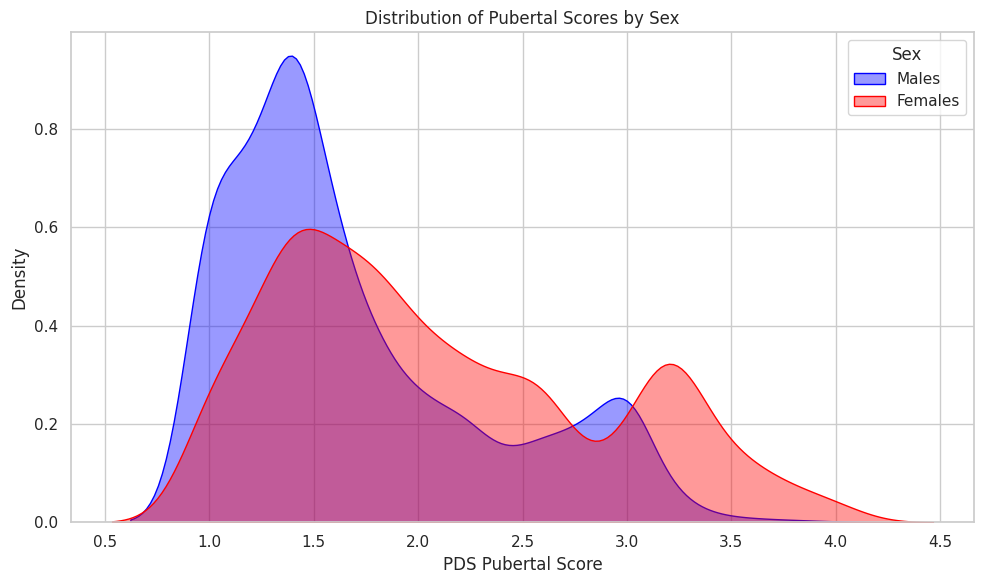

In [248]:
### Density plots
# This uses kernel density estimation (kdeplot) to visualize distributions smoothly.
# You can also adjust alpha to change transparency and fill=False if you'd prefer just the outline.

# Set style
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(10, 6))

# Plot male distribution
sns.kdeplot(
    data=abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'],
    x='pds_p_score',
    label='Males',
    color='blue',
    fill=True,
    alpha=0.4
)

# Plot female distribution
sns.kdeplot(
    data=abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'],
    x='pds_p_score',
    label='Females',
    color='red',
    fill=True,
    alpha=0.4
)

# Add labels and title
plt.xlabel("PDS Pubertal Score")
plt.ylabel("Density")
plt.title("Distribution of Pubertal Scores by Sex")
plt.legend(title="Sex")
plt.tight_layout()
plt.show()


/tmp/ipykernel_60461/3956193913.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Females", "Males"])


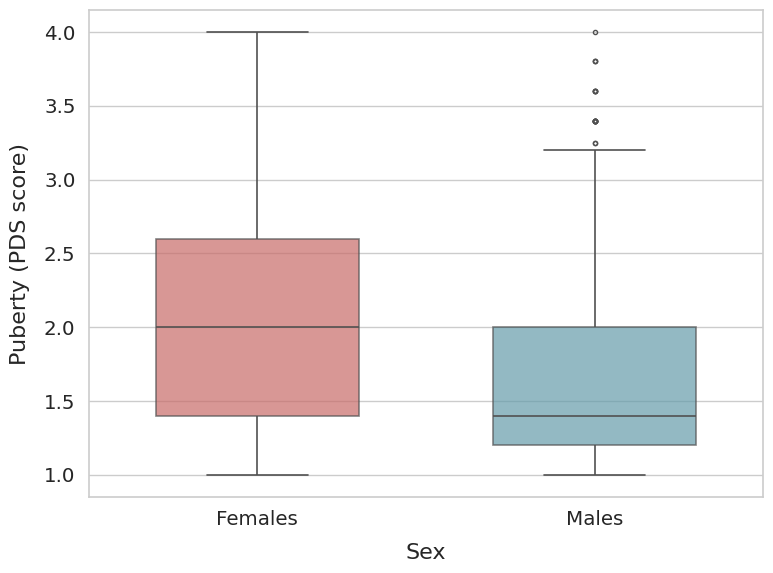

In [249]:

# Style setup
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
#sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)

plt.rcParams["axes.linewidth"] = 1.2  # thicker axes for cleaner appearance
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create figure
plt.figure(figsize=(8, 6))

# Boxplot
ax = sns.boxplot(
    data=abcd_demo_all_clean,
    x="sex",
    y="pds_p_score",
    hue="sex",
    palette={"F": "#d85c59", "M": "#5aa3b5"},  # palette={'M': 'cadetblue', 'F': 'lightcoral'},
    dodge=False,
    width=0.6,
    linewidth=1.2,
    fliersize=3,
    boxprops={"alpha": 0.7},
)

#sns.despine(trim=True)

# Axis labels and title
ax.set_xlabel("Sex", fontsize=16, labelpad=10)
ax.set_ylabel("Puberty (PDS score)", fontsize=16, labelpad=10)
ax.set_xticklabels(["Females", "Males"])
#ax.set_title("Pubertal Scores by Sex", pad=15, weight="bold")

# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(resdir_fig+"boxplot_pds_by_sex.svg", format="svg", bbox_inches="tight", dpi=300)

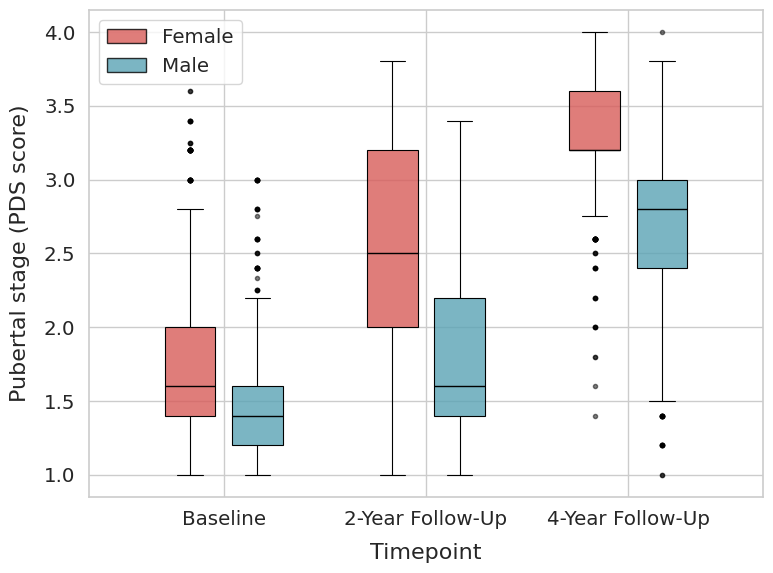

In [250]:
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

alpha_map = {
    "Baseline": 0.8,  # 0.8
    "2-Year Follow-Up": 0.8,  # 0.8
    "4-Year Follow-Up": 0.8  # 0.8
}

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

data = [
    abcd_demo_baseline_clean,
    abcd_demo_fu2y_clean,
    abcd_demo_fu4y_clean
]

# --- Style setup (consistent with your manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axes ---
fig, ax = plt.subplots(figsize=(8, 6))

# --- Function to draw SEX-SPLIT boxplots with TIMEPOINT alpha ---
def draw_boxplots(ax, data):

    box_width = 0.25
    offsets = [-box_width / 1.5, box_width / 1.5]  # F left, M right

    for tp_idx, tp in enumerate(timepoints):

        df_tp = data[tp_idx]
        alpha = alpha_map[tp]

        for sex_idx, sex in enumerate(["F", "M"]):

            df_sex = df_tp[df_tp["sex"] == sex]["pds_p_score"].dropna()

            color = sex_palette[sex]
            rgba = mcolors.to_rgba(color, alpha=alpha)

            position = tp_idx + offsets[sex_idx]

            bp = ax.boxplot(
                df_sex,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                boxprops=dict(facecolor=rgba, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8),
                flierprops=dict(
                    marker='o',
                    markersize=3,
                    alpha=0.5,
                    markerfacecolor='black',
                    markeredgecolor='black'
                )
            )


# --- Draw boxplots ---
draw_boxplots(ax, data)

# --- Axis labels ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("Pubertal stage (PDS score)", fontsize=16, labelpad=10)

# --- Legend (Sex only, alpha encoded visually) ---
legend_elements = [
    Patch(facecolor=sex_palette["F"], alpha=0.8, edgecolor="black", label="Female"),
    Patch(facecolor=sex_palette["M"], alpha=0.8, edgecolor="black", label="Male"),
]
ax.legend(handles=legend_elements, loc="upper left", frameon=True)




# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(
    resdir_fig + "boxplot_pds_by_sex_by_timepoint.svg",
    format="svg",
    bbox_inches="tight",
    dpi=300
)


#### Collinearity age-puberty

In [72]:
stats.spearmanr(abcd_demo_all_clean.age_months, abcd_demo_all_clean.pds_p_score)

SignificanceResult(statistic=0.5850204095421869, pvalue=0.0)

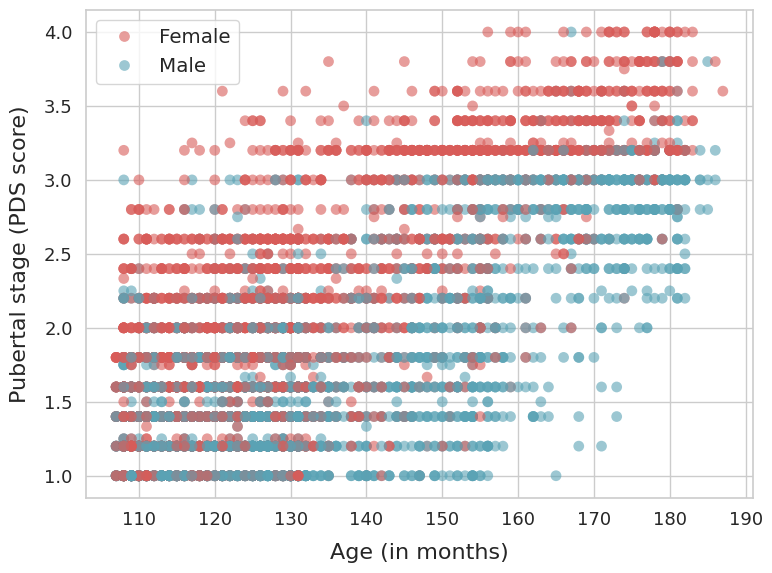

In [89]:

df_plot = abcd_demo_all_clean[['age_months', 'pds_p_score', 'sex']]

# --- Plot setup ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

fig, ax = plt.subplots(figsize=(8, 6))

# Define the colors used in your previous plot
sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

# --- Scatterplot (color-coded by Sex) ---
sns.scatterplot(
    data=df_plot,
    x="age_months", 
    y="pds_p_score",
    hue="sex",           # Map color to sex
    palette=sex_palette, # Use your specific colors
    s=60, 
    alpha=0.6,           # Reduced alpha slightly to see overlapping points
    edgecolor="none",    # Removing edgecolors makes high-density plots cleaner
    ax=ax
)

# --- Aesthetics ---
ax.set_xlabel("Age (in months)", fontsize=16, labelpad=10)
ax.set_ylabel("Pubertal stage (PDS score)", fontsize=16, labelpad=10)
ax.tick_params(labelsize=13)

# --- Legend ---
# This creates a clean legend using your palette labels
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=['Female', 'Male'], loc='upper left')

plt.tight_layout()
#plt.show()


# save figure in directory 
plt.savefig(resdir_fig+'age_puberty_correspondance.svg', dpi=300, bbox_inches="tight")  # bbox_inches is so that the figure doesn't get cut off when saving

In [73]:
from statsmodels.stats.outliers_influence import variance_inflation_factor


# Create a subset of your predictors
X = abcd_demo_all_clean[['age_months', 'pds_p_score']]

# Add a constant (required for VIF calculation)
X['intercept'] = 1

vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]
print(vif_data)

       feature        VIF
0   age_months   1.955052
1  pds_p_score   1.955052
2    intercept  53.747553


/tmp/ipykernel_76894/2572699726.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['intercept'] = 1


#### Race

In [130]:
abcd_p_demo = pd.read_csv(datadir+'abcd-data-release-5.1/core/abcd-general/abcd_p_demo.csv')
abcd_p_demo

,src_subject_id,eventname,demoi_p_select_language___1,demo_prim,demo_brthdat_v2,demo_ed_v2,demo_adopt_agex_v2,demo_adopt_agex_v2_bl_dk,demo_sex_v2,demo_gender_id_v2,...,demo_nat_lang_3_yrs_other_p_14,demo_nat_lang_3_p,demo_nat_lang_3_yrs_eng_p___1,demo_nat_lang_3_yrs_eng_p___2,demo_nat_lang_3_yrs_eng_p___3,demo_nat_lang_3_yrs_eng_p___4,demo_nat_lang_3_yrs_eng_p___5,demo_nat_lang_3_yrs_eng_p___6,race_ethnicity,acs_raked_propensity_score
0,NDAR_INV003RTV85,baseline_year_1_arm_1,0,1.0,10.0,5.0,NaN,NaN,2.0,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,466.092707
1,NDAR_INV003RTV85,1_year_follow_up_y_arm_1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,533.381820
2,NDAR_INV003RTV85,2_year_follow_up_y_arm_1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NDAR_INV003RTV85,3_year_follow_up_y_arm_1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NDAR_INV005V6D2C,baseline_year_1_arm_1,1,1.0,10.0,4.0,NaN,NaN,2.0,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,520.488325
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48802,NDAR_INVZZZP87KR,baseline_year_1_arm_1,0,1.0,10.0,5.0,NaN,NaN,2.0,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,835.604891
48803,NDAR_INVZZZP87KR,1_year_follow_up_y_arm_1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,842.080358
48804,NDAR_INVZZZP87KR,2_year_follow_up_y_arm_1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
48805,NDAR_INVZZZP87KR,3_year_follow_up_y_arm_1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [131]:
# take one entry per subject because we only need the information once (baseline has the info for all)
abcd_p_demo_overall =  abcd_p_demo[abcd_p_demo['eventname'] == 'baseline_year_1_arm_1']

# Create a new column with the reformatted IDs to match IDs in MPI folders
abcd_p_demo_overall['src_subject_id_fmt'] = abcd_p_demo_overall['src_subject_id'].apply(lambda x: 'sub-' + x.replace('_INV', 'INV'))


# only keep subjects that are in the final sample
abcd_p_demo_overall = abcd_p_demo_overall[abcd_p_demo_overall['src_subject_id_fmt'].isin(abcd_demo_all_clean.src_subject_id_fmt)]


# taking only a subset of df with relevant race columns
abcd_p_demo_overall = abcd_p_demo_overall[["src_subject_id_fmt", 'demo_race_a_p___10', 'demo_race_a_p___11', 'demo_race_a_p___12', 'demo_race_a_p___13', "demo_race_a_p___14", "demo_race_a_p___15","demo_race_a_p___16", 
                                             "demo_race_a_p___17", "demo_race_a_p___18", "demo_race_a_p___19", "demo_race_a_p___20", "demo_race_a_p___21", "demo_race_a_p___22", "demo_race_a_p___23", "demo_race_a_p___24", 
                                             "demo_race_a_p___25", "demo_race_a_p___0", "demo_race_a_p___77", "demo_race_a_p___99"]]


### Cleaning variables

# renaming some variables
abcd_p_demo_overall = abcd_p_demo_overall.rename(columns={"demo_race_a_p___10": "white", 
                                                                    "demo_race_a_p___11": "black", 
                                                                    "demo_race_a_p___12": "indian native", 
                                                                    "demo_race_a_p___13": "alaska native", 
                                                                    "demo_race_a_p___14": "hawaii native", 
                                                                    "demo_race_a_p___15": "guamanian", 
                                                                    "demo_race_a_p___16": "samoan",
                                                                    "demo_race_a_p___17": "other pacific",
                                                                    "demo_race_a_p___18": "asian indian",
                                                                    "demo_race_a_p___19": "chinese",
                                                                    "demo_race_a_p___20": "filipino",
                                                                    "demo_race_a_p___21": "japanese",
                                                                    "demo_race_a_p___22": "korean",
                                                                    "demo_race_a_p___23": "vietnamese",
                                                                    "demo_race_a_p___24": "other asian",
                                                                    "demo_race_a_p___25": "other race", 
                                                                    "demo_race_a_p___0": "none",
                                                                    "demo_race_a_p___77": "decline",
                                                                    "demo_race_a_p___99": "dont know"
                                                                   })



/tmp/ipykernel_13286/2058291093.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  abcd_p_demo_overall['src_subject_id_fmt'] = abcd_p_demo_overall['src_subject_id'].apply(lambda x: 'sub-' + x.replace('_INV', 'INV'))


In [133]:
options = ['white', 'black', 'indian native','alaska native', 'hawaii native', 'guamanian', 'samoan', 'other pacific', 'asian indian', 'chinese', 'filipino', 'japanese','korean', 'vietnamese', 
         'other asian', 'other race', 'none', 'decline', 'dont know']

races = ['white', 'black', 'indian native','alaska native', 'hawaii native', 'guamanian', 'samoan', 'other pacific', 'asian indian', 'chinese', 'filipino', 'japanese','korean', 'vietnamese', 
         'other asian', 'other race']


## create a final race column

# Count actual race selections only
abcd_p_demo_overall["n_races"] = abcd_p_demo_overall[races].sum(axis=1)

# Create race column safely
abcd_p_demo_overall["race"] = pd.NA

# Mixed race
abcd_p_demo_overall.loc[
    abcd_p_demo_overall["n_races"] > 1,
    "race"
] = "mixed"

# Single race (exactly one race selected)
mask_single = abcd_p_demo_overall["n_races"] == 1

abcd_p_demo_overall.loc[mask_single, "race"] = (
    abcd_p_demo_overall.loc[mask_single, races]
    .idxmax(axis=1)
)

# Handle the non-race responses
# none selected
abcd_p_demo_overall.loc[
    (abcd_p_demo_overall["n_races"] == 0) &
    (abcd_p_demo_overall["none"] == 1),
    "race"
] = "none"

# decline
abcd_p_demo_overall.loc[
    (abcd_p_demo_overall["n_races"] == 0) &
    (abcd_p_demo_overall["decline"] == 1),
    "race"
] = "decline"

# dont know
abcd_p_demo_overall.loc[
    (abcd_p_demo_overall["n_races"] == 0) &
    (abcd_p_demo_overall["dont know"] == 1),
    "race"
] = "dont know"

# replace na values with a string "NaN" so that it appears in the counts
abcd_p_demo_overall["race"] = (
    abcd_p_demo_overall["race"]
    .fillna("NaN")
)


## map races into categories

race_map = {
    # keep as is
    "white": "white",
    "black": "black",
    "mixed": "mixed",
    
    # asian
    "asian indian": "asian",
    "chinese": "asian",
    "filipino": "asian",
    "japanese": "asian",
    "korean": "asian",
    "vietnamese": "asian",
    "other asian": "asian",
    
    # pacific islander
    "hawaii native": "pacific islander",
    "guamanian": "pacific islander",
    "samoan": "pacific islander",
    "other pacific": "pacific islander",
    
    # native american
    "indian native": "native american",
    "alaska native": "native american",
    
    # other
    "other race": "other",
    
    # missing
    "none": "missing",
    "dont know": "missing",
    "decline": "missing",
    "NaN": "missing"
}

abcd_p_demo_overall["race cat"] = (
    abcd_p_demo_overall["race"]
    .map(race_map)
)


In [134]:
abcd_p_demo_overall

,src_subject_id_fmt,white,black,indian native,alaska native,hawaii native,guamanian,samoan,other pacific,asian indian,...,korean,vietnamese,other asian,other race,none,decline,dont know,n_races,race,race cat
0,sub-NDARINV003RTV85,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,white,white
8,sub-NDARINV007W6H7B,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,white,white
14,sub-NDARINV00CY2MDM,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,white,white
19,sub-NDARINV00HEV6HB,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,black,black
24,sub-NDARINV00J52GPG,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,decline,missing
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48767,sub-NDARINVZZFG6J5U,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,white,white
48785,sub-NDARINVZZNX6W2P,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,white,white
48790,sub-NDARINVZZPKBDAC,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,white,white
48795,sub-NDARINVZZZ2ALR6,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,mixed,mixed


In [135]:
abcd_p_demo_overall['race'].value_counts()

race
white            3484
mixed             576
black             509
other race        172
dont know          30
chinese            30
indian native      28
asian indian       21
decline            15
other asian        14
filipino           11
NaN                 8
vietnamese          7
korean              6
japanese            3
other pacific       3
samoan              2
Name: count, dtype: int64

In [136]:
abcd_p_demo_overall['race cat'].value_counts()

race cat
white               3484
mixed                576
black                509
other                172
asian                 92
missing               53
native american       28
pacific islander       5
Name: count, dtype: int64

In [142]:
abcd_p_demo_overall["race cat"] \
    .value_counts(normalize=True) \
    .mul(100) \
    .round(1)

race cat
white               70.8
mixed               11.7
black               10.3
other                3.5
asian                1.9
missing              1.1
native american      0.6
pacific islander     0.1
Name: proportion, dtype: float64

#### CBCL

Describe total symptoms and symptom diensions

In [103]:
print("CBCL Total Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_all_clean.cbcl_tot[abcd_demo_all_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_all_clean.cbcl_tot[abcd_demo_all_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_all_clean.cbcl_tot[abcd_demo_all_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_all_clean.cbcl_tot[abcd_demo_all_clean.sex == 'M']):.2f}")

print("\nCBCL Internalizing Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_all_clean.cbcl_int[abcd_demo_all_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_all_clean.cbcl_int[abcd_demo_all_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_all_clean.cbcl_int[abcd_demo_all_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_all_clean.cbcl_int[abcd_demo_all_clean.sex == 'M']):.2f}")

print("\nCBCL Externalizing Symptoms")
print(f"Females: Mean: {np.mean(abcd_demo_all_clean.cbcl_ext[abcd_demo_all_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_all_clean.cbcl_ext[abcd_demo_all_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_all_clean.cbcl_ext[abcd_demo_all_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_all_clean.cbcl_ext[abcd_demo_all_clean.sex == 'M']):.2f}")

CBCL Total Symptoms
Females: Mean: 15.04, SD: 15.06
Males: Mean: 17.45, SD: 17.53

CBCL Internalizing Symptoms
Females: Mean: 5.25, SD: 5.61
Males: Mean: 4.79, SD: 5.34

CBCL Externalizing Symptoms
Females: Mean: 3.33, SD: 4.68
Males: Mean: 4.39, SD: 5.86


In [104]:
print("CBCL Total Symptoms")
print(stats.levene(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].cbcl_tot, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].cbcl_tot, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].cbcl_tot, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].cbcl_tot, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

print("\nCBCL Internalizing Symptoms")
print(stats.levene(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].cbcl_int, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].cbcl_int, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].cbcl_int, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].cbcl_int, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

print("\nCBCL Externalizing Symptoms")
print(stats.levene(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].cbcl_ext, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].cbcl_ext, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].cbcl_ext, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].cbcl_ext, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

CBCL Total Symptoms
LeveneResult(statistic=25.050822401173516, pvalue=5.735100883504716e-07)
FlignerResult(statistic=40.861178301485204, pvalue=1.634357329423899e-10)

CBCL Internalizing Symptoms
LeveneResult(statistic=4.565922729924627, pvalue=0.03265240516086229)
FlignerResult(statistic=25.132986602559846, pvalue=5.350965716544322e-07)

CBCL Externalizing Symptoms
LeveneResult(statistic=54.439800132035465, pvalue=1.8087765338734176e-13)
FlignerResult(statistic=51.45564941940058, pvalue=7.32329395608101e-13)


In [105]:
print("CBCL Total Symptoms")
print(f"{stats.ttest_ind(abcd_demo_all_clean.cbcl_tot[abcd_demo_all_clean.sex == 'F'], abcd_demo_all_clean.cbcl_tot[abcd_demo_all_clean.sex == 'M'], nan_policy='omit')}")

print("\nCBCL Internalizing Symptoms")
print(f"{stats.ttest_ind(abcd_demo_all_clean.cbcl_int[abcd_demo_all_clean.sex == 'F'], abcd_demo_all_clean.cbcl_int[abcd_demo_all_clean.sex == 'M'], nan_policy='omit')}")

print("\nCBCL Externalizing Symptoms")
print(f"{stats.ttest_ind(abcd_demo_all_clean.cbcl_ext[abcd_demo_all_clean.sex == 'F'], abcd_demo_all_clean.cbcl_ext[abcd_demo_all_clean.sex == 'M'], nan_policy='omit')}")

CBCL Total Symptoms
TtestResult(statistic=-5.874948871151165, pvalue=4.445123599997868e-09, df=6317.0)

CBCL Internalizing Symptoms
TtestResult(statistic=3.2653330827102782, pvalue=0.0010991814079618963, df=6317.0)

CBCL Externalizing Symptoms
TtestResult(statistic=-7.943101192404206, pvalue=2.3173388308024874e-15, df=6317.0)


In [106]:
print("CBCL Total Symptoms")
print(stats.mannwhitneyu(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].cbcl_tot, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].cbcl_tot, nan_policy='omit'))

print("\nCBCL Internalizing Symptoms")
print(stats.mannwhitneyu(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].cbcl_int, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].cbcl_int, nan_policy='omit'))

print("\nCBCL Externalizing Symptoms")
print(stats.mannwhitneyu(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].cbcl_ext, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].cbcl_ext, nan_policy='omit'))

CBCL Total Symptoms
MannwhitneyuResult(statistic=5360732.5, pvalue=2.985428476547452e-07)

CBCL Internalizing Symptoms
MannwhitneyuResult(statistic=4706833.0, pvalue=8.86273634158895e-05)

CBCL Externalizing Symptoms
MannwhitneyuResult(statistic=5495349.0, pvalue=1.2807822199154854e-12)


Checking NaNs

In [107]:
abcd_demo_all_clean["cbcl_tot"].isna().sum()

2

In [108]:
abcd_demo_all_clean["cbcl_int"].isna().sum()

2

In [109]:
abcd_demo_all_clean["cbcl_ext"].isna().sum()

2

In [110]:
abcd_demo_all_clean[abcd_demo_all_clean["cbcl_tot"].isna()]

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMI,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
66,sub-NDARINV1DDX454E,9.0,M,17.0,2_year_follow_up_y_arm_1,site21,4727.0,132.0,1.0,3.0,1.2,2.2,23.144033,217172.631572,NaN,NaN,NaN,NaN
83,sub-NDARINV2GDYKWG2,10.0,F,18.0,4_year_follow_up_y_arm_1,site06,8812.0,168.0,4.0,4.0,3.4,3.4,19.779216,187139.982964,NaN,NaN,NaN,8.0


In [111]:
# Need to remove nans for plotting
abcd_demo_all_clean_omit_nan = abcd_demo_all_clean.dropna(subset=["cbcl_tot", "cbcl_int", "cbcl_ext"])
abcd_demo_baseline_clean_omit_nan = abcd_demo_baseline_clean.dropna(subset=["cbcl_tot", "cbcl_int", "cbcl_ext"])
abcd_demo_fu2y_clean_omit_nan = abcd_demo_fu2y_clean.dropna(subset=["cbcl_tot", "cbcl_int", "cbcl_ext"])
abcd_demo_fu4y_clean_omit_nan = abcd_demo_fu4y_clean.dropna(subset=["cbcl_tot", "cbcl_int", "cbcl_ext"])

Plots = Total Symptoms

/tmp/ipykernel_60461/3294123443.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Females", "Males"])


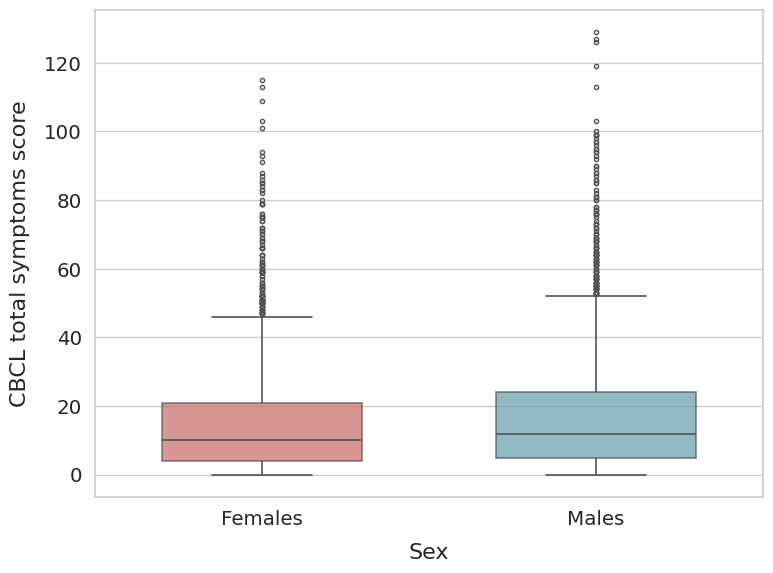

In [112]:
# Style setup
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
#sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)

plt.rcParams["axes.linewidth"] = 1.2  # thicker axes for cleaner appearance
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create figure
plt.figure(figsize=(8, 6))

# Boxplot
ax = sns.boxplot(
    data=abcd_demo_all_clean_omit_nan,
    x="sex",
    y="cbcl_tot",
    hue="sex",
    palette={"F": "#d85c59", "M": "#5aa3b5"},  # palette={'M': 'cadetblue', 'F': 'lightcoral'},
    dodge=False,
    width=0.6,
    linewidth=1.2,
    fliersize=3,
    boxprops={"alpha": 0.7},
)

#sns.despine(trim=True)

# Axis labels and title
ax.set_xlabel("Sex", fontsize=16, labelpad=10)
ax.set_ylabel("CBCL total symptoms score", fontsize=16, labelpad=10)
ax.set_xticklabels(["Females", "Males"])
#ax.set_title("Pubertal Scores by Sex", pad=15, weight="bold")

# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(resdir_fig+"boxplot_cbcl_tot_by_sex.svg", format="svg", bbox_inches="tight", dpi=300)

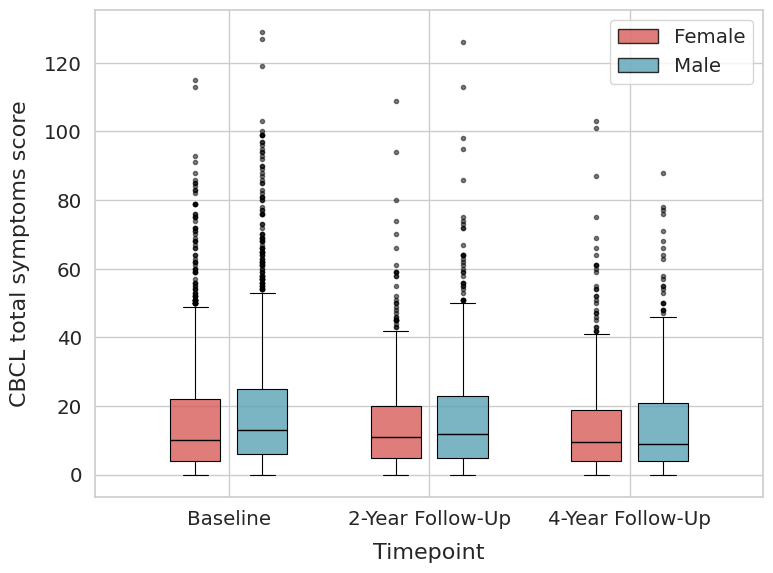

In [113]:
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

alpha_map = {
    "Baseline": 0.8,  # 0.8
    "2-Year Follow-Up": 0.8,  # 0.8
    "4-Year Follow-Up": 0.8  # 0.8
}

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

data = [
    abcd_demo_baseline_clean_omit_nan,
    abcd_demo_fu2y_clean_omit_nan,
    abcd_demo_fu4y_clean_omit_nan
]

# --- Style setup (consistent with your manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axes ---
fig, ax = plt.subplots(figsize=(8, 6))

# --- Function to draw SEX-SPLIT boxplots with TIMEPOINT alpha ---
def draw_boxplots(ax, data):

    box_width = 0.25
    offsets = [-box_width / 1.5, box_width / 1.5]  # F left, M right

    for tp_idx, tp in enumerate(timepoints):

        df_tp = data[tp_idx]
        alpha = alpha_map[tp]

        for sex_idx, sex in enumerate(["F", "M"]):

            df_sex = df_tp[df_tp["sex"] == sex]["cbcl_tot"].dropna()

            color = sex_palette[sex]
            rgba = mcolors.to_rgba(color, alpha=alpha)

            position = tp_idx + offsets[sex_idx]

            bp = ax.boxplot(
                df_sex,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                boxprops=dict(facecolor=rgba, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8),
                flierprops=dict(
                    marker='o',
                    markersize=3,
                    alpha=0.5,
                    markerfacecolor='black',
                    markeredgecolor='black'
                )
            )


# --- Draw boxplots ---
draw_boxplots(ax, data)

# --- Axis labels ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("CBCL total symptoms score", fontsize=16, labelpad=10)

# --- Legend (Sex only, alpha encoded visually) ---
legend_elements = [
    Patch(facecolor=sex_palette["F"], alpha=0.8, edgecolor="black", label="Female"),
    Patch(facecolor=sex_palette["M"], alpha=0.8, edgecolor="black", label="Male"),
]
ax.legend(handles=legend_elements, loc="upper right", frameon=True)




# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(
    resdir_fig + "boxplot_cbcl_tot_by_sex_by_timepoint.svg",
    format="svg",
    bbox_inches="tight",
    dpi=300
)


Plots = Internalizing Symptoms

/tmp/ipykernel_60461/754615528.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Females", "Males"])


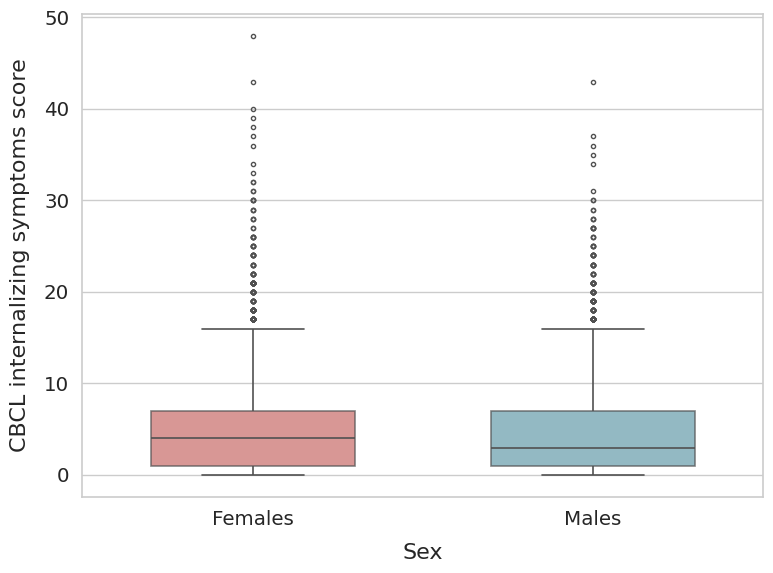

In [114]:
# Style setup
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
#sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)

plt.rcParams["axes.linewidth"] = 1.2  # thicker axes for cleaner appearance
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create figure
plt.figure(figsize=(8, 6))

# Boxplot
ax = sns.boxplot(
    data=abcd_demo_all_clean_omit_nan,
    x="sex",
    y="cbcl_int",
    hue="sex",
    palette={"F": "#d85c59", "M": "#5aa3b5"},  # palette={'M': 'cadetblue', 'F': 'lightcoral'},
    dodge=False,
    width=0.6,
    linewidth=1.2,
    fliersize=3,
    boxprops={"alpha": 0.7},
)

#sns.despine(trim=True)

# Axis labels and title
ax.set_xlabel("Sex", fontsize=16, labelpad=10)
ax.set_ylabel("CBCL internalizing symptoms score", fontsize=16, labelpad=10)
ax.set_xticklabels(["Females", "Males"])
#ax.set_title("Pubertal Scores by Sex", pad=15, weight="bold")

# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(resdir_fig+"boxplot_cbcl_int_by_sex.svg", format="svg", bbox_inches="tight", dpi=300)

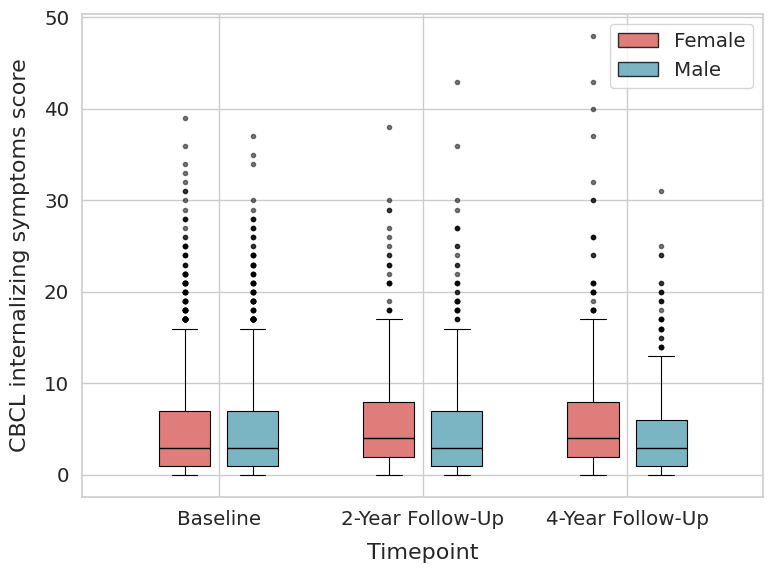

In [115]:
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

alpha_map = {
    "Baseline": 0.8,  # 0.8
    "2-Year Follow-Up": 0.8,  # 0.8
    "4-Year Follow-Up": 0.8  # 0.8
}

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

data = [
    abcd_demo_baseline_clean_omit_nan,
    abcd_demo_fu2y_clean_omit_nan,
    abcd_demo_fu4y_clean_omit_nan
]

# --- Style setup (consistent with your manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axes ---
fig, ax = plt.subplots(figsize=(8, 6))

# --- Function to draw SEX-SPLIT boxplots with TIMEPOINT alpha ---
def draw_boxplots(ax, data):

    box_width = 0.25
    offsets = [-box_width / 1.5, box_width / 1.5]  # F left, M right

    for tp_idx, tp in enumerate(timepoints):

        df_tp = data[tp_idx]
        alpha = alpha_map[tp]

        for sex_idx, sex in enumerate(["F", "M"]):

            df_sex = df_tp[df_tp["sex"] == sex]["cbcl_int"].dropna()

            color = sex_palette[sex]
            rgba = mcolors.to_rgba(color, alpha=alpha)

            position = tp_idx + offsets[sex_idx]

            bp = ax.boxplot(
                df_sex,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                boxprops=dict(facecolor=rgba, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8),
                flierprops=dict(
                    marker='o',
                    markersize=3,
                    alpha=0.5,
                    markerfacecolor='black',
                    markeredgecolor='black'
                )
            )


# --- Draw boxplots ---
draw_boxplots(ax, data)

# --- Axis labels ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("CBCL internalizing symptoms score", fontsize=16, labelpad=10)

# --- Legend (Sex only, alpha encoded visually) ---
legend_elements = [
    Patch(facecolor=sex_palette["F"], alpha=0.8, edgecolor="black", label="Female"),
    Patch(facecolor=sex_palette["M"], alpha=0.8, edgecolor="black", label="Male"),
]
ax.legend(handles=legend_elements, loc="upper right", frameon=True)




# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(
    resdir_fig + "boxplot_cbcl_int_by_sex_by_timepoint.svg",
    format="svg",
    bbox_inches="tight",
    dpi=300
)


Plots = Externalizing Symptoms

/tmp/ipykernel_60461/3452833889.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Females", "Males"])


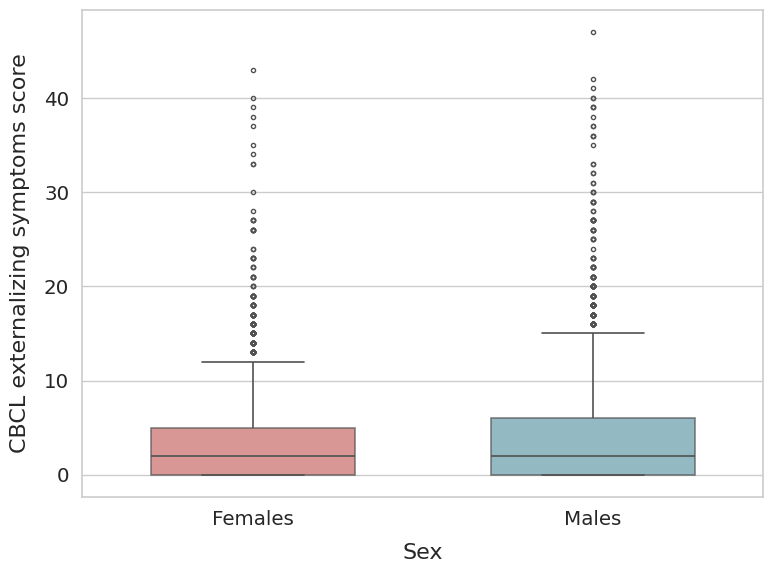

In [116]:
# Style setup
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
#sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)

plt.rcParams["axes.linewidth"] = 1.2  # thicker axes for cleaner appearance
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create figure
plt.figure(figsize=(8, 6))

# Boxplot
ax = sns.boxplot(
    data=abcd_demo_all_clean_omit_nan,
    x="sex",
    y="cbcl_ext",
    hue="sex",
    palette={"F": "#d85c59", "M": "#5aa3b5"},  # palette={'M': 'cadetblue', 'F': 'lightcoral'},
    dodge=False,
    width=0.6,
    linewidth=1.2,
    fliersize=3,
    boxprops={"alpha": 0.7},
)

#sns.despine(trim=True)

# Axis labels and title
ax.set_xlabel("Sex", fontsize=16, labelpad=10)
ax.set_ylabel("CBCL externalizing symptoms score", fontsize=16, labelpad=10)
ax.set_xticklabels(["Females", "Males"])
#ax.set_title("Pubertal Scores by Sex", pad=15, weight="bold")

# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(resdir_fig+"boxplot_cbcl_ext_by_sex.svg", format="svg", bbox_inches="tight", dpi=300)

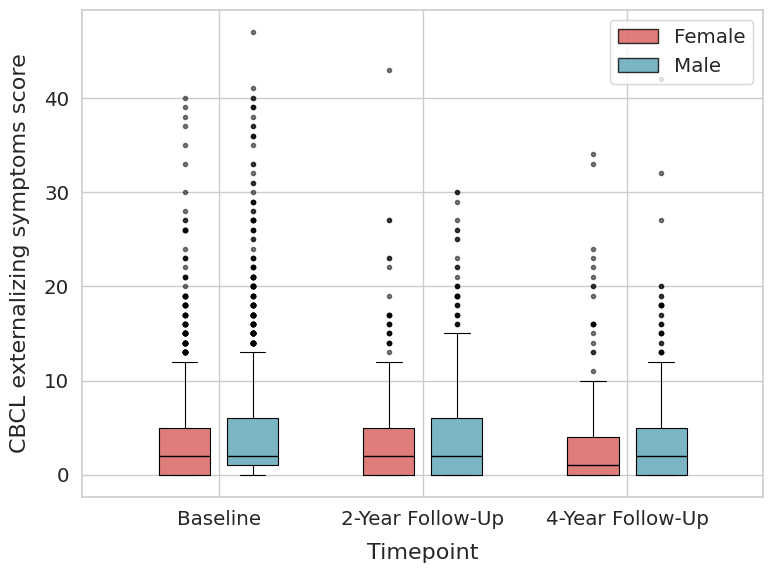

In [117]:
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

alpha_map = {
    "Baseline": 0.8,  # 0.8
    "2-Year Follow-Up": 0.8,  # 0.8
    "4-Year Follow-Up": 0.8  # 0.8
}

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

data = [
    abcd_demo_baseline_clean_omit_nan,
    abcd_demo_fu2y_clean_omit_nan,
    abcd_demo_fu4y_clean_omit_nan
]

# --- Style setup (consistent with your manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axes ---
fig, ax = plt.subplots(figsize=(8, 6))

# --- Function to draw SEX-SPLIT boxplots with TIMEPOINT alpha ---
def draw_boxplots(ax, data):

    box_width = 0.25
    offsets = [-box_width / 1.5, box_width / 1.5]  # F left, M right

    for tp_idx, tp in enumerate(timepoints):

        df_tp = data[tp_idx]
        alpha = alpha_map[tp]

        for sex_idx, sex in enumerate(["F", "M"]):

            df_sex = df_tp[df_tp["sex"] == sex]["cbcl_ext"].dropna()

            color = sex_palette[sex]
            rgba = mcolors.to_rgba(color, alpha=alpha)

            position = tp_idx + offsets[sex_idx]

            bp = ax.boxplot(
                df_sex,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                boxprops=dict(facecolor=rgba, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8),
                flierprops=dict(
                    marker='o',
                    markersize=3,
                    alpha=0.5,
                    markerfacecolor='black',
                    markeredgecolor='black'
                )
            )


# --- Draw boxplots ---
draw_boxplots(ax, data)

# --- Axis labels ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("CBCL externalizing symptoms score", fontsize=16, labelpad=10)

# --- Legend (Sex only, alpha encoded visually) ---
legend_elements = [
    Patch(facecolor=sex_palette["F"], alpha=0.8, edgecolor="black", label="Female"),
    Patch(facecolor=sex_palette["M"], alpha=0.8, edgecolor="black", label="Male"),
]
ax.legend(handles=legend_elements, loc="upper right", frameon=True)




# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(
    resdir_fig + "boxplot_cbcl_ext_by_sex_by_timepoint.svg",
    format="svg",
    bbox_inches="tight",
    dpi=300
)


#### Family Conflict (FES)

In [118]:
abcd_demo_all_clean.fam_conflict_y.value_counts()

fam_conflict_y
0.0    1833
1.0    1446
2.0    1049
3.0     716
4.0     550
5.0     334
6.0     197
7.0     136
8.0      39
9.0      16
Name: count, dtype: int64

In [119]:
print(f"Females: Mean: {np.mean(abcd_demo_all_clean.fam_conflict_y[abcd_demo_all_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_all_clean.fam_conflict_y[abcd_demo_all_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_all_clean.fam_conflict_y[abcd_demo_all_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_all_clean.fam_conflict_y[abcd_demo_all_clean.sex == 'M']):.2f}")

Females: Mean: 1.88, SD: 1.94
Males: Mean: 1.97, SD: 1.91


In [120]:
print(stats.levene(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].fam_conflict_y, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].fam_conflict_y, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

CBCL Total Symptoms
LeveneResult(statistic=0.02368483701231276, pvalue=0.8776944580046452)
FlignerResult(statistic=0.025566407652623812, pvalue=0.8729637955749926)


In [121]:
print(f"{stats.ttest_ind(abcd_demo_all_clean.fam_conflict_y[abcd_demo_all_clean.sex == 'F'], abcd_demo_all_clean.fam_conflict_y[abcd_demo_all_clean.sex == 'M'], nan_policy='omit')}")

TtestResult(statistic=-1.9543288170391635, pvalue=0.05070642072378096, df=6314.0)


In [122]:
print(stats.mannwhitneyu(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].fam_conflict_y, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].fam_conflict_y, nan_policy='omit'))

MannwhitneyuResult(statistic=5180049.0, pvalue=0.005829610084576603)


Checking NaNs

In [123]:
abcd_demo_all_clean["fam_conflict_y"].isna().sum()

5

Plots

In [260]:
# Need to remove nans for plotting  fpr family conflict
abcd_demo_all_clean_omit_nan = abcd_demo_all_clean.dropna(subset=["fam_conflict_y"])
abcd_demo_baseline_clean_omit_nan = abcd_demo_baseline_clean.dropna(subset=["fam_conflict_y"])
abcd_demo_fu2y_clean_omit_nan = abcd_demo_fu2y_clean.dropna(subset=["fam_conflict_y"])
abcd_demo_fu4y_clean_omit_nan = abcd_demo_fu4y_clean.dropna(subset=["fam_conflict_y"])

/tmp/ipykernel_60461/4167232621.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Females", "Males"])


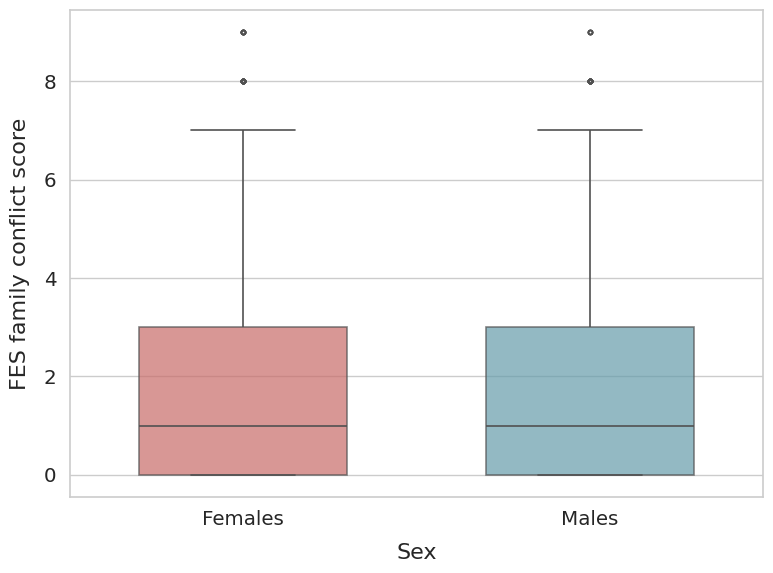

In [261]:
# Style setup
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
#sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)

plt.rcParams["axes.linewidth"] = 1.2  # thicker axes for cleaner appearance
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create figure
plt.figure(figsize=(8, 6))

# Boxplot
ax = sns.boxplot(
    data=abcd_demo_all_clean_omit_nan,
    x="sex",
    y="fam_conflict_y",
    hue="sex",
    palette={"F": "#d85c59", "M": "#5aa3b5"},  # palette={'M': 'cadetblue', 'F': 'lightcoral'},
    dodge=False,
    width=0.6,
    linewidth=1.2,
    fliersize=3,
    boxprops={"alpha": 0.7},
)

#sns.despine(trim=True)

# Axis labels and title
ax.set_xlabel("Sex", fontsize=16, labelpad=10)
ax.set_ylabel("FES family conflict score", fontsize=16, labelpad=10)
ax.set_xticklabels(["Females", "Males"])
#ax.set_title("Pubertal Scores by Sex", pad=15, weight="bold")

# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(resdir_fig+"boxplot_fes_by_sex.svg", format="svg", bbox_inches="tight", dpi=300)

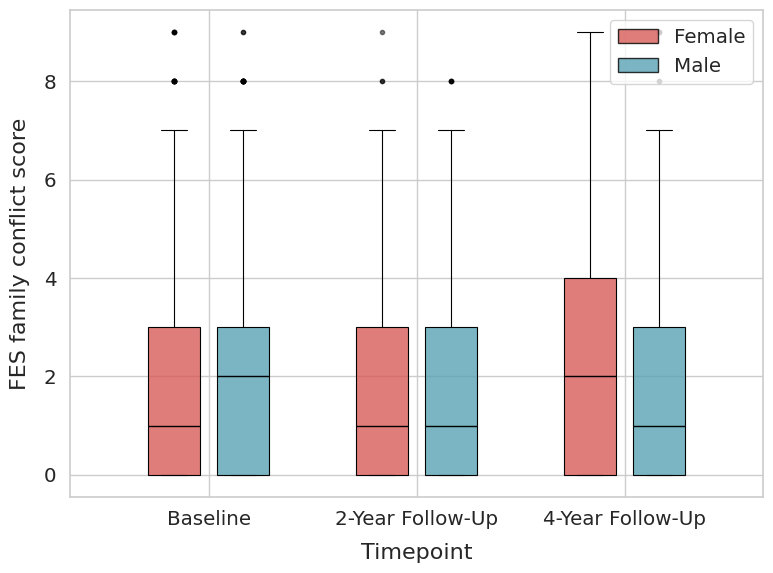

In [262]:
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

alpha_map = {
    "Baseline": 0.8,  # 0.8
    "2-Year Follow-Up": 0.8,  # 0.8
    "4-Year Follow-Up": 0.8  # 0.8
}

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

data = [
    abcd_demo_baseline_clean_omit_nan,
    abcd_demo_fu2y_clean_omit_nan,
    abcd_demo_fu4y_clean_omit_nan
]

# --- Style setup (consistent with your manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axes ---
fig, ax = plt.subplots(figsize=(8, 6))

# --- Function to draw SEX-SPLIT boxplots with TIMEPOINT alpha ---
def draw_boxplots(ax, data):

    box_width = 0.25
    offsets = [-box_width / 1.5, box_width / 1.5]  # F left, M right

    for tp_idx, tp in enumerate(timepoints):

        df_tp = data[tp_idx]
        alpha = alpha_map[tp]

        for sex_idx, sex in enumerate(["F", "M"]):

            df_sex = df_tp[df_tp["sex"] == sex]["fam_conflict_y"].dropna()

            color = sex_palette[sex]
            rgba = mcolors.to_rgba(color, alpha=alpha)

            position = tp_idx + offsets[sex_idx]

            bp = ax.boxplot(
                df_sex,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                boxprops=dict(facecolor=rgba, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8),
                flierprops=dict(
                    marker='o',
                    markersize=3,
                    alpha=0.5,
                    markerfacecolor='black',
                    markeredgecolor='black'
                )
            )


# --- Draw boxplots ---
draw_boxplots(ax, data)

# --- Axis labels ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("FES family conflict score", fontsize=16, labelpad=10)

# --- Legend (Sex only, alpha encoded visually) ---
legend_elements = [
    Patch(facecolor=sex_palette["F"], alpha=0.8, edgecolor="black", label="Female"),
    Patch(facecolor=sex_palette["M"], alpha=0.8, edgecolor="black", label="Male"),
]
ax.legend(handles=legend_elements, loc="upper right", frameon=True)




# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(
    resdir_fig + "boxplot_fes_by_sex_by_timepoint.svg",
    format="svg",
    bbox_inches="tight",
    dpi=300
)


#### SES (parental education)

In [278]:
edu_parent_labels = {
    0: "Never attended / Kindergarten only",
    1: "1st grade",
    2: "2nd grade",
    3: "3rd grade",
    4: "4th grade",
    5: "5th grade",
    6: "6th grade",
    7: "7th grade",
    8: "8th grade",
    9: "9th grade",
    10: "10th grade",
    11: "11th grade",
    12: "12th grade",
    13: "High school graduate",
    14: "General Educational Development",  # General Educational Development
    15: "Some college",
    16: "Occupational associate degree",
    17: "Academic associate degree",
    18: "Bachelor’s degree",
    19: "Master’s degree",
    20: "Professional school degree",
    21: "Doctoral degree"
}

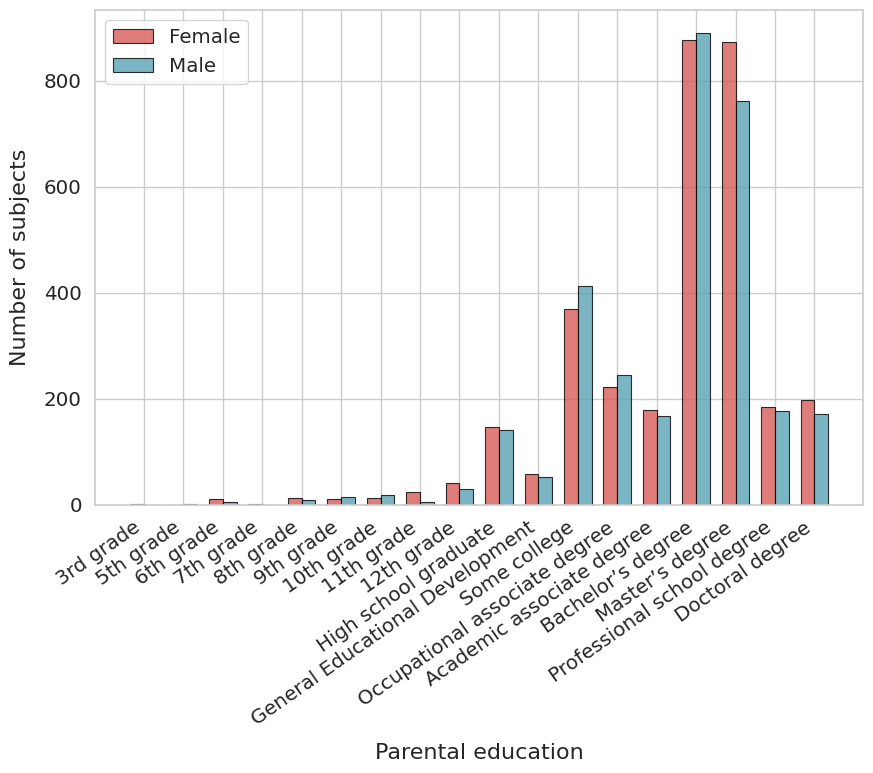

In [282]:
# --- Style setup (match manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

df = abcd_demo_all_clean.copy()

# --- Define full category order ---
edu_levels = sorted(df["edu_parent"].dropna().unique())
sex_levels = ["F", "M"]

# --- Count subjects, explicitly filling missing combinations with 0 ---
counts = (
    df
    .groupby(["edu_parent", "sex"])
    .size()
    .reindex(
        pd.MultiIndex.from_product(
            [edu_levels, sex_levels],
            names=["edu_parent", "sex"]
        ),
        fill_value=0
    )
    .reset_index(name="n")
)

# Map numeric codes to labels (only for those present)
counts["edu_parent_label"] = counts["edu_parent"].map(edu_parent_labels)


# --- Plot ---
x = np.arange(len(edu_levels))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(9, 8))

for i, sex in enumerate(sex_levels):
    sex_counts = counts[counts["sex"] == sex]

    ax.bar(
        x + (i - 0.5) * bar_width,
        sex_counts["n"].values,
        width=bar_width,
        color=sex_palette[sex],
        alpha=0.8,
        edgecolor="black",
        linewidth=0.8,
        label="Female" if sex == "F" else "Male"
    )

# --- Axis labels ---
ax.set_xticks(x)

# Use mapped labels, only for observed categories
xtick_labels = [
    edu_parent_labels.get(code, str(code)) for code in edu_levels
]
ax.set_xticklabels(xtick_labels, rotation=35, ha="right")

ax.set_xlabel("Parental education", fontsize=16, labelpad=10)
ax.set_ylabel("Number of subjects", fontsize=16, labelpad=10)

# --- Legend ---
ax.legend(frameon=True, loc="upper left")

plt.tight_layout()
plt.savefig(resdir_fig + "hist_edu_parent_by_sex.svg", format="svg", bbox_inches="tight", dpi=300)
# plt.show()


#### BMI z-score (relative to age and sex - with reference to the CDC 2000 Growth Charts)

In [63]:
print(f"Females: Mean: {np.mean(abcd_demo_all_clean.BMIz[abcd_demo_all_clean.sex == 'F']):.2f}, SD: {np.std(abcd_demo_all_clean.BMIz[abcd_demo_all_clean.sex == 'F']):.2f}") 
print(f"Males: Mean: {np.mean(abcd_demo_all_clean.BMIz[abcd_demo_all_clean.sex == 'M']):.2f}, SD: {np.std(abcd_demo_all_clean.BMIz[abcd_demo_all_clean.sex == 'M']):.2f}")

Females: Mean: 0.26, SD: 1.12
Males: Mean: 0.23, SD: 1.15


In [64]:
print(stats.levene(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].BMIz, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].BMIz, center='median', nan_policy='omit'))  # Levene's test of homogeneity of variance, OK to use if centering on median instead of mean
print(stats.fligner(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].BMIz, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].BMIz, nan_policy='omit'))  # Fligner-Killeen Test, non-parametric and suitable for ordinal data

LeveneResult(statistic=2.3475911706051393, pvalue=0.12552691233014576)
FlignerResult(statistic=2.3980552138387985, pvalue=0.12148619653366982)


In [65]:
print(f"{stats.ttest_ind(abcd_demo_all_clean.BMIz[abcd_demo_all_clean.sex == 'F'], abcd_demo_all_clean.BMIz[abcd_demo_all_clean.sex == 'M'], nan_policy='omit')}")

TtestResult(statistic=1.0765021818933722, pvalue=0.2817438942614545, df=6308.0)


In [66]:
print(stats.mannwhitneyu(abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'M'].BMIz, abcd_demo_all_clean[abcd_demo_all_clean['sex'] == 'F'].BMIz, nan_policy='omit'))

MannwhitneyuResult(statistic=4907551.0, pvalue=0.34920391298448783)


Checking NaNs

In [67]:
abcd_demo_all_clean["BMIz"].isna().sum()

13

Plots

In [68]:
# Need to remove nans for plotting  fpr family conflict
abcd_demo_all_clean_omit_nan = abcd_demo_all_clean.dropna(subset=["BMIz"])
abcd_demo_baseline_clean_omit_nan = abcd_demo_baseline_clean.dropna(subset=["BMIz"])
abcd_demo_fu2y_clean_omit_nan = abcd_demo_fu2y_clean.dropna(subset=["BMIz"])
abcd_demo_fu4y_clean_omit_nan = abcd_demo_fu4y_clean.dropna(subset=["BMIz"])

/tmp/ipykernel_19527/284022671.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Females", "Males"])


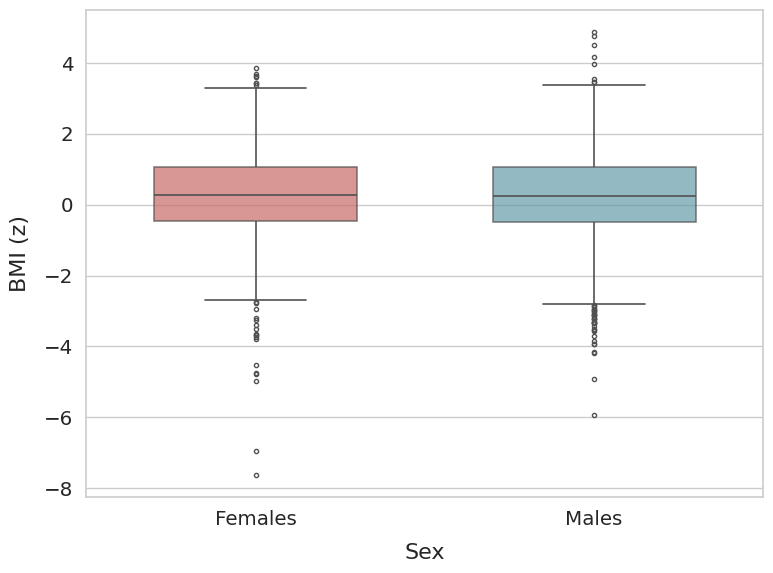

In [69]:
# Style setup
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
#sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)

plt.rcParams["axes.linewidth"] = 1.2  # thicker axes for cleaner appearance
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create figure
plt.figure(figsize=(8, 6))

# Boxplot
ax = sns.boxplot(
    data=abcd_demo_all_clean_omit_nan,
    x="sex",
    y="BMIz",
    hue="sex",
    palette={"F": "#d85c59", "M": "#5aa3b5"},  # palette={'M': 'cadetblue', 'F': 'lightcoral'},
    dodge=False,
    width=0.6,
    linewidth=1.2,
    fliersize=3,
    boxprops={"alpha": 0.7},
)

#sns.despine(trim=True)

# Axis labels and title
ax.set_xlabel("Sex", fontsize=16, labelpad=10)
ax.set_ylabel("BMI (z)", fontsize=16, labelpad=10)
ax.set_xticklabels(["Females", "Males"])
#ax.set_title("Pubertal Scores by Sex", pad=15, weight="bold")

# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(resdir_fig+"boxplot_BMIz_by_sex.svg", format="svg", bbox_inches="tight", dpi=300)

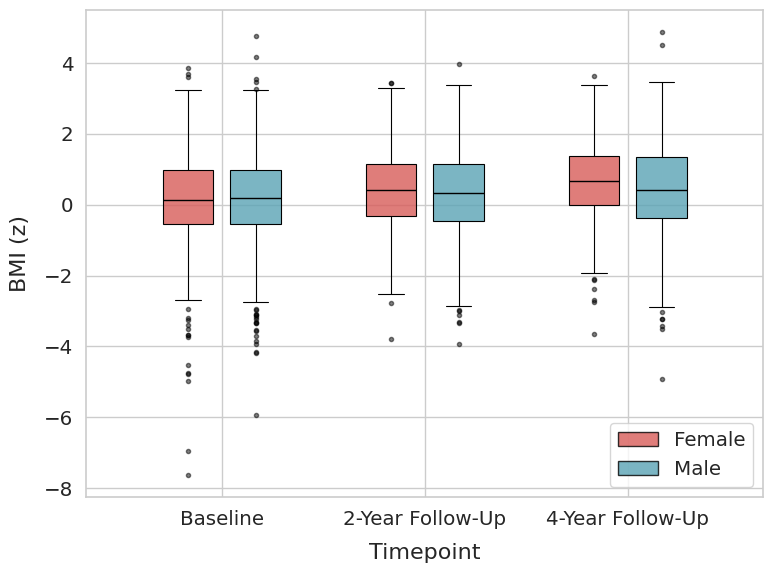

In [71]:
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

alpha_map = {
    "Baseline": 0.8,  # 0.8
    "2-Year Follow-Up": 0.8,  # 0.8
    "4-Year Follow-Up": 0.8  # 0.8
}

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

data = [
    abcd_demo_baseline_clean_omit_nan,
    abcd_demo_fu2y_clean_omit_nan,
    abcd_demo_fu4y_clean_omit_nan
]

# --- Style setup (consistent with your manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axes ---
fig, ax = plt.subplots(figsize=(8, 6))

# --- Function to draw SEX-SPLIT boxplots with TIMEPOINT alpha ---
def draw_boxplots(ax, data):

    box_width = 0.25
    offsets = [-box_width / 1.5, box_width / 1.5]  # F left, M right

    for tp_idx, tp in enumerate(timepoints):

        df_tp = data[tp_idx]
        alpha = alpha_map[tp]

        for sex_idx, sex in enumerate(["F", "M"]):

            df_sex = df_tp[df_tp["sex"] == sex]["BMIz"].dropna()

            color = sex_palette[sex]
            rgba = mcolors.to_rgba(color, alpha=alpha)

            position = tp_idx + offsets[sex_idx]

            bp = ax.boxplot(
                df_sex,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                boxprops=dict(facecolor=rgba, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8),
                flierprops=dict(
                    marker='o',
                    markersize=3,
                    alpha=0.5,
                    markerfacecolor='black',
                    markeredgecolor='black'
                )
            )


# --- Draw boxplots ---
draw_boxplots(ax, data)

# --- Axis labels ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("BMI (z)", fontsize=16, labelpad=10)

# --- Legend (Sex only, alpha encoded visually) ---
legend_elements = [
    Patch(facecolor=sex_palette["F"], alpha=0.8, edgecolor="black", label="Female"),
    Patch(facecolor=sex_palette["M"], alpha=0.8, edgecolor="black", label="Male"),
]
ax.legend(handles=legend_elements, loc="lower right", frameon=True)




# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(
    resdir_fig + "boxplot_BMIz_by_sex_by_timepoint.svg",
    format="svg",
    bbox_inches="tight",
    dpi=300
)


#
#
#
#
# Compute gradients - Overall - BASELINE

## Mean gradients

In [90]:
mean_fc_matrix = np.sum(fc_matrices_baseline, axis=0)/len(fc_matrices_baseline)

In [91]:
mean_fc_matrix.shape

(400, 400)

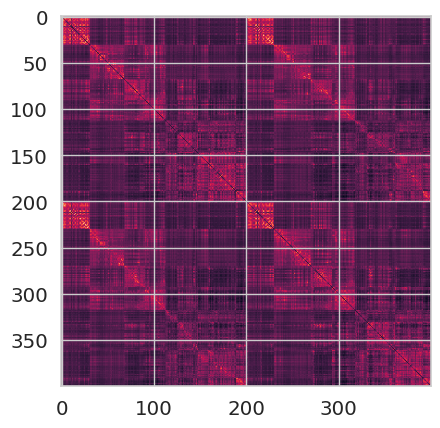

(400, 400)


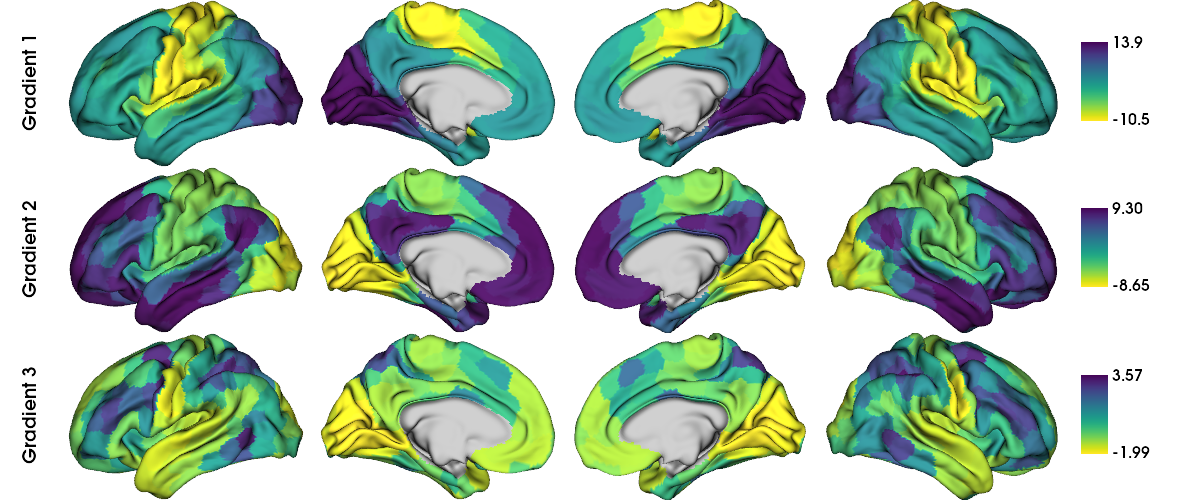

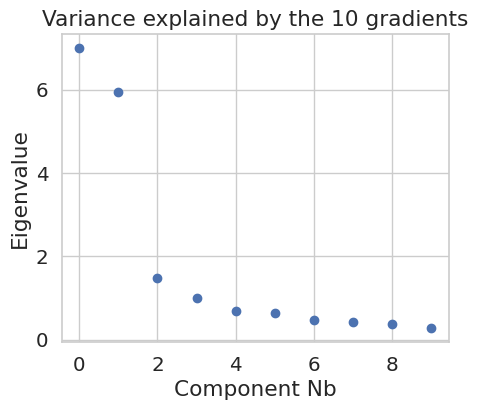

Total amount of variance explained by the 10 gradients (uncorrected sum lambdas): 18.27

G1: 38.26%
G2: 32.46%
G3: 8.05


In [92]:
# don't save these screenshots! (saves G1 and I actually want flipped -> next cells)
mean_fc_grad = compute_mean_gradients(mean_fc_matrix, display_output = True, data_reduction_algorithm = 'dm', kernel='cosine', save_screenshot = False, output_dir = resdir_fig, sample_modality = 'fc')

### RainCloudPlot
Using RainCloud plots https://github.com/RainCloudPlots/RainCloudPlots#python-environment

## Subject-level gradients (NOT ALIGNED)

In [135]:
# compute aligned gradients
compute_indvidual_gradients = compute_indvidual_gradients_NOT_aligned(conn_matrices = fc_matrices_baseline, ref_SA_axis = Margulies_gradients_schaefer400[0], data_reduction_algorithm = 'dm', kernel = 'cosine')

# store output of the gradient computation
array_SA_axis_baseline = compute_indvidual_gradients['array_SA_axis']
array_grad_other1_baseline = compute_indvidual_gradients['array_grad_other1']
array_grad_other2_baseline = compute_indvidual_gradients['array_grad_other2']
list_SA_axis_grad_num_baseline = compute_indvidual_gradients['list_SA_axis_grad_num']
list_SA_axis_corr_to_ref_baseline = compute_indvidual_gradients['list_SA_axis_corr_to_ref']
scaled_var_exp_SA_axis_baseline = compute_indvidual_gradients['scaled_var_exp_SA_axis']
scaled_var_exp_other1_baseline = compute_indvidual_gradients['scaled_var_exp_other1']
scaled_var_exp_other2_baseline = compute_indvidual_gradients['scaled_var_exp_other2']
diff_scaled_var_exp_SA_axis_other1_baseline = compute_indvidual_gradients['diff_scaled_var_exp_SA_axis_other1']


In [137]:
array_SA_axis_baseline.shape

(4064, 400)

In [165]:
Counter(list_SA_axis_grad_num_baseline)

Counter({1: 2115, 2: 1878, 3: 57, 4: 8, 5: 6})

/tmp/ipykernel_76894/1113933288.py:22: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, 5000)


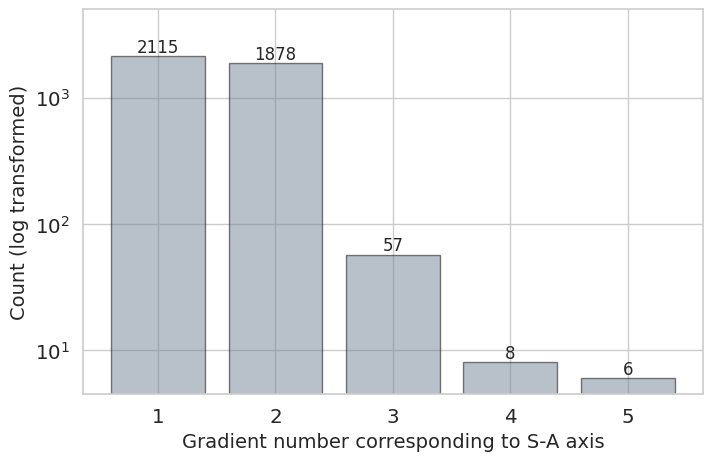

In [139]:
counts = Counter(list_SA_axis_grad_num_baseline)

# Sort by key to keep the x-axis in order
keys = sorted(counts.keys())
values = [counts[k] for k in keys]

# Style setup (match your other figures)
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create the bar plot
plt.figure(figsize=(8, 5))

bars = plt.bar(keys, values, color='xkcd:steel', alpha=0.5, edgecolor='black')

plt.xlabel('Gradient number corresponding to S-A axis', fontsize=14)
plt.ylabel('Count (log transformed)', fontsize=14)
#plt.title('Counts of Axis Gradient Numbers at Baseline', fontsize=16)
plt.xticks(keys)
plt.yscale('log')  # log scale
plt.ylim(0, 5000)

# Annotate counts on top of the bars
for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,  # x position: center of the bar
        value,                               # y position: top of the bar
        str(value),                          # text to display
        ha='center', va='bottom', fontsize=12
    )

plt.show()


In [140]:
# Compute the loading range for the S-A axis at individual level
SA_axis_baseline_individual_range = np.max(array_SA_axis_baseline, axis=1) - np.min(array_SA_axis_baseline, axis=1) 

In [172]:
print(f"Min correlation: r = {round(np.min(list_SA_axis_corr_to_ref_baseline),2)}")
print(f"Max correlation: r = {round(np.max(list_SA_axis_corr_to_ref_baseline),2)}")
print(f"Mean correlation: r = {round(np.mean(list_SA_axis_corr_to_ref_baseline),2)}")
print(f"Median correlation: r = {round(np.median(list_SA_axis_corr_to_ref_baseline),2)}")
print(f"Mean individual range: r = {round(np.mean(SA_axis_baseline_individual_range),2)}")

Min correlation: r = 0.37
Max correlation: r = 0.94
Mean correlation: r = 0.75
Median correlation: r = 0.75
STD correlation: r = 0.0919095929
Mean individual range: r = 14.57


In [175]:
data = list_SA_axis_corr_to_ref_baseline
# Coefficient of variation
print("CV = std / mean. Scale-free measure of relative dispersion")
print(np.std(data, ddof=1) / np.mean(data))

# Interquartile range
print("\nIQR = Q3 - Q1. Middle 50% spread, robust to outliers")
print(np.percentile(data, 75) - np.percentile(data, 25))

# Median absolute deviation
print("\nMAD = median(|xi - median(x)|). Robust, outlier-resistant spread")
print(np.median(np.abs(data - np.median(data))))

# Normalized range
print("\nNR = (max - min) / mean. Simple but sensitive to outliers")
print((np.max(data) - np.min(data)) / np.mean(data))

# Gini coefficient
print("\nGini coefficient. 0 = perfect equality, 1 = maximal inequality")
sorted_data = np.sort(data)
n = len(sorted_data)
index = np.arange(1, n + 1)
print((2 * np.sum(index * sorted_data) / (n * np.sum(sorted_data))) - (n + 1) / n)

CV = std / mean. Scale-free measure of relative dispersion
0.12328971235682878

IQR = Q3 - Q1. Middle 50% spread, robust to outliers
0.1337564922280765

MAD = median(|xi - median(x)|). Robust, outlier-resistant spread
0.06618247614047601

NR = (max - min) / mean. Simple but sensitive to outliers
0.7677002970448354

Gini coefficient. 0 = perfect equality, 1 = maximal inequality
0.07003103466053728


In [142]:
print(f"Min scaled variance explained by S-A axis: {round(np.min(scaled_var_exp_SA_axis_baseline),2)}")
print(f"Max scaled variance explained by S-A axis: {round(np.max(scaled_var_exp_SA_axis_baseline),2)}")
print("")
print(f"Min difference variance explained by S-A axis and other gradient 1: {round(np.min(diff_scaled_var_exp_SA_axis_other1_baseline),2)}")
print(f"Max difference variance explained by S-A axis and other gradient 1: {round(np.max(diff_scaled_var_exp_SA_axis_other1_baseline),2)}")

Min scaled variance explained by S-A axis: 0.43
Max scaled variance explained by S-A axis: 57.58

Min difference variance explained by S-A axis and other gradient 1: -95.31
Max difference variance explained by S-A axis and other gradient 1: 50.8


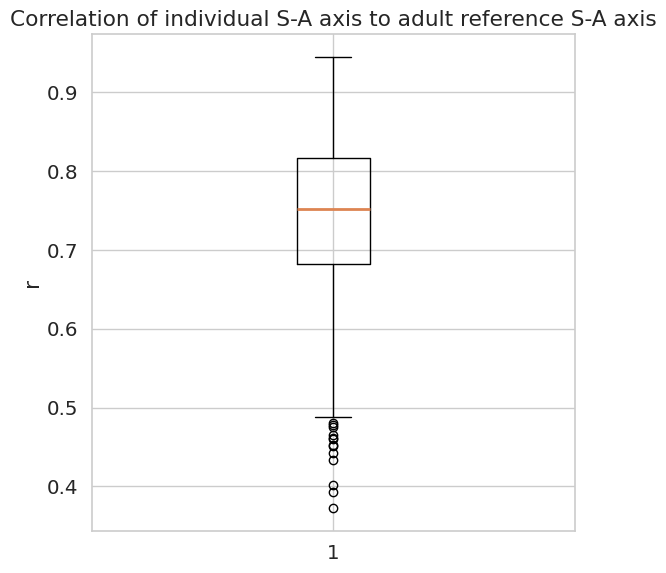

In [144]:
plt.figure(figsize=(6, 6))
plt.boxplot(list_SA_axis_corr_to_ref_baseline)
plt.ylabel('r')
plt.title('Correlation of individual S-A axis to adult reference S-A axis')
plt.tight_layout()
plt.show()

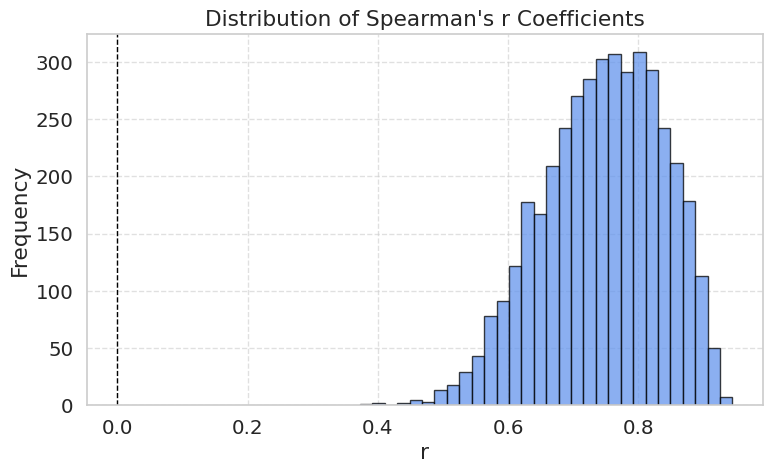

In [145]:
# Plot histogram
plt.figure(figsize=(8, 5))
plt.hist(list_SA_axis_corr_to_ref_baseline, bins=30, color='cornflowerblue', edgecolor='black', alpha=0.75)
plt.title("Distribution of Spearman's r Coefficients")
plt.xlabel("r")
plt.ylabel("Frequency")
plt.axvline(0, color='black', linestyle='--', linewidth=1)  # reference line at r = 0
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

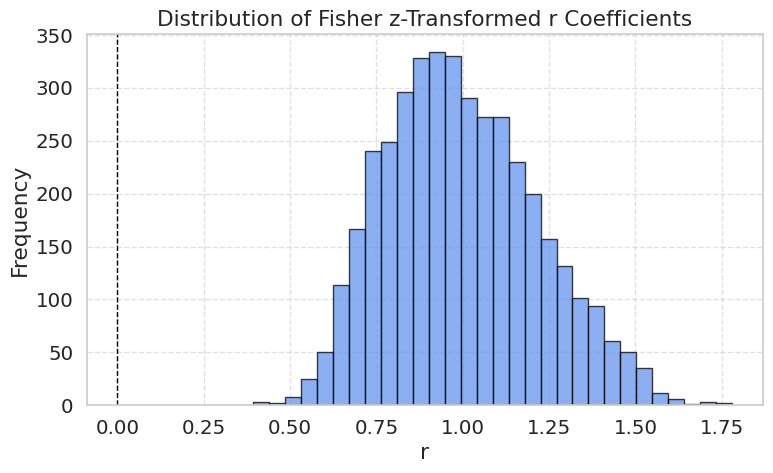

In [146]:
# Apply Fisher r-to-z transformation <- ALTHOUGH FOR ANALYSES NEED TO APPLY TRANSFORMATION ON CONCATENATED SAMPLE AT 3 TIMEPOINTS! (DOING THIS IN R)
list_SA_axis_corr_to_ref_baseline_z = 0.5 * np.log((1 + np.array(list_SA_axis_corr_to_ref_baseline)) / (1 - np.array(list_SA_axis_corr_to_ref_baseline)))

# Plot histogram of transformed z values
# Plot histogram
plt.figure(figsize=(8, 5))
plt.hist(list_SA_axis_corr_to_ref_baseline_z, bins=30, color='cornflowerblue', edgecolor='black', alpha=0.75)
plt.title("Distribution of Fisher z-Transformed r Coefficients")
plt.xlabel("r")
plt.ylabel("Frequency")
plt.axvline(0, color='black', linestyle='--', linewidth=1)  # reference line at r = 0
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [147]:
# export S-A axis individual gradients as matfile
mdict = {'array_SA_axis_baseline': array_SA_axis_baseline, 'sub_ID_baseline': sub_ID_baseline, 
         'list_SA_axis_grad_num_baseline': list_SA_axis_grad_num_baseline, 
         'list_SA_axis_corr_to_ref_baseline': list_SA_axis_corr_to_ref_baseline, 'list_SA_axis_corr_to_ref_baseline_z': list_SA_axis_corr_to_ref_baseline_z,
         'SA_axis_baseline_individual_range': SA_axis_baseline_individual_range
        }

scipy.io.savemat(datadir_local_longitudinal_sample+'array_SA_axis_NOT_aligned_baseline.mat', mdict)

#
#
#
#
# Compute gradients - Overall - 2yfu

## Mean gradients

In [99]:
mean_fc_matrix_fu2y = np.sum(fc_matrices_fu2y, axis=0)/len(fc_matrices_fu2y)

In [100]:
mean_fc_matrix_fu2y.shape

(400, 400)

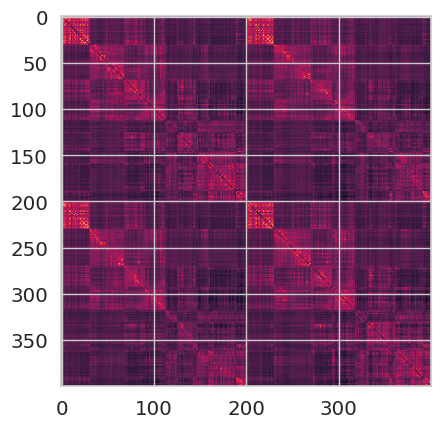

(400, 400)


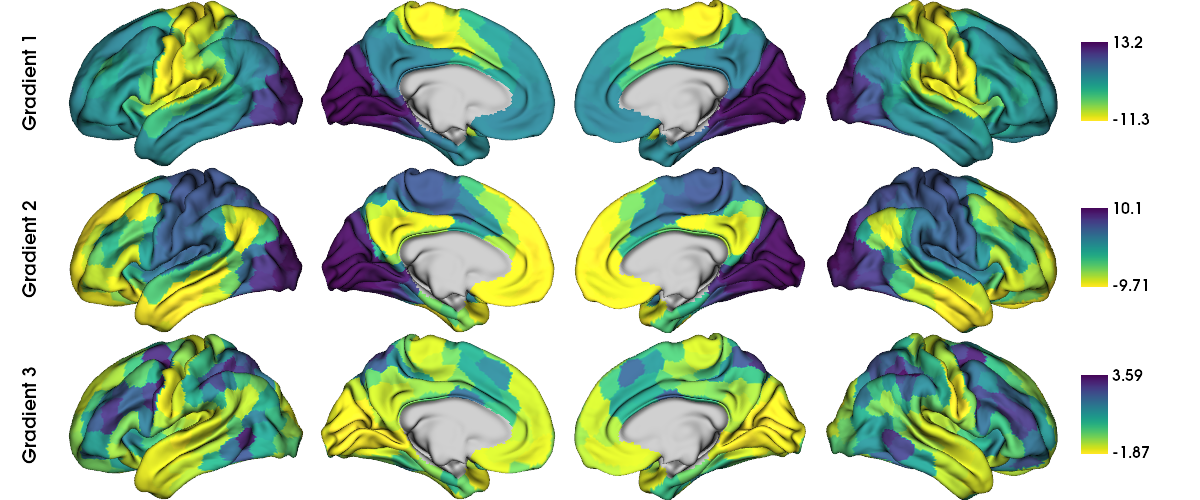

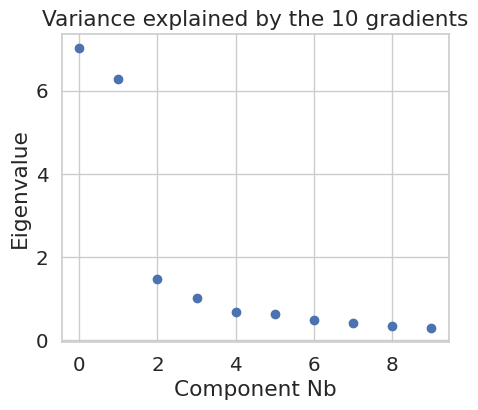

Total amount of variance explained by the 10 gradients (uncorrected sum lambdas): 18.70

G1: 37.57%
G2: 33.55%
G3: 7.95


In [101]:
# don't save these screenshots! (saves G1 and I actually want flipped -> next cells)
mean_fc_grad_fu2y = compute_mean_gradients(mean_fc_matrix_fu2y, display_output = True, data_reduction_algorithm = 'dm', kernel = 'cosine', save_screenshot = False, output_dir = resdir_fig, sample_modality = 'fc')

In [168]:
# I am creating a new variable with gradients that are flipped because I want G2 to go from sensory (-) to association (+) and I want to align individual level gradients to this
mean_fc_grad_flipped_fu2y = - mean_fc_grad_fu2y.gradients_

### RainCloudPlot
Using RainCloud plots https://github.com/RainCloudPlots/RainCloudPlots#python-environment

## Subject-level gradients (NOT ALIGNED)

In [143]:
# compute aligned gradients
compute_indvidual_gradients_fu2y = compute_indvidual_gradients_NOT_aligned(conn_matrices = fc_matrices_fu2y, ref_SA_axis = Margulies_gradients_schaefer400[0], data_reduction_algorithm = 'dm', kernel = 'cosine')

# store output of the gradient computation
array_SA_axis_fu2y = compute_indvidual_gradients_fu2y['array_SA_axis']
array_grad_other1_fu2y = compute_indvidual_gradients_fu2y['array_grad_other1']
array_grad_other2_fu2y = compute_indvidual_gradients_fu2y['array_grad_other2']
list_SA_axis_grad_num_fu2y = compute_indvidual_gradients_fu2y['list_SA_axis_grad_num']
list_SA_axis_corr_to_ref_fu2y = compute_indvidual_gradients_fu2y['list_SA_axis_corr_to_ref']
scaled_var_exp_SA_axis_fu2y = compute_indvidual_gradients_fu2y['scaled_var_exp_SA_axis']
scaled_var_exp_other1_fu2y = compute_indvidual_gradients_fu2y['scaled_var_exp_other1']
scaled_var_exp_other2_fu2y = compute_indvidual_gradients_fu2y['scaled_var_exp_other2']
diff_scaled_var_exp_SA_axis_other1_fu2y = compute_indvidual_gradients_fu2y['diff_scaled_var_exp_SA_axis_other1']


In [144]:
array_SA_axis_fu2y.shape

(1296, 400)

In [145]:
Counter(list_SA_axis_grad_num_fu2y)

Counter({1: 757, 2: 515, 3: 22, 4: 2})

/tmp/ipykernel_76894/797398177.py:22: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, 5000)


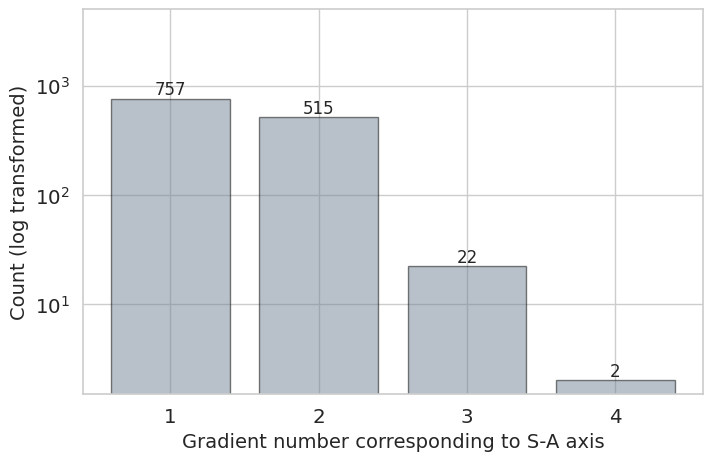

In [146]:
counts = Counter(list_SA_axis_grad_num_fu2y)

# Sort by key to keep the x-axis in order
keys = sorted(counts.keys())
values = [counts[k] for k in keys]

# Style setup (match your other figures)
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create the bar plot
plt.figure(figsize=(8, 5))

bars = plt.bar(keys, values, color='xkcd:steel', alpha=0.5, edgecolor='black')

plt.xlabel('Gradient number corresponding to S-A axis', fontsize=14)
plt.ylabel('Count (log transformed)', fontsize=14)
#plt.title('Counts of Axis Gradient Numbers at Baseline', fontsize=16)
plt.xticks(keys)
plt.yscale('log')  # log scale
plt.ylim(0, 5000)

# Annotate counts on top of the bars
for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,  # x position: center of the bar
        value,                               # y position: top of the bar
        str(value),                          # text to display
        ha='center', va='bottom', fontsize=12
    )

plt.show()


In [147]:
# Compute the loading range for the S-A axis at individual level
SA_axis_fu2y_individual_range = np.max(array_SA_axis_fu2y, axis=1) - np.min(array_SA_axis_fu2y, axis=1)

In [171]:
print(f"Min correlation: r = {round(np.min(list_SA_axis_corr_to_ref_fu2y),2)}")
print(f"Max correlation: r = {round(np.max(list_SA_axis_corr_to_ref_fu2y),2)}")
print(f"Mean correlation: r = {round(np.mean(list_SA_axis_corr_to_ref_fu2y),2)}")
print(f"Median correlation: r = {round(np.median(list_SA_axis_corr_to_ref_fu2y),2)}")
print(f"STD correlation: r = {round(np.std(list_SA_axis_corr_to_ref_fu2y),10)}")
print(f"Mean individual range: r = {round(np.mean(SA_axis_fu2y_individual_range),2)}")

Min correlation: r = 0.44
Max correlation: r = 0.95
Mean correlation: r = 0.76
Median correlation: r = 0.77
STD correlation: r = 0.0919727347
Mean individual range: r = 15.25


In [176]:
data = list_SA_axis_corr_to_ref_fu2y
# Coefficient of variation
print("CV = std / mean. Scale-free measure of relative dispersion")
print(np.std(data, ddof=1) / np.mean(data))

# Interquartile range
print("\nIQR = Q3 - Q1. Middle 50% spread, robust to outliers")
print(np.percentile(data, 75) - np.percentile(data, 25))

# Median absolute deviation
print("\nMAD = median(|xi - median(x)|). Robust, outlier-resistant spread")
print(np.median(np.abs(data - np.median(data))))

# Normalized range
print("\nNR = (max - min) / mean. Simple but sensitive to outliers")
print((np.max(data) - np.min(data)) / np.mean(data))

# Gini coefficient
print("\nGini coefficient. 0 = perfect equality, 1 = maximal inequality")
sorted_data = np.sort(data)
n = len(sorted_data)
index = np.arange(1, n + 1)
print((2 * np.sum(index * sorted_data) / (n * np.sum(sorted_data))) - (n + 1) / n)

CV = std / mean. Scale-free measure of relative dispersion
0.12052754958877239

IQR = Q3 - Q1. Middle 50% spread, robust to outliers
0.1340488534303339

MAD = median(|xi - median(x)|). Robust, outlier-resistant spread
0.0666334164588529

NR = (max - min) / mean. Simple but sensitive to outliers
0.6689863968969999

Gini coefficient. 0 = perfect equality, 1 = maximal inequality
0.06834410580386119


In [149]:
print(f"Min scaled variance explained by S-A axis: {round(np.min(scaled_var_exp_SA_axis_fu2y),2)}")
print(f"Max scaled variance explained by S-A axis: {round(np.max(scaled_var_exp_SA_axis_fu2y),2)}")
print("")
print(f"Min difference variance explained by S-A axis and other gradient 1: {round(np.min(diff_scaled_var_exp_SA_axis_other1_fu2y),2)}")
print(f"Max difference variance explained by S-A axis and other gradient 1: {round(np.max(diff_scaled_var_exp_SA_axis_other1_fu2y),2)}")

Min scaled variance explained by S-A axis: 0.11
Max scaled variance explained by S-A axis: 58.36

Min difference variance explained by S-A axis and other gradient 1: -99.19
Max difference variance explained by S-A axis and other gradient 1: 55.68


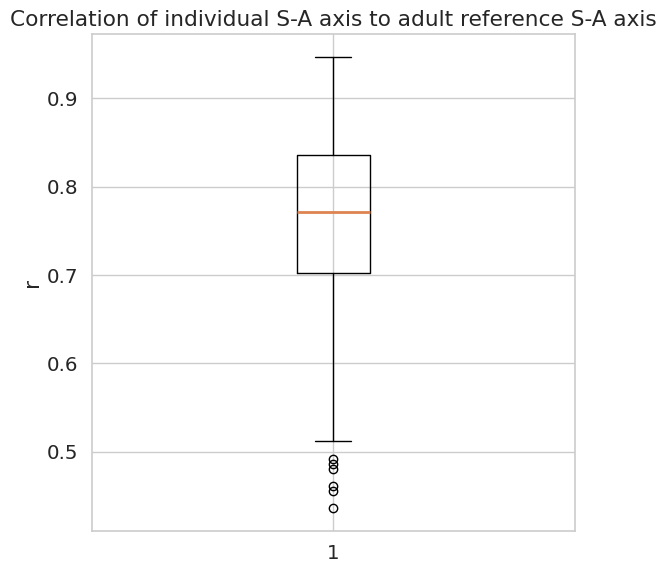

In [175]:
plt.figure(figsize=(6, 6))
plt.boxplot(list_SA_axis_corr_to_ref_fu2y)
plt.ylabel('r')
plt.title('Correlation of individual S-A axis to adult reference S-A axis')
plt.tight_layout()
plt.show()

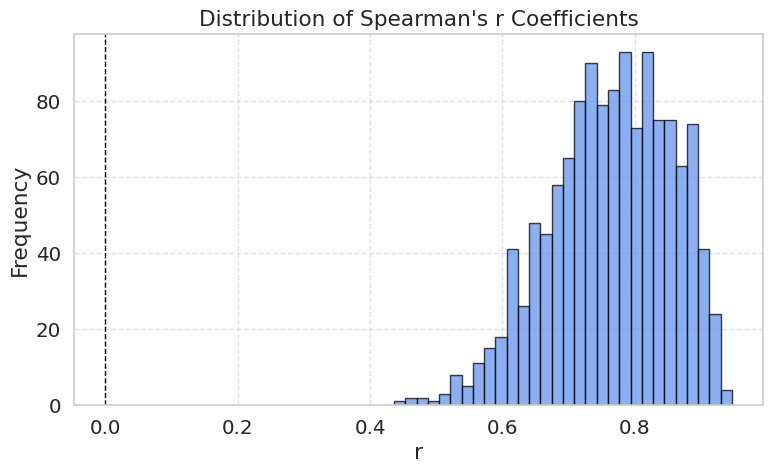

In [176]:
# Plot histogram
plt.figure(figsize=(8, 5))
plt.hist(list_SA_axis_corr_to_ref_fu2y, bins=30, color='cornflowerblue', edgecolor='black', alpha=0.75)
plt.title("Distribution of Spearman's r Coefficients")
plt.xlabel("r")
plt.ylabel("Frequency")
plt.axvline(0, color='black', linestyle='--', linewidth=1)  # reference line at r = 0
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

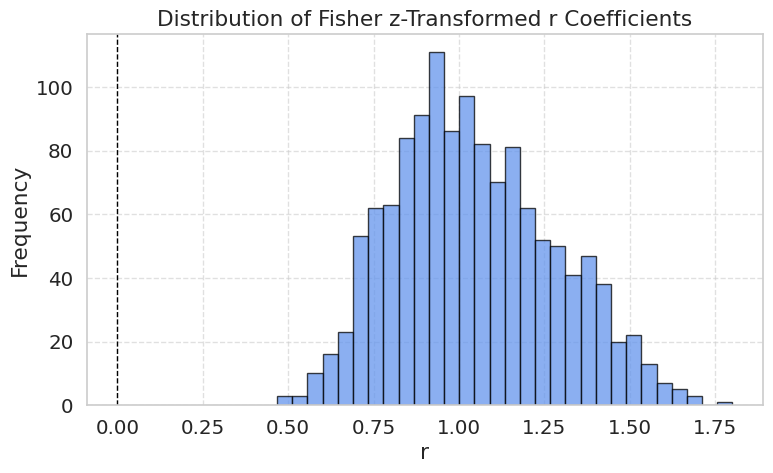

In [177]:
# Apply Fisher r-to-z transformation <- ALTHOUGH FOR ANALYSES NEED TO APPLY TRANSFORMATION ON CONCATENATED SAMPLE AT 3 TIMEPOINTS! (DOING THIS IN R)
list_SA_axis_corr_to_ref_fu2y_z = 0.5 * np.log((1 + np.array(list_SA_axis_corr_to_ref_fu2y)) / (1 - np.array(list_SA_axis_corr_to_ref_fu2y)))

# Plot histogram of transformed z values
# Plot histogram
plt.figure(figsize=(8, 5))
plt.hist(list_SA_axis_corr_to_ref_fu2y_z, bins=30, color='cornflowerblue', edgecolor='black', alpha=0.75)
plt.title("Distribution of Fisher z-Transformed r Coefficients")
plt.xlabel("r")
plt.ylabel("Frequency")
plt.axvline(0, color='black', linestyle='--', linewidth=1)  # reference line at r = 0
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [178]:
# export individual S-A axis 
mdict = {'array_SA_axis_fu2y': array_SA_axis_fu2y, 'sub_ID_fu2y': sub_ID_fu2y, 
         'list_SA_axis_grad_num_fu2y': list_SA_axis_grad_num_fu2y, 
         'list_SA_axis_corr_to_ref_fu2y': list_SA_axis_corr_to_ref_fu2y,  'list_SA_axis_corr_to_ref_fu2y_z': list_SA_axis_corr_to_ref_fu2y_z,
         'SA_axis_fu2y_individual_range': SA_axis_fu2y_individual_range
        }

scipy.io.savemat(datadir_local_longitudinal_sample+'array_SA_axis_NOT_aligned_fu2y.mat', mdict)

#
#
#
#
# Compute gradients - Overall - 4yfu

## Mean gradients

In [102]:
mean_fc_matrix_fu4y = np.sum(fc_matrices_fu4y, axis=0)/len(fc_matrices_fu4y)

In [103]:
mean_fc_matrix_fu4y.shape

(400, 400)

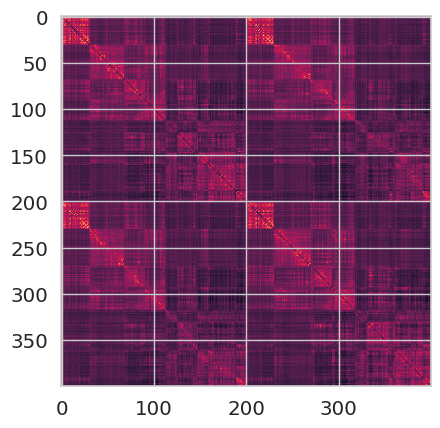

(400, 400)


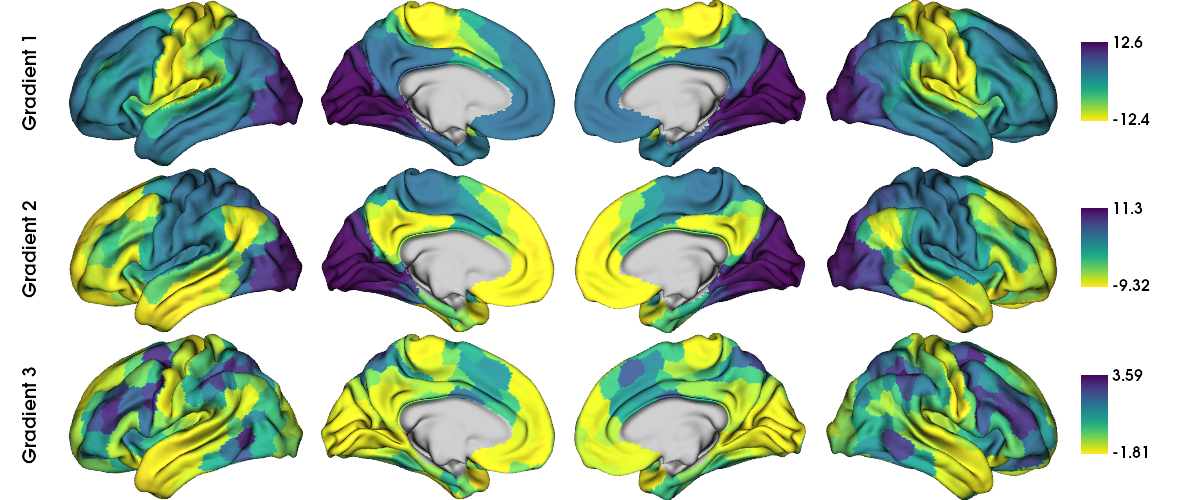

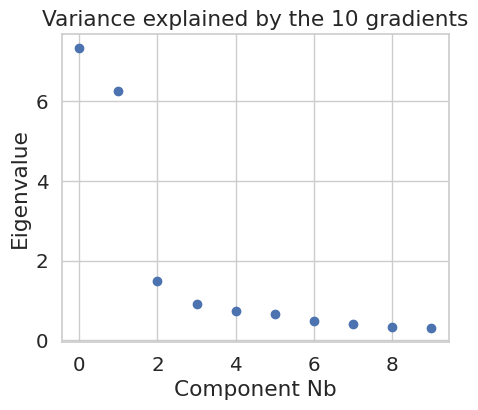

Total amount of variance explained by the 10 gradients (uncorrected sum lambdas): 18.92

G1: 38.78%
G2: 33.04%
G3: 7.84


In [104]:
# don't save these screenshots! (saves G1 and I actually want flipped -> next cells)
mean_fc_grad_fu4y = compute_mean_gradients(mean_fc_matrix_fu4y, display_output = True, data_reduction_algorithm = 'dm', kernel = 'cosine', save_screenshot = False, output_dir = resdir_fig, sample_modality = 'fc')

In [88]:
# I am creating a new variable with gradients that are flipped because I want G2 to go from sensory (-) to association (+) and I want to align individual level gradients to this
mean_fc_grad_flipped_fu4y = - mean_fc_grad_fu4y.gradients_

### RainCloudPlot
Using RainCloud plots https://github.com/RainCloudPlots/RainCloudPlots#python-environment

## Subject-level gradients (NOT ALIGNED)

In [150]:
# compute aligned gradients
compute_indvidual_gradients_fu4y = compute_indvidual_gradients_NOT_aligned(conn_matrices = fc_matrices_fu4y, ref_SA_axis = Margulies_gradients_schaefer400[0], data_reduction_algorithm = 'dm', kernel = 'cosine')

# store output of the gradient computation
array_SA_axis_fu4y = compute_indvidual_gradients_fu4y['array_SA_axis']
array_grad_other1_fu4y = compute_indvidual_gradients_fu4y['array_grad_other1']
array_grad_other2_fu4y = compute_indvidual_gradients_fu4y['array_grad_other2']
list_SA_axis_grad_num_fu4y = compute_indvidual_gradients_fu4y['list_SA_axis_grad_num']
list_SA_axis_corr_to_ref_fu4y = compute_indvidual_gradients_fu4y['list_SA_axis_corr_to_ref']
scaled_var_exp_SA_axis_fu4y = compute_indvidual_gradients_fu4y['scaled_var_exp_SA_axis']
scaled_var_exp_other1_fu4y = compute_indvidual_gradients_fu4y['scaled_var_exp_other1']
scaled_var_exp_other2_fu4y = compute_indvidual_gradients_fu4y['scaled_var_exp_other2']
diff_scaled_var_exp_SA_axis_other1_fu4y = compute_indvidual_gradients_fu4y['diff_scaled_var_exp_SA_axis_other1']


In [151]:
array_SA_axis_fu4y.shape

(963, 400)

In [152]:
Counter(list_SA_axis_grad_num_fu4y)

Counter({1: 638, 2: 317, 3: 8})

/tmp/ipykernel_76894/4178445155.py:22: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, 5000)


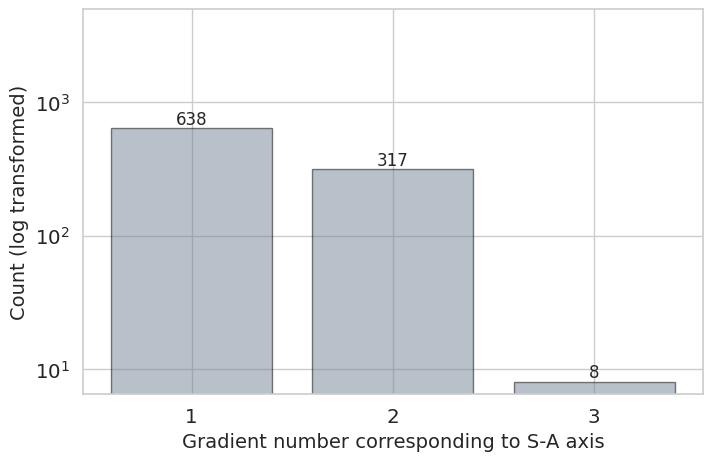

In [153]:
counts = Counter(list_SA_axis_grad_num_fu4y)

# Sort by key to keep the x-axis in order
keys = sorted(counts.keys())
values = [counts[k] for k in keys]

# Style setup (match your other figures)
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create the bar plot
plt.figure(figsize=(8, 5))

bars = plt.bar(keys, values, color='xkcd:steel', alpha=0.5, edgecolor='black')

plt.xlabel('Gradient number corresponding to S-A axis', fontsize=14)
plt.ylabel('Count (log transformed)', fontsize=14)
#plt.title('Counts of Axis Gradient Numbers at Baseline', fontsize=16)
plt.xticks(keys)
plt.yscale('log')  # log scale
plt.ylim(0, 5000)

# Annotate counts on top of the bars
for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,  # x position: center of the bar
        value,                               # y position: top of the bar
        str(value),                          # text to display
        ha='center', va='bottom', fontsize=12
    )

plt.show()


In [154]:
# Compute the loading range for the S-A axis at individual level
SA_axis_fu4y_individual_range = np.max(array_SA_axis_fu4y, axis=1) - np.min(array_SA_axis_fu4y, axis=1)

In [170]:
print(f"Min correlation: r = {round(np.min(list_SA_axis_corr_to_ref_fu4y),2)}")
print(f"Max correlation: r = {round(np.max(list_SA_axis_corr_to_ref_fu4y),2)}")
print(f"Mean correlation: r = {round(np.mean(list_SA_axis_corr_to_ref_fu4y),2)}")
print(f"Median correlation: r = {round(np.median(list_SA_axis_corr_to_ref_fu4y),2)}")
print(f"STD correlation: r = {round(np.std(list_SA_axis_corr_to_ref_fu4y),10)}")
print(f"Mean individual range: r = {round(np.mean(SA_axis_fu4y_individual_range),2)}")

Min correlation: r = 0.51
Max correlation: r = 0.94
Mean correlation: r = 0.78
Median correlation: r = 0.79
STD correlation: r = 0.0894802316
Mean individual range: r = 16.04


In [177]:
data = list_SA_axis_corr_to_ref_fu4y
# Coefficient of variation
print("CV = std / mean. Scale-free measure of relative dispersion")
print(np.std(data, ddof=1) / np.mean(data))

# Interquartile range
print("\nIQR = Q3 - Q1. Middle 50% spread, robust to outliers")
print(np.percentile(data, 75) - np.percentile(data, 25))

# Median absolute deviation
print("\nMAD = median(|xi - median(x)|). Robust, outlier-resistant spread")
print(np.median(np.abs(data - np.median(data))))

# Normalized range
print("\nNR = (max - min) / mean. Simple but sensitive to outliers")
print((np.max(data) - np.min(data)) / np.mean(data))

# Gini coefficient
print("\nGini coefficient. 0 = perfect equality, 1 = maximal inequality")
sorted_data = np.sort(data)
n = len(sorted_data)
index = np.arange(1, n + 1)
print((2 * np.sum(index * sorted_data) / (n * np.sum(sorted_data))) - (n + 1) / n)

CV = std / mean. Scale-free measure of relative dispersion
0.11420919144430525

IQR = Q3 - Q1. Middle 50% spread, robust to outliers
0.13597734985843668

MAD = median(|xi - median(x)|). Robust, outlier-resistant spread
0.06826786417415098

NR = (max - min) / mean. Simple but sensitive to outliers
0.5544942606386245

Gini coefficient. 0 = perfect equality, 1 = maximal inequality
0.06475126900930439


In [156]:
print(f"Min scaled variance explained by S-A axis: {round(np.min(scaled_var_exp_SA_axis_fu4y),2)}")
print(f"Max scaled variance explained by S-A axis: {round(np.max(scaled_var_exp_SA_axis_fu4y),2)}")
print("")
print(f"Min difference variance explained by S-A axis and other gradient 1: {round(np.min(diff_scaled_var_exp_SA_axis_other1_fu4y),2)}")
print(f"Max difference variance explained by S-A axis and other gradient 1: {round(np.max(diff_scaled_var_exp_SA_axis_other1_fu4y),2)}")

Min scaled variance explained by S-A axis: 0.43
Max scaled variance explained by S-A axis: 56.16

Min difference variance explained by S-A axis and other gradient 1: -97.87
Max difference variance explained by S-A axis and other gradient 1: 50.27


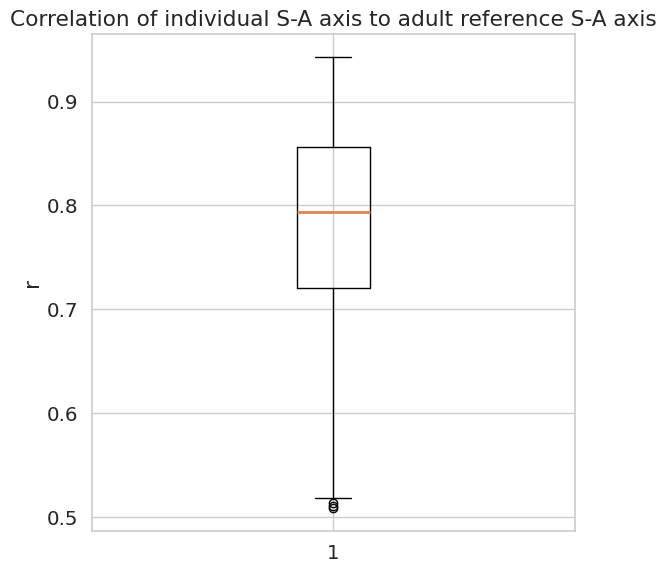

In [159]:
plt.figure(figsize=(6, 6))
plt.boxplot(list_SA_axis_corr_to_ref_fu4y)
plt.ylabel('r')
plt.title('Correlation of individual S-A axis to adult reference S-A axis')
plt.tight_layout()
plt.show()

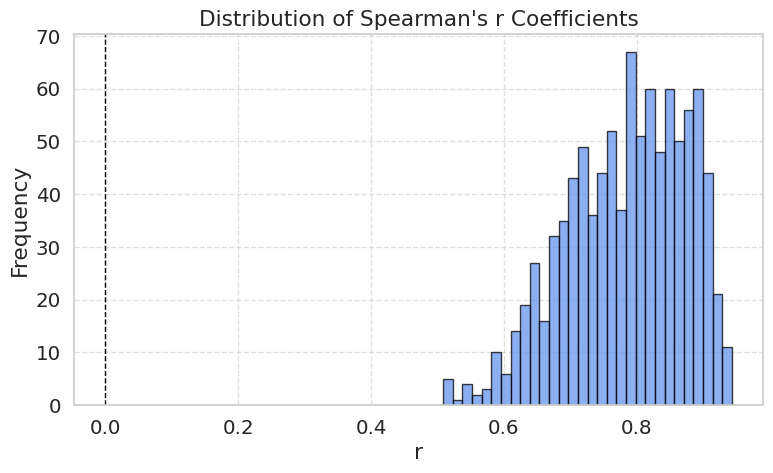

In [160]:
# Plot histogram
plt.figure(figsize=(8, 5))
plt.hist(list_SA_axis_corr_to_ref_fu4y, bins=30, color='cornflowerblue', edgecolor='black', alpha=0.75)
plt.title("Distribution of Spearman's r Coefficients")
plt.xlabel("r")
plt.ylabel("Frequency")
plt.axvline(0, color='black', linestyle='--', linewidth=1)  # reference line at r = 0
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

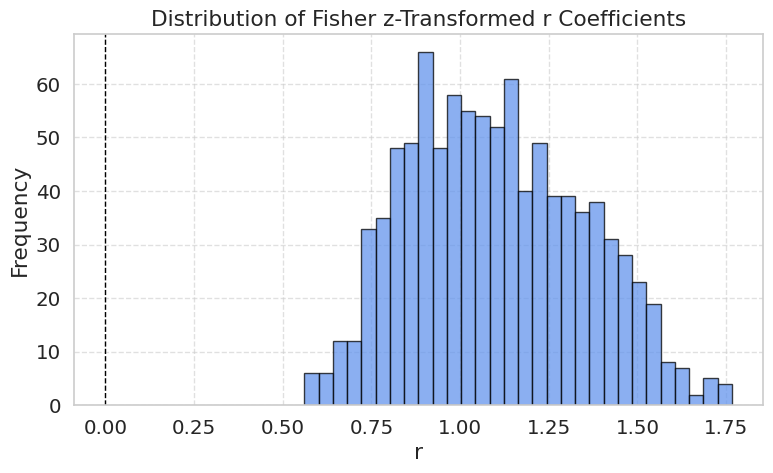

In [161]:
# Apply Fisher r-to-z transformation <- ALTHOUGH FOR ANALYSES NEED TO APPLY TRANSFORMATION ON CONCATENATED SAMPLE AT 3 TIMEPOINTS! (DOING THIS IN R)
list_SA_axis_corr_to_ref_fu4y_z = 0.5 * np.log((1 + np.array(list_SA_axis_corr_to_ref_fu4y)) / (1 - np.array(list_SA_axis_corr_to_ref_fu4y)))

# Plot histogram of transformed z values
# Plot histogram
plt.figure(figsize=(8, 5))
plt.hist(list_SA_axis_corr_to_ref_fu4y_z, bins=30, color='cornflowerblue', edgecolor='black', alpha=0.75)
plt.title("Distribution of Fisher z-Transformed r Coefficients")
plt.xlabel("r")
plt.ylabel("Frequency")
plt.axvline(0, color='black', linestyle='--', linewidth=1)  # reference line at r = 0
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [113]:
# export individual S-A axis 
mdict = {'array_SA_axis_fu4y': array_SA_axis_fu4y, 'sub_ID_fu4y': sub_ID_fu4y, 
         'list_SA_axis_grad_num_fu4y': list_SA_axis_grad_num_fu4y, 
         'list_SA_axis_corr_to_ref_fu4y': list_SA_axis_corr_to_ref_fu4y, 'list_SA_axis_corr_to_ref_fu4y_z': list_SA_axis_corr_to_ref_fu4y_z,
         'SA_axis_fu4y_individual_range': SA_axis_fu4y_individual_range
        }

scipy.io.savemat(datadir_local_longitudinal_sample+'array_SA_axis_NOT_aligned_fu4y.mat', mdict)

#
#
#
# Plotting for Figure

## Defining min and max gradient loadings across all (for common colorbar) and computing mean gradient range by timpoint

In [105]:
all_mean_grads = [mean_fc_grad.gradients_, mean_fc_grad_fu2y.gradients_, mean_fc_grad_fu4y.gradients_]

min_loading_across_all_G1 = 0
max_loading_across_all_G1 = 0

min_loading_across_all_G2 = 0
max_loading_across_all_G2 = 0

G1_mean_range = []
G2_mean_range = []

for grads_timepoint in all_mean_grads:

    ### G1

    # checking min and max
    if min(grads_timepoint[:, 0]) < min_loading_across_all_G1:
        min_loading_across_all_G1 = min(grads_timepoint[:, 0])
    if max(grads_timepoint[:, 0]) > max_loading_across_all_G1:
        max_loading_across_all_G1 = max(grads_timepoint[:, 0])

    # computing range
    G1_mean_range.append(max(grads_timepoint[:, 0]) - min(grads_timepoint[:, 0])) 

    
    ### G2

    # checking min and max
    if min(grads_timepoint[:, 1]) < min_loading_across_all_G2:
        min_loading_across_all_G2 = min(grads_timepoint[:, 1])

    if max(grads_timepoint[:, 1]) > max_loading_across_all_G2:
        max_loading_across_all_G2 = max(grads_timepoint[:, 1])

    # computing range
    G2_mean_range.append(max(grads_timepoint[:, 1]) - min(grads_timepoint[:, 1])) 


## Mean gradients

### baseline

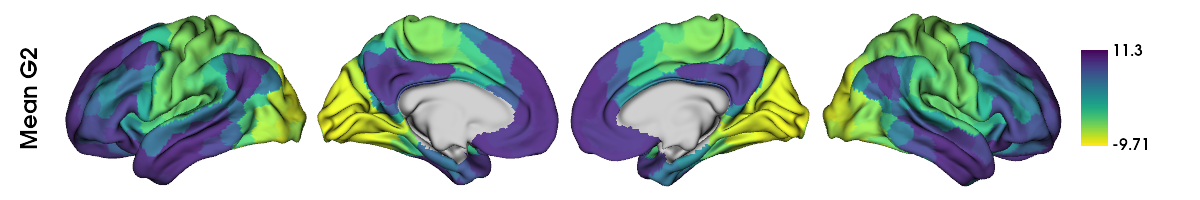

In [106]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(mean_fc_grad.gradients_[:, 1], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        color_range = (min_loading_across_all_G2, max_loading_across_all_G2),
                        label_text=['Mean G2'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_baseline_mean_G2.svg')

display(plot)

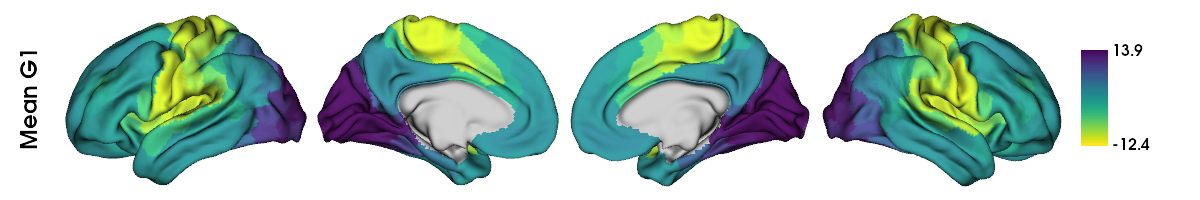

In [107]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(mean_fc_grad.gradients_[:, 0], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        color_range = (min_loading_across_all_G1, max_loading_across_all_G1),
                        label_text=['Mean G1'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_baseline_mean_G1.svg')

display(plot)

### fu2y

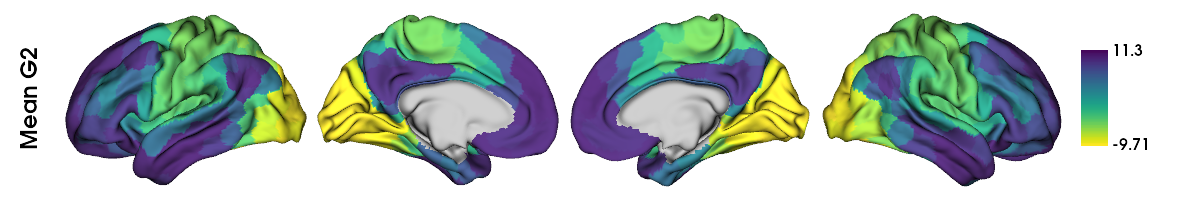

In [108]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(- mean_fc_grad_fu2y.gradients_[:, 1], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        color_range = (min_loading_across_all_G2, max_loading_across_all_G2),
                        label_text=['Mean G2'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_fu2y_mean_G2.svg')

display(plot)

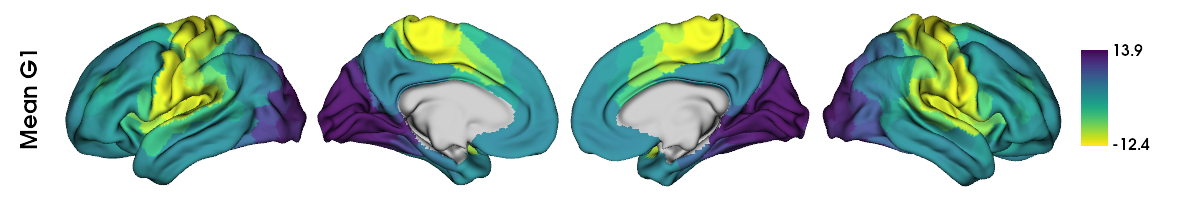

In [109]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(mean_fc_grad_fu2y.gradients_[:, 0], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        color_range = (min_loading_across_all_G1, max_loading_across_all_G1),
                        label_text=['Mean G1'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_fu2y_mean_G1.svg')

display(plot)

### fu4y

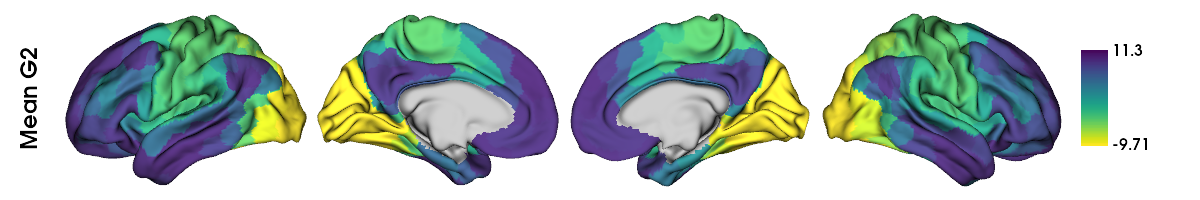

In [110]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(- mean_fc_grad_fu4y.gradients_[:, 1], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        color_range = (min_loading_across_all_G2, max_loading_across_all_G2),
                        label_text=['Mean G2'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_fu4y_mean_G2.svg')

display(plot)

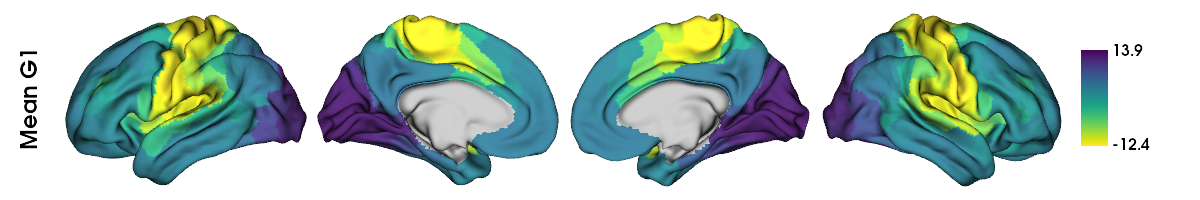

In [111]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(mean_fc_grad_fu4y.gradients_[:, 0], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        color_range = (min_loading_across_all_G1, max_loading_across_all_G1),
                        label_text=['Mean G1'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_fu4y_mean_G1.svg')

display(plot)

## Correlations between mean gradients

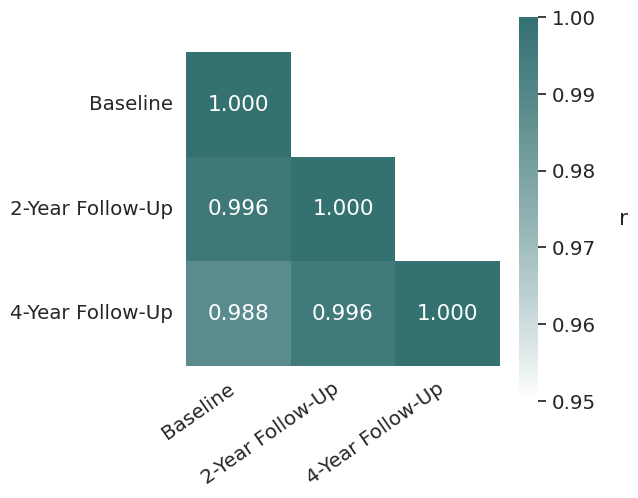

In [122]:
# --- Style setup ---
sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Extract gradient vectors ---
g_baseline = mean_fc_grad.gradients_[:, 1]
g_fu2y = - mean_fc_grad_fu2y.gradients_[:, 1]
g_fu4y = - mean_fc_grad_fu4y.gradients_[:, 1]

# --- Assemble into DataFrame ---
df_grad = pd.DataFrame({
    "Baseline": g_baseline,
    "2-Year Follow-Up": g_fu2y,
    "4-Year Follow-Up": g_fu4y
})

# --- Compute Spearman correlation matrix ---
corr_mat = df_grad.corr(method="spearman")

# --- Create single-hue colormap with alpha ---
base_color = mcolors.to_rgba("xkcd:dark teal", alpha=0.8)
cmap = mcolors.LinearSegmentedColormap.from_list(
    "indigo_alpha",
    [(1, 1, 1, 1), base_color]
)

# --- Plot heatmap ---
fig, ax = plt.subplots(figsize=(6.5, 5.5))

mask = np.triu(np.ones_like(corr_mat, dtype=bool), k=1)

# --- Apply mask by setting values to NaN ---
corr_plot = corr_mat.mask(mask)

hm = sns.heatmap(
    corr_plot,
    #mask=mask,
    ax=ax,
    cmap=cmap,
    vmin=0.95,
    vmax=1,
    square=True,
    annot=True,
    fmt=".3f",
    #linewidths=0.8,
    linewidths=0,          # <- no gridlines in masked area
    linecolor="black",
    cbar_kws={"label": "r"}
)


# Use mapped labels, only for observed categories
xtick_labels = df_grad.columns
ax.set_xticklabels(xtick_labels, rotation=35, ha="right")

# Rotate colorbar label
cbar = hm.collections[0].colorbar
cbar.set_label("r", rotation=0, labelpad=20)

# --- Improve aesthetics ---
ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()

plt.savefig(resdir_fig+"corr_G2_heatmap.svg", dpi=300, bbox_inches="tight")


In [123]:
# --- Extract gradient vectors ---
g_baseline = mean_fc_grad.gradients_[:, 1]
g_fu2y = mean_fc_grad_fu2y.gradients_[:, 1]
g_fu4y = mean_fc_grad_fu4y.gradients_[:, 1]

spin_test_p, spin_test_d = spin_test(  
        g_baseline, 
        g_fu2y,
        surface_name='fsa5', 
        parcellation_name='schaefer_400',
        type='spearman', 
        n_rot=1000, 
        null_dist=True
    )

print(f"Spin permutation test p-value (baseline-2y): {spin_test_p}")

spin_test_p, spin_test_d = spin_test(  
        g_baseline, 
        g_fu4y,
        surface_name='fsa5', 
        parcellation_name='schaefer_400',
        type='spearman', 
        n_rot=1000, 
        null_dist=True
    )

print(f"Spin permutation test p-value (baseline-4y): {spin_test_p}")

spin_test_p, spin_test_d = spin_test(  
        g_fu2y, 
        g_fu4y,
        surface_name='fsa5', 
        parcellation_name='schaefer_400',
        type='spearman', 
        n_rot=1000, 
        null_dist=True
    )

print(f"Spin permutation test p-value: {spin_test_p}")

print(f"Spin permutation test p-value (2y-4y): {spin_test_p}")

permutation 100 of 1000
permutation 200 of 1000
permutation 300 of 1000
permutation 400 of 1000
permutation 500 of 1000
permutation 600 of 1000
permutation 700 of 1000
permutation 800 of 1000
permutation 900 of 1000
permutation 1000 of 1000
Spin permutation test p-value (baseline-2y): 0.0
permutation 100 of 1000
permutation 200 of 1000
permutation 300 of 1000
permutation 400 of 1000
permutation 500 of 1000
permutation 600 of 1000
permutation 700 of 1000
permutation 800 of 1000
permutation 900 of 1000
permutation 1000 of 1000
Spin permutation test p-value (baseline-4y): 0.0
permutation 100 of 1000
permutation 200 of 1000
permutation 300 of 1000
permutation 400 of 1000
permutation 500 of 1000
permutation 600 of 1000
permutation 700 of 1000
permutation 800 of 1000
permutation 900 of 1000
permutation 1000 of 1000
Spin permutation test p-value: 0.0
Spin permutation test p-value (2y-4y): 0.0


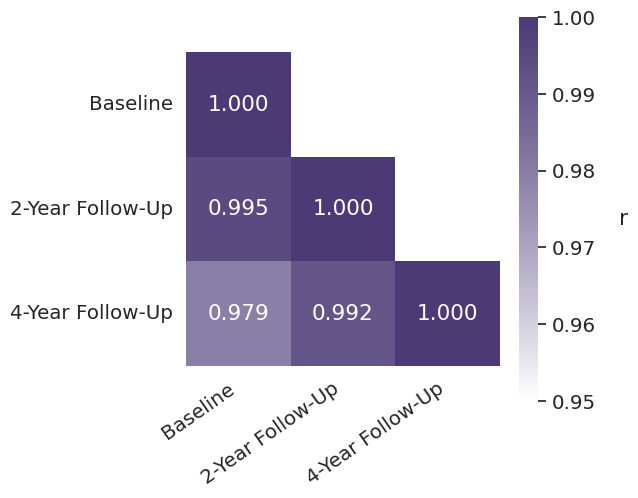

In [124]:
# --- Style setup ---
sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Extract gradient vectors ---
g_baseline = mean_fc_grad.gradients_[:, 0]
g_fu2y = mean_fc_grad_fu2y.gradients_[:, 0]
g_fu4y = mean_fc_grad_fu4y.gradients_[:, 0]

# --- Assemble into DataFrame ---
df_grad = pd.DataFrame({
    "Baseline": g_baseline,
    "2-Year Follow-Up": g_fu2y,
    "4-Year Follow-Up": g_fu4y
})

# --- Compute Spearman correlation matrix ---
corr_mat = df_grad.corr(method="spearman")

# --- Create single-hue colormap with alpha ---
base_color = mcolors.to_rgba("xkcd:dark indigo", alpha=0.8)
cmap = mcolors.LinearSegmentedColormap.from_list(
    "indigo_alpha",
    [(1, 1, 1, 1), base_color]
)

# --- Plot heatmap ---
fig, ax = plt.subplots(figsize=(6.5, 5.5))

mask = np.triu(np.ones_like(corr_mat, dtype=bool), k=1)

# --- Apply mask by setting values to NaN ---
corr_plot = corr_mat.mask(mask)

hm = sns.heatmap(
    corr_plot,
    ax=ax,
    cmap=cmap,
    vmin=0.95,
    vmax=1,
    square=True,
    annot=True,
    fmt=".3f",
    #linewidths=0.8,
    linewidths=0,          # <- no gridlines in masked area
    linecolor="black",
    cbar_kws={"label": "r"}
)


# Use mapped labels, only for observed categories
xtick_labels = df_grad.columns
ax.set_xticklabels(xtick_labels, rotation=35, ha="right")

# Rotate colorbar label
cbar = hm.collections[0].colorbar
cbar.set_label("r", rotation=0, labelpad=20)

# --- Improve aesthetics ---
ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()

plt.savefig(resdir_fig+"corr_G1_heatmap.svg", dpi=300, bbox_inches="tight")


In [125]:
# --- Extract gradient vectors ---
g_baseline = mean_fc_grad.gradients_[:, 0]
g_fu2y = mean_fc_grad_fu2y.gradients_[:, 0]
g_fu4y = mean_fc_grad_fu4y.gradients_[:, 0]

spin_test_p, spin_test_d = spin_test(  
        g_baseline, 
        g_fu2y,
        surface_name='fsa5', 
        parcellation_name='schaefer_400',
        type='spearman', 
        n_rot=1000, 
        null_dist=True
    )

print(f"Spin permutation test p-value (baseline-2y): {spin_test_p}")

spin_test_p, spin_test_d = spin_test(  
        g_baseline, 
        g_fu4y,
        surface_name='fsa5', 
        parcellation_name='schaefer_400',
        type='spearman', 
        n_rot=1000, 
        null_dist=True
    )

print(f"Spin permutation test p-value (baseline-4y): {spin_test_p}")

spin_test_p, spin_test_d = spin_test(  
        g_fu2y, 
        g_fu4y,
        surface_name='fsa5', 
        parcellation_name='schaefer_400',
        type='spearman', 
        n_rot=1000, 
        null_dist=True
    )

print(f"Spin permutation test p-value (2y-4y): {spin_test_p}")

permutation 100 of 1000
permutation 200 of 1000
permutation 300 of 1000
permutation 400 of 1000
permutation 500 of 1000
permutation 600 of 1000
permutation 700 of 1000
permutation 800 of 1000
permutation 900 of 1000
permutation 1000 of 1000
Spin permutation test p-value (baseline-2y): 0.0
permutation 100 of 1000
permutation 200 of 1000
permutation 300 of 1000
permutation 400 of 1000
permutation 500 of 1000
permutation 600 of 1000
permutation 700 of 1000
permutation 800 of 1000
permutation 900 of 1000
permutation 1000 of 1000
Spin permutation test p-value (baseline-4y): 0.0
permutation 100 of 1000
permutation 200 of 1000
permutation 300 of 1000
permutation 400 of 1000
permutation 500 of 1000
permutation 600 of 1000
permutation 700 of 1000
permutation 800 of 1000
permutation 900 of 1000
permutation 1000 of 1000
Spin permutation test p-value (2y-4y): 0.0


## Scree plot

In [113]:
sum_lambdas_baseline = np.sum(mean_fc_grad.lambdas_)
sum_lambdas_fu2y = np.sum(mean_fc_grad_fu2y.lambdas_)
sum_lambdas_fu4y = np.sum(mean_fc_grad_fu4y.lambdas_)


scaled_var_explained_mean_grad_baseline = mean_fc_grad.lambdas_ / sum_lambdas_baseline * 100
scaled_var_explained_mean_grad_fu2y = mean_fc_grad_fu2y.lambdas_ / sum_lambdas_fu2y * 100
scaled_var_explained_mean_grad_fu4y = mean_fc_grad_fu4y.lambdas_ / sum_lambdas_fu4y * 100

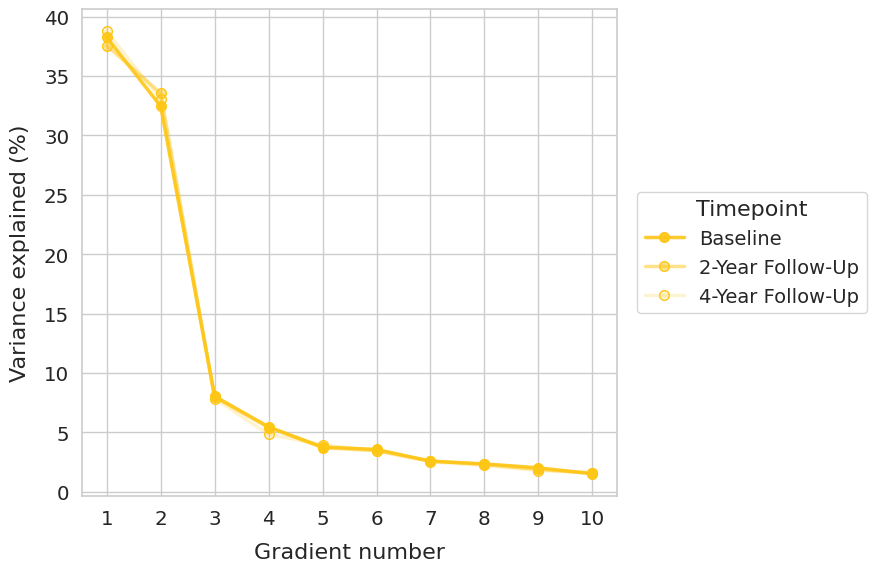

In [127]:
data = [
    scaled_var_explained_mean_grad_baseline,
    scaled_var_explained_mean_grad_fu2y,
    scaled_var_explained_mean_grad_fu4y
]

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]
alpha_map = {"Baseline": 0.9, "2-Year Follow-Up": 0.5, "4-Year Follow-Up": 0.2}

# --- Style setup ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Prepare data ---
x = np.arange(1, 11)  # Gradient numbers 1–10
color_base = 'xkcd:golden yellow'

# --- Create figure ---
fig, ax = plt.subplots(figsize=(7, 6))

# --- Draw lines and points ---
for i, tp in enumerate(timepoints):
    y = data[i]
    rgba = mcolors.to_rgba(color_base, alpha=alpha_map[tp])
    
    ax.plot(
        x, y, 
        color=rgba, 
        linewidth=2.5, 
        marker='o', 
        markeredgecolor='xkcd:golden yellow',
        markersize=7, 
        label=tp
    )

# --- Axis labels, ticks, and legend ---
ax.set_xticks(x)
ax.set_xticklabels(x)
ax.set_xlabel("Gradient number", fontsize=16, labelpad=10)
ax.set_ylabel("Variance explained (%)", fontsize=16, labelpad=10)

#ax.legend(
#    title="Timepoint", frameon=True, facecolor='white',
#    fontsize=14, title_fontsize=16, bbox_to_anchor=(0.95, 0.85)
#)

ax.legend(
    title="Timepoint",
    frameon=True,
    facecolor='white',
    fontsize=14,
    title_fontsize=16,
    loc='center left',
    bbox_to_anchor=(1.02, 0.5)  # (x, y) coordinates relative to the axes
)


plt.tight_layout()
plt.subplots_adjust(right=0.9)

# --- Save figure ---
plt.savefig(resdir_fig + "lineplot_var_explained_mean_grad.svg", format="svg", bbox_inches="tight", dpi=300)

plt.show()


In [128]:
scaled_var_explained_mean_grad_baseline[0:2]

array([38.26327594, 32.459417  ])

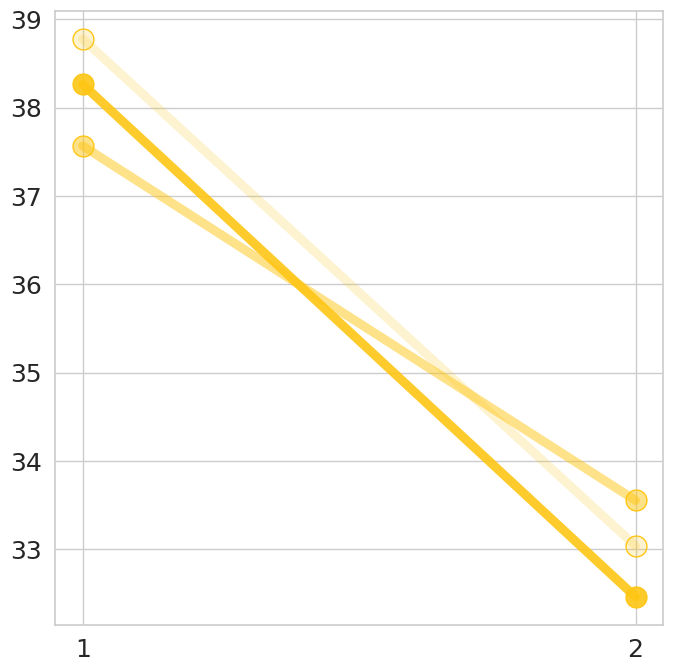

In [129]:
data = [
    scaled_var_explained_mean_grad_baseline[0:2],
    scaled_var_explained_mean_grad_fu2y[0:2],
    scaled_var_explained_mean_grad_fu4y[0:2]
]

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]
alpha_map = {"Baseline": 0.9, "2-Year Follow-Up": 0.5, "4-Year Follow-Up": 0.2}

# --- Style setup ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Prepare data ---
x = np.arange(1, 3)  # Gradient numbers 1–2
color_base = 'xkcd:golden yellow'

# --- Create figure ---
fig, ax = plt.subplots(figsize=(7, 7))

# --- Draw lines and points ---
for i, tp in enumerate(timepoints):
    y = data[i]
    rgba = mcolors.to_rgba(color_base, alpha=alpha_map[tp])
    
    ax.plot(
        x, y, 
        color=rgba, 
        linewidth=6.5, 
        marker='o', 
        markeredgecolor='xkcd:golden yellow',
        markersize=15, 
        label=tp
    )

# --- Axis labels, ticks, and legend --
ax.tick_params(axis='both', labelsize=18)
ax.set_xticks(x)
ax.set_xticklabels(x, fontsize=18)
#ax.set_xlabel("Gradient number", fontsize=16, labelpad=10)
#ax.set_ylabel("Variance explained (%)", fontsize=16, labelpad=10)

#ax.legend(
#    title="Timepoint", frameon=True, facecolor='white',
#    fontsize=14, title_fontsize=16, bbox_to_anchor=(0.95, 0.85)
#)

plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir_fig + "lineplot_var_explained_mean_grad_G1G2_zoom.svg", format="svg", bbox_inches="tight", dpi=300)

plt.show()


## Individual level distance to flip
-> i.e., difference between variance explained by S-A axis vs other gradient

Measure quantifying "how far" from gradient flip (interpretation assuming it's a continuous progression)

Positive value: flip has occured

Negative value: flip has not yet occured

/tmp/ipykernel_76894/3512024856.py:44: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right', frameon=False)


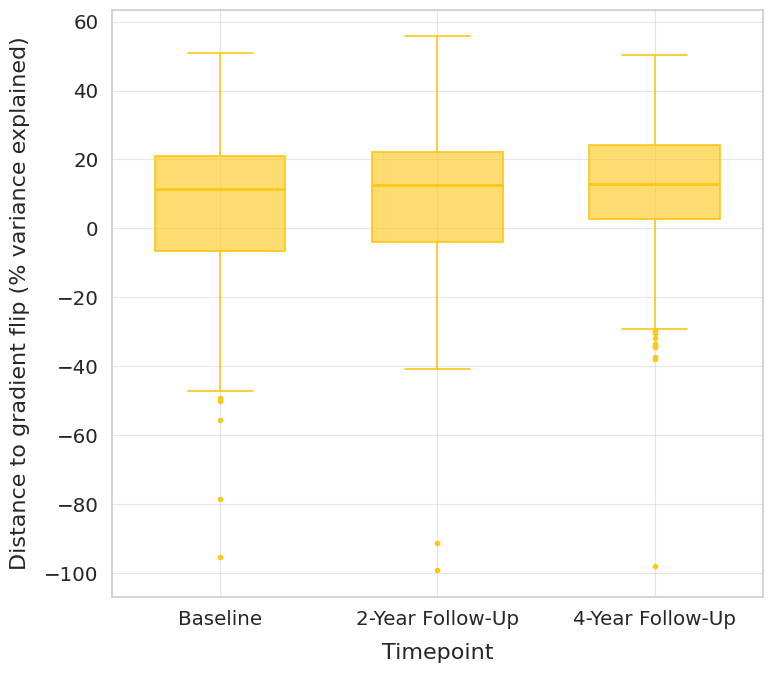

In [164]:
# --- Data setup ---
timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

data = [
    diff_scaled_var_exp_SA_axis_other1_baseline,
    diff_scaled_var_exp_SA_axis_other1_fu2y,
    diff_scaled_var_exp_SA_axis_other1_fu4y
]

alpha_map = {"Baseline": 0.6, "2-Year Follow-Up": 0.6, "4-Year Follow-Up": 0.6}  # 0.8, 0.6, 0.3
color_base = 'xkcd:golden yellow'

# --- Style setup (consistent with other figures) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axis ---
fig, ax = plt.subplots(figsize=(8, 7))

# --- Draw boxplots ---
for i, tp in enumerate(timepoints):
    rgba = mcolors.to_rgba(color_base, alpha=alpha_map[tp])
    ax.boxplot(
        data[i],
        positions=[i],
        widths=0.6,
        patch_artist=True,
        boxprops=dict(facecolor=rgba, color=color_base, linewidth=1.2),
        medianprops=dict(color=color_base, linewidth=2),
        whiskerprops=dict(color=color_base, linewidth=1.2),
        capprops=dict(color=color_base, linewidth=1.2),
        flierprops=dict(marker='o', markersize=3, alpha=1,
                        markerfacecolor=color_base, markeredgecolor='xkcd:golden yellow')
    )


# --- Formatting ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("Distance to gradient flip (% variance explained)", fontsize=16, labelpad=10)
ax.grid(True, linestyle='-', linewidth=0.8, alpha=0.5)
ax.legend(loc='upper right', frameon=False)

#sns.despine()

plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir_fig + "boxplot_dist_to_flip.svg", format="svg", bbox_inches="tight", dpi=300)
plt.show()


## S-A axis range

In [132]:
print(G1_mean_range)
print(G2_mean_range)

[24.40909575292605, 24.527311546835527, 24.915213574052373]
[17.95162390257029, 19.792372383038533, 20.58424670315199]


In [162]:
### Detecting outliers -> across timepoints

individual_range_all_timpoints = np.concatenate((SA_axis_baseline_individual_range, SA_axis_fu2y_individual_range, SA_axis_fu4y_individual_range), axis=0)

# Compute quartiles
Q1 = np.percentile(individual_range_all_timpoints, 25)
Q3 = np.percentile(individual_range_all_timpoints, 75)
IQR = Q3 - Q1

# Compute cutoff bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1 = {Q1:.2f}, Q3 = {Q3:.2f}, IQR = {IQR:.2f}")
print("\nLower and upper bounds are computed as Q1 - 1.5 * IQR and Q1 + 1.5 * IQR respectively")
print(f"Lower bound = {lower_bound:.2f}")
print(f"Upper bound = {upper_bound:.2f}")

# Identify outliers
outliers_baseline = SA_axis_baseline_individual_range[(SA_axis_baseline_individual_range < lower_bound) | (SA_axis_baseline_individual_range > upper_bound)]
outliers_fu2y = SA_axis_fu2y_individual_range[(SA_axis_fu2y_individual_range < lower_bound) | (SA_axis_fu2y_individual_range > upper_bound)]
outliers_fu4y = SA_axis_fu4y_individual_range[(SA_axis_fu4y_individual_range < lower_bound) | (SA_axis_fu4y_individual_range > upper_bound)]

print("")

print(f"Outliers baseline: {len(outliers_baseline)}:{outliers_baseline}")
print(f"Outliers fu2y: {len(outliers_fu2y)}: {outliers_fu2y}")
print(f"Outliers fu4y: {len(outliers_fu4y)}: {outliers_fu4y}")

print("")

print(f"Max outlier baseline: {np.round(max(SA_axis_baseline_individual_range), 2)}")
print(f"Max outlier fu2y: {np.round(max(SA_axis_fu2y_individual_range), 2)}")
print(f"Max outlier fu4y: {np.round(max(SA_axis_fu4y_individual_range), 2)}")


Q1 = 11.64, Q3 = 17.67, IQR = 6.03

Lower and upper bounds are computed as Q1 - 1.5 * IQR and Q1 + 1.5 * IQR respectively
Lower bound = 2.60
Upper bound = 26.71

Outliers baseline: 39:[ 32.5122698   28.77861266  28.28902642  27.38214255  26.74126284
  27.3751482   27.98697695  27.10852233  26.90547237  26.73654522
  29.50805498  28.87470609  27.25911118  50.12940988  27.14083296
  26.81363102  31.83049289  26.75961626  26.92163462  32.9878446
  27.68810996  29.55787315 385.44475413  27.15563366  27.77643731
  34.78741036  28.8533786   28.12336064  27.80782152  28.27411098
  28.50631286  27.43466737  28.1301927   28.56629402  33.21114849
  34.59658652  27.04153597  32.49738778  27.48965327]
Outliers fu2y: 12: [28.4190264  29.33927613 28.58704678 28.75824969 29.1721418  26.82741643
 28.83946295 28.12272938 26.81922268 27.07039053 38.24108704 30.86986716]
Outliers fu4y: 17: [27.14605347 34.92775474 27.28986419 27.38871998 27.0533947  33.871996
 27.92047742 29.50213628 27.39116048 29.71260

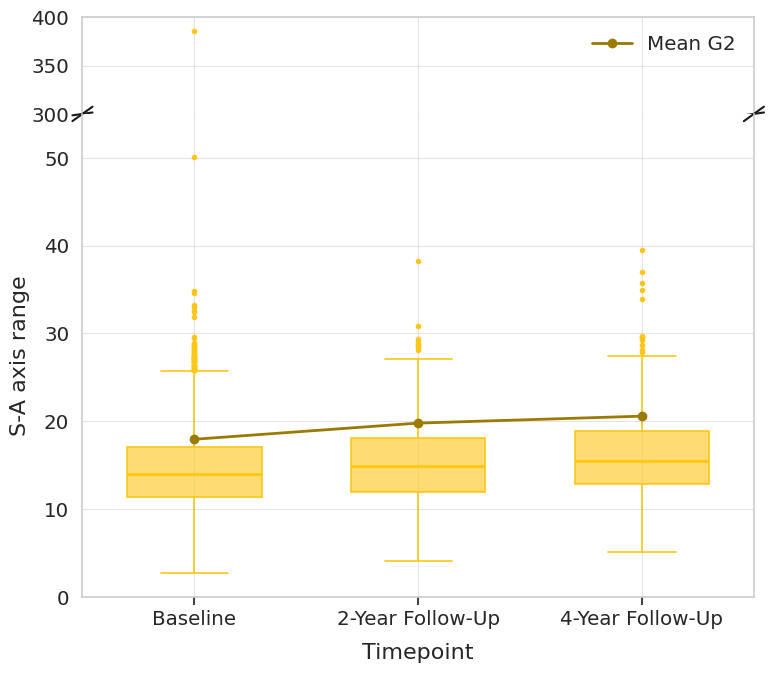

In [163]:
timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

data = [
    SA_axis_baseline_individual_range,
    SA_axis_fu2y_individual_range,
    SA_axis_fu4y_individual_range
]

alpha_map = {"Baseline": 0.6, "2-Year Follow-Up": 0.6, "4-Year Follow-Up": 0.6}  # 0.8, 0.6, 0.3
color_base = 'xkcd:golden yellow'

# --- Style setup (match your other figures) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure with broken axis ---
fig, (ax_top, ax_bottom) = plt.subplots(
    2, 1, sharex=True, figsize=(8, 7),
    gridspec_kw={'height_ratios': [1, 5], 'hspace': 0}
)

# --- Function to draw boxplots with color and alpha ---
def draw_boxplots(ax, data):
    for i, tp in enumerate(timepoints):
        rgba = mcolors.to_rgba(color_base, alpha=alpha_map[tp])
        bp = ax.boxplot(
            data[i],
            positions=[i],
            widths=0.6,
            patch_artist=True,
            boxprops=dict(facecolor=rgba, color=color_base, linewidth=1.2),
            medianprops=dict(color=color_base, linewidth=2),
            whiskerprops=dict(color=color_base, linewidth=1.2),
            capprops=dict(color=color_base, linewidth=1.2),
            flierprops=dict(marker='o', markersize=3, alpha=1, markerfacecolor=color_base, markeredgecolor='xkcd:golden yellow')
        )
    # Overlay mean line
    ax.plot(np.arange(len(timepoints)), G2_mean_range, marker='o', color='xkcd:yellowish brown', linewidth=2, label='Mean G2')
    ax.grid(True, linestyle='-', linewidth=0.8, alpha=0.5)

# --- Draw boxplots ---
draw_boxplots(ax_bottom, data)
draw_boxplots(ax_top, data)

# --- Set y-limits for broken axis ---
ax_bottom.set_ylim(0, 55)
ax_top.set_ylim(300, 400)

# --- Hide spines between axes ---
ax_top.spines.bottom.set_visible(False)
ax_bottom.spines.top.set_visible(False)
ax_top.tick_params(labeltop=False)
ax_bottom.xaxis.tick_bottom()

# --- Diagonal break marks ---
d = .015
kwargs = dict(transform=ax_top.transAxes, color='k', clip_on=False)
ax_top.plot((-d, +d), (-d, +d), **kwargs)
ax_top.plot((1 - d, 1 + d), (-d, +d), **kwargs)
kwargs.update(transform=ax_bottom.transAxes)
ax_bottom.plot((-d, +d), (1 - d, 1 + d), **kwargs)
ax_bottom.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

# --- Axis labels ---
ax_bottom.set_xticks(np.arange(len(timepoints)))
ax_bottom.set_xticklabels(timepoints)
ax_bottom.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax_bottom.set_ylabel("S-A axis range", fontsize=16, labelpad=10)
ax_top.legend(loc='upper right', frameon=False)

# --- Despine and layout ---
#sns.despine(trim=True)
plt.tight_layout(h_pad=0.05)

# --- Save figure ---
plt.savefig(resdir_fig+"boxplot_SA_axis_individual_range.svg", format="svg", bbox_inches="tight", dpi=300)

In [165]:
print("Baseline")
print(f"Min range: {np.min(SA_axis_baseline_individual_range):.2f}")
print(f"Max range: {np.max(SA_axis_baseline_individual_range):.2f}")
print(f"Mean range: {np.mean(SA_axis_baseline_individual_range):.2f}, sd: {np.std(SA_axis_baseline_individual_range):.2f}")
print(f"Median range: {np.median(SA_axis_baseline_individual_range):.2f}")

print("\n2y")
print(f"Min range: {np.min(SA_axis_fu2y_individual_range):.2f}")
print(f"Max range: {np.max(SA_axis_fu2y_individual_range):.2f}")
print(f"Mean range: {np.mean(SA_axis_fu2y_individual_range):.2f}, sd: {np.std(SA_axis_fu2y_individual_range):.2f}")
print(f"Median range: {np.median(SA_axis_fu2y_individual_range):.2f}")

print("\n4y")
print(f"Min range: {np.min(SA_axis_fu4y_individual_range):.2f}")
print(f"Max range: {np.max(SA_axis_fu4y_individual_range):.2f}")
print(f"Mean range: {np.mean(SA_axis_fu4y_individual_range):.2f}, sd: {np.std(SA_axis_fu4y_individual_range):.2f}")
print(f"Median range: {np.median(list_SA_axis_corr_to_ref_fu4y):.2f}")

Baseline
Min range: 2.77
Max range: 385.44
Mean range: 14.57, sd: 7.31
Median range: 13.99

2y
Min range: 4.06
Max range: 38.24
Mean range: 15.25, sd: 4.37
Median range: 14.88

4y
Min range: 5.14
Max range: 39.46
Mean range: 16.04, sd: 4.61
Median range: 0.79


## R coef

In [106]:
### Computing r coef for correlation of mean G2 to adult S-A axis

G2_mean_rcoef = []
G2_mean_rcoef.append(stats.spearmanr(mean_fc_grad.gradients_[:,1], Margulies_gradients_schaefer400[0])[0])
G2_mean_rcoef.append(stats.spearmanr(- mean_fc_grad_fu2y.gradients_[:,1], Margulies_gradients_schaefer400[0])[0])
G2_mean_rcoef.append(stats.spearmanr(- mean_fc_grad_fu4y.gradients_[:,1], Margulies_gradients_schaefer400[0])[0])

In [107]:
G2_mean_rcoef

[0.8975105469409183, 0.8826252039075244, 0.8660645379033618]

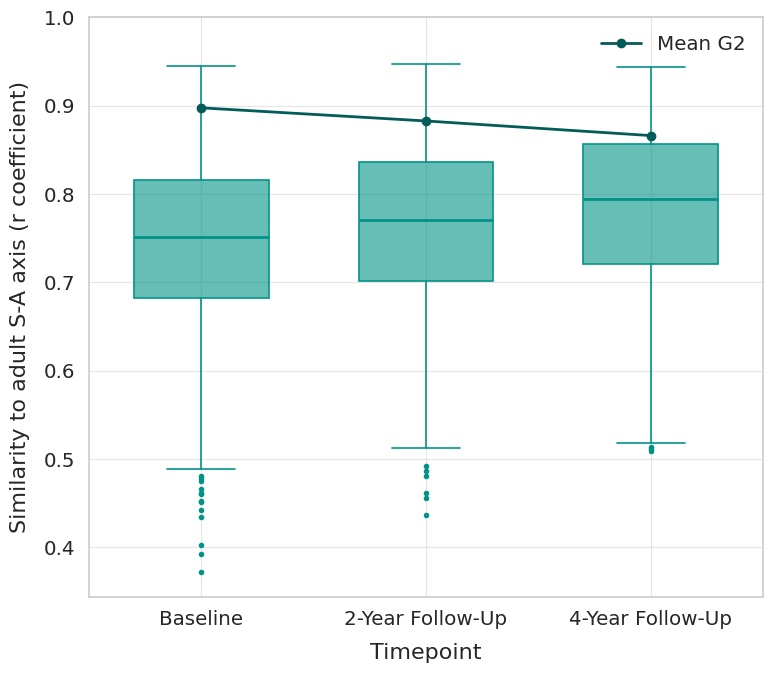

In [108]:
# --- Data setup ---
timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

data = [
    list_SA_axis_corr_to_ref_baseline,
    list_SA_axis_corr_to_ref_fu2y,
    list_SA_axis_corr_to_ref_fu4y
]

alpha_map = {"Baseline": 0.6, "2-Year Follow-Up": 0.6, "4-Year Follow-Up": 0.6}  # 0.8, 0.6, 0.3
color_base = 'xkcd:teal'

# --- Style setup (consistent with other figures) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axis ---
fig, ax = plt.subplots(figsize=(8, 7))

# --- Draw boxplots ---
for i, tp in enumerate(timepoints):
    rgba = mcolors.to_rgba(color_base, alpha=alpha_map[tp])
    ax.boxplot(
        data[i],
        positions=[i],
        widths=0.6,
        patch_artist=True,
        boxprops=dict(facecolor=rgba, color=color_base, linewidth=1.2),
        medianprops=dict(color=color_base, linewidth=2),
        whiskerprops=dict(color=color_base, linewidth=1.2),
        capprops=dict(color=color_base, linewidth=1.2),
        flierprops=dict(marker='o', markersize=3, alpha=1,
                        markerfacecolor=color_base, markeredgecolor='xkcd:teal')
    )

# --- (Optional) Overlay mean line across timepoints ---
ax.plot(np.arange(len(timepoints)), G2_mean_rcoef, marker='o', color='xkcd:dark turquoise', linewidth=2, label='Mean G2')

ax.set_ylim(top=1)

# --- Formatting ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("Similarity to adult S-A axis (r coefficient)", fontsize=16, labelpad=10)
ax.grid(True, linestyle='-', linewidth=0.8, alpha=0.5)
ax.legend(loc='upper right', frameon=False)

#sns.despine()

plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir_fig + "boxplot_rcoef.svg", format="svg", bbox_inches="tight", dpi=300)
plt.show()


In [112]:
print("Baseline")
print(f"Min rcoef: {np.min(list_SA_axis_corr_to_ref_baseline):.2f}")
print(f"Max rcoef: {np.max(list_SA_axis_corr_to_ref_baseline):.2f}")
print(f"Mean rcoef: {np.mean(list_SA_axis_corr_to_ref_baseline):.2f}, sd: {np.std(list_SA_axis_corr_to_ref_baseline):.2f}")
print(f"Median rcoef: {np.median(list_SA_axis_corr_to_ref_baseline):.2f}")

print("\n2y")
print(f"Min rcoef: {np.min(list_SA_axis_corr_to_ref_fu2y):.2f}")
print(f"Max rcoef: {np.max(list_SA_axis_corr_to_ref_fu2y):.2f}")
print(f"Mean rcoef: {np.mean(list_SA_axis_corr_to_ref_fu2y):.2f}, sd: {np.std(list_SA_axis_corr_to_ref_fu2y):.2f}")
print(f"Median rcoef: {np.median(list_SA_axis_corr_to_ref_fu2y):.2f}")

print("\n4y")
print(f"Min rcoef: {np.min(list_SA_axis_corr_to_ref_fu4y):.2f}")
print(f"Max rcoef: {np.max(list_SA_axis_corr_to_ref_fu4y):.2f}")
print(f"Mean rcoef: {np.mean(list_SA_axis_corr_to_ref_fu4y):.2f}, sd: {np.std(list_SA_axis_corr_to_ref_fu4y):.2f}")
print(f"Median rcoef: {np.median(list_SA_axis_corr_to_ref_fu4y):.2f}")

Baseline
Min rcoef: 0.37
Max rcoef: 0.94
Mean rcoef: 0.75, sd: 0.09
Median rcoef: 0.75

2y
Min rcoef: 0.44
Max rcoef: 0.95
Mean rcoef: 0.76, sd: 0.09
Median rcoef: 0.77

4y
Min rcoef: 0.51
Max rcoef: 0.94
Mean rcoef: 0.78, sd: 0.09
Median rcoef: 0.79


## Gradient flip

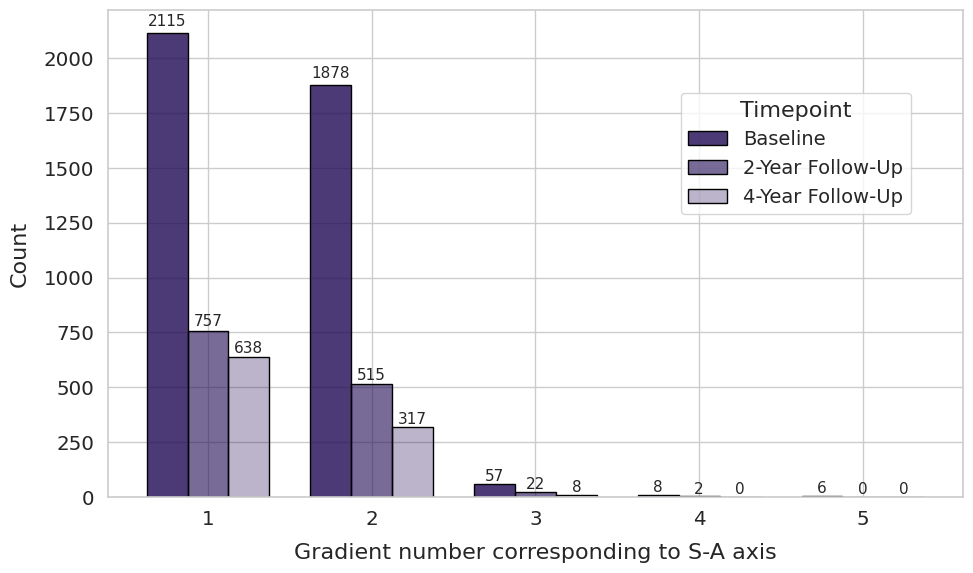

In [145]:
data_counts = [
    Counter(list_SA_axis_grad_num_baseline),
    Counter(list_SA_axis_grad_num_fu2y),
    Counter(list_SA_axis_grad_num_fu4y)
]


timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]
alpha_map = {"Baseline": 0.8, "2-Year Follow-Up": 0.6, "4-Year Follow-Up": 0.3}



# --- Style setup ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Prepare bar plot data ---
keys = sorted(set().union(*[c.keys() for c in data_counts]))
values_matrix = [[c.get(k, 0) for k in keys] for c in data_counts]
x = np.arange(len(keys))
width = 0.25

# --- Create single continuous axis figure ---
fig, ax = plt.subplots(figsize=(10, 6))

# --- Draw bars on single axis ---
for i, tp in enumerate(timepoints):
    values = values_matrix[i]
    rgba = mcolors.to_rgba('xkcd:dark indigo', alpha=alpha_map[tp])
    bar_positions = x + i * width - width

    bars = ax.bar(
        bar_positions, values, width=width,
        color=rgba, edgecolor='black', label=tp
    )

    # Annotate counts on bars
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, val*1.01, str(val),
                ha='center', va='bottom', fontsize=11)

# --- Axis labels and legend ---
ax.set_xticks(x)
ax.set_xticklabels(keys)
ax.set_xlabel("Gradient number corresponding to S-A axis", fontsize=16, labelpad=10)
ax.set_ylabel("Count", fontsize=16, labelpad=10)

ax.legend(title="Timepoint", frameon=True, facecolor='white', fontsize=14, title_fontsize=16, bbox_to_anchor=(0.95, 0.85))

plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir_fig+"barplot_gradient_counts.svg", format="svg", bbox_inches="tight", dpi=300)

plt.show()


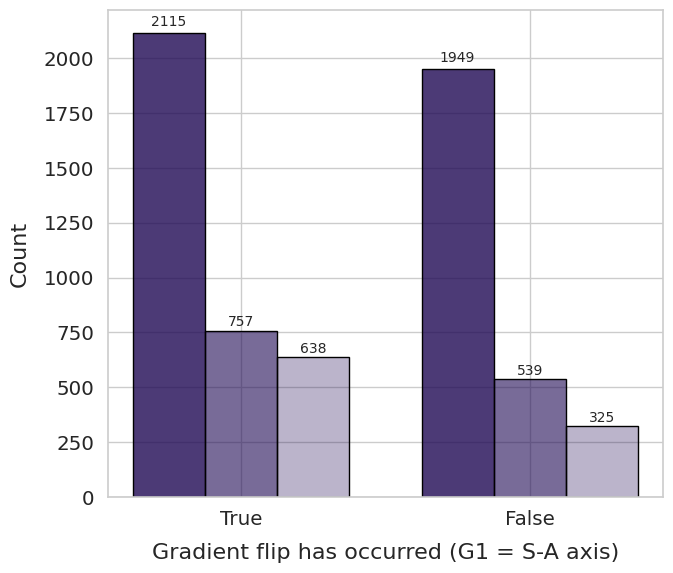

In [146]:
import matplotlib.colors as mcolors


# creating new lists of just 0s and 1s for if gradient flip has occurred or not: 1 True; 0 False
grad_flip_baseline = [True if x == 1 else False for x in list_SA_axis_grad_num_baseline]
grad_flip_fu2y = [True if x == 1 else False for x in list_SA_axis_grad_num_fu2y]
grad_flip_fu4y = [True if x == 1 else False for x in list_SA_axis_grad_num_fu4y]


# --- Count occurrences ---
data_counts = [
    Counter(grad_flip_baseline),
    Counter(grad_flip_fu2y),
    Counter(grad_flip_fu4y)
]

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]
alpha_map = {"Baseline": 0.8, "2-Year Follow-Up": 0.6, "4-Year Follow-Up": 0.3}

# --- Style setup ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Prepare bar plot data ---
keys = sorted(set().union(*[c.keys() for c in data_counts]), reverse=True)
values_matrix = [[c.get(k, 0) for k in keys] for c in data_counts]
x = np.arange(len(keys))
width = 0.25

# --- Create single figure/axis ---
fig, ax = plt.subplots(figsize=(7, 6))

# --- Draw bars ---
for i, tp in enumerate(timepoints):
    values = values_matrix[i]
    rgba = mcolors.to_rgba('xkcd:dark indigo', alpha=alpha_map[tp])
    bar_positions = x + i * width - width

    bars = ax.bar(
        bar_positions, values, width=width,
        color=rgba, edgecolor='black', label=tp
    )

    # Annotate counts
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, val * 1.01, str(val),
                ha='center', va='bottom', fontsize=10)

# --- Axis formatting ---
ax.set_xticks(x)
ax.set_xticklabels(keys)
ax.set_xlabel("Gradient flip has occurred (G1 = S-A axis)", fontsize=16, labelpad=10)
ax.set_ylabel("Count", fontsize=16, labelpad=10)
#ax.legend(title="Timepoint", frameon=True, facecolor='white',fontsize=14, title_fontsize=16, bbox_to_anchor=(1.5, 0.85))

#sns.despine()
plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir_fig + "barplot_gradflip_counts.svg", format="svg", bbox_inches="tight", dpi=300)
plt.show()


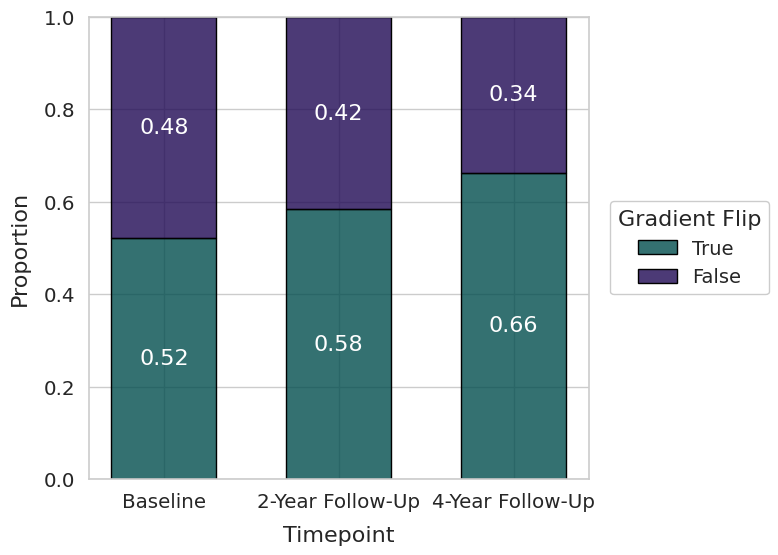

In [151]:
import matplotlib.colors as mcolors
from collections import Counter
from matplotlib.patches import Patch

# creating new lists of just True/False for if gradient flip has occurred or not
grad_flip_baseline = [True if x == 1 else False for x in list_SA_axis_grad_num_baseline]
grad_flip_fu2y = [True if x == 1 else False for x in list_SA_axis_grad_num_fu2y]
grad_flip_fu4y = [True if x == 1 else False for x in list_SA_axis_grad_num_fu4y]

# --- Count occurrences ---
data_counts = [
    Counter(grad_flip_baseline),
    Counter(grad_flip_fu2y),
    Counter(grad_flip_fu4y)
]

timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]
alpha_map = {"Baseline": 0.8, "2-Year Follow-Up": 0.8, "4-Year Follow-Up": 0.8}  # 0.8, 0.6, 0.4

# --- Convert counts to proportions ---
data_props = []
for c in data_counts:
    total = sum(c.values())
    data_props.append({
        True: c.get(True, 0) / total,
        False: c.get(False, 0) / total
    })

# --- Style setup ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Create single figure/axis ---
fig, ax = plt.subplots(figsize=(8, 6))

x = np.arange(len(timepoints))
bar_width = 0.6

# --- Draw stacked bars ---
for i, tp in enumerate(timepoints):

    rgba_f = mcolors.to_rgba("xkcd:dark indigo", alpha=alpha_map[tp])  # False
    rgba_t = mcolors.to_rgba("xkcd:dark teal", alpha=alpha_map[tp])    # True

    false_prop = data_props[i][False]
    true_prop = data_props[i][True]

    # Bottom = True
    ax.bar(
        x[i],
        true_prop,
        width=bar_width,
        color=rgba_t,
        edgecolor="black"
    )

    # Top = False (stacked)
    ax.bar(
        x[i],
        false_prop,
        bottom=true_prop,
        width=bar_width,
        color=rgba_f,
        edgecolor="black"
    )

    # --- Proportion annotations (now correctly matched) ---
    ax.text(x[i], true_prop / 2, f"{true_prop:.2f}",
            ha="center", va="center", fontsize=16, color="white")

    ax.text(x[i], true_prop + false_prop / 2, f"{false_prop:.2f}",
            ha="center", va="center", fontsize=16, color="white")

# --- Axis formatting ---
ax.set_xticks(x)
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("Proportion", fontsize=16, labelpad=10)
ax.set_ylim(0, 1)

# --- Legend for True / False ---
legend_elements = [
    Patch(facecolor=mcolors.to_rgba("xkcd:dark teal", 0.8), edgecolor="black", label="True"),
    Patch(facecolor=mcolors.to_rgba("xkcd:dark indigo", 0.8), edgecolor="black", label="False"),
]
#ax.legend(handles=legend_elements, title="Gradient Flip", frameon=False, loc="upper right")


ax.legend(
    handles=legend_elements,
    title="Gradient Flip",
    bbox_to_anchor=(1.38, 0.5),
    loc="center right",
    frameon=True,  # enable the frame
    facecolor='white',       # background color
    #edgecolor='grey',       # border color
    framealpha=1,          # opacity of the frame (1.0 = opaque)
    fontsize=14,
    title_fontsize=16
)

plt.subplots_adjust(right=0.75)  # <-- makes room for legend outside
#plt.tight_layout()

# --- Save figure ---
plt.savefig(
    resdir_fig + "barplot_gradflip_proportions_stacked.svg",
    format="svg",
    bbox_inches="tight",
    dpi=300
)

plt.show()


In [170]:
# computing the flip occurence ratio (occured over not occured -> True / False) by timepoint
# True = 1; False = 0

flip_occurence_ratio_baseline = Counter(grad_flip_baseline)[1] / Counter(grad_flip_baseline)[0]
flip_occurence_ratio_fu2y = Counter(grad_flip_fu2y)[1] / Counter(grad_flip_fu2y)[0]
flip_occurence_ratio_fu4y = Counter(grad_flip_fu4y)[1] / Counter(grad_flip_fu4y)[0]

print(f"Flip occurence ratio:")
print(f"Baseline: {round(flip_occurence_ratio_baseline, 2)}")
print(f"Fu2y: {round(flip_occurence_ratio_fu2y, 2)}")
print(f"Fu4y: {round(flip_occurence_ratio_fu4y, 2)}")

Flip occurence ratio:
Baseline: 1.09
Fu2y: 1.4
Fu4y: 1.96


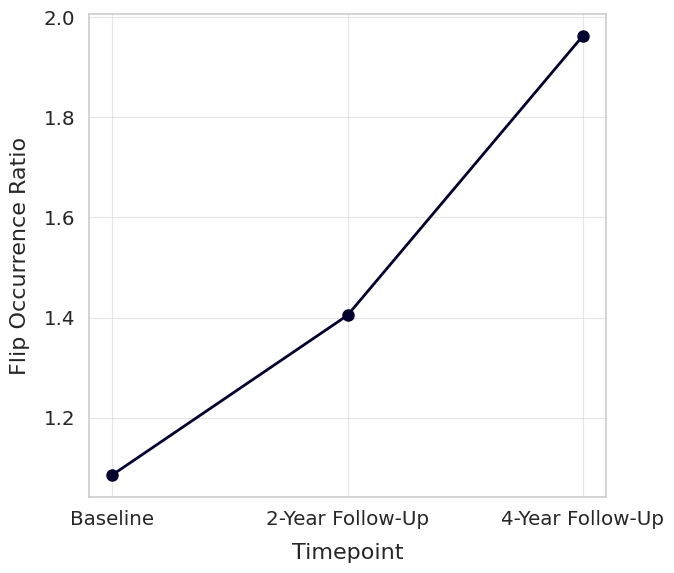

In [169]:

# --- Data setup ---
timepoints = ["Baseline", "2-Year Follow-Up", "4-Year Follow-Up"]

data = [
    flip_occurence_ratio_baseline,
    flip_occurence_ratio_fu2y,
    flip_occurence_ratio_fu4y
]

# --- Style setup (match your other figures) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Create figure and axis ---
fig, ax = plt.subplots(figsize=(7, 6))

# --- Plot line ---
x = np.arange(len(timepoints))
ax.plot(
    x, data,
    marker='o',
    markersize=8,
    color='xkcd:midnight',
    linewidth=2
)

# --- Axis formatting ---
ax.set_xticks(x)
ax.set_xticklabels(timepoints)
ax.set_xlabel("Timepoint", fontsize=16, labelpad=10)
ax.set_ylabel("Flip Occurrence Ratio", fontsize=16, labelpad=10)
ax.grid(True, linestyle='-', linewidth=0.8, alpha=0.5)
#sns.despine()

plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir_fig + "lineplot_flip_occurrence_ratio.svg", format="svg", bbox_inches="tight", dpi=300)
plt.show()
